# Modelo SARIMAX - PBI Electricidad y Agua con precio del cobre e ICEN (BCRP / ENFEN)

### Docente: Dr. Richard Fernández

### Comprensión del negocio

**Objetivo de negocio:** identificar patrones históricos de la producción del sector Electricidad y Agua del Perú y medir cómo influyen en ella dos factores **externos al sector**: el ciclo minero (a través del precio internacional del cobre) y el clima (a través del fenómeno El Niño Costero). Con ello se busca generar estimaciones que apoyen la planificación de la inversión en infraestructura eléctrica y de agua, y la toma de decisiones de política económica.

**Objetivo de minería de datos:** desarrollar un modelo predictivo **SARIMAX**, siguiendo la metodología de Box-Jenkins, que pronostique el **índice del PBI de Electricidad y Agua** (y, a partir de él, su variación porcentual interanual) usando como variables exógenas el **precio del cobre** y el **Índice Costero El Niño (ICEN)**, y compararlo con los modelos AR, MA, ARMA y SARIMA vistos en el curso. Además, se comparan modelos de **Machine Learning** (XGBoost, LightGBM y CatBoost) entrenados con las variables del notebook 01 del curso, un **AutoML de H2O** y redes neuronales recurrentes (**LSTM, GRU y sus versiones bidireccionales**, entrenadas en GPU), para ver si superan al SARIMAX.

### Comprensión de los datos

| Rol | Serie | Fuente / código | Transformación | Por qué se usa |
|---|---|---|---|---|
| Serie a pronosticar ($y_t$) | PBI Electricidad y Agua (índice 2007 = 100) | BCRP `PN01765AM` | **Logaritmo** ($100 \cdot \ln$) y luego diferenciación | Es la serie de estudio, en niveles. Su variación interanual es la serie `PN01723AM` del BCRP. |
| Exógena 1 ($x_{1t}$) | Precio del cobre LME (¢US$/lb) | BCRP `PN01652XM` | **Logaritmo** ($100 \cdot \ln$) | La gran minería es el mayor consumidor de electricidad del Perú; un cobre caro impulsa la producción y la demanda de energía. Es un precio internacional: **no forma parte del cálculo del PBI del sector**. |
| Exógena 2 ($x_{2t}$) | Índice Costero El Niño (ICEN, °C) | ENFEN / IGP (`ICEN.txt`) | Ninguna (es una anomalía con valores negativos: no admite logaritmo) | Variable climática: El Niño trae calor (más consumo de agua y aire acondicionado), lluvias y huaicos (daños a redes y plantas de agua) y cambios en la generación hidroeléctrica. **No depende de la economía.** |

El fundamento de las dos exógenas, con fuentes, está en la sección 6.2.

Frecuencia mensual. Se trabaja con el **índice en niveles** (y no con la variación %) porque el logaritmo solo existe para valores positivos: el índice siempre es positivo, mientras que la variación % toma valores negativos.

### Metodología Box-Jenkins

| Paso | Sección |
|---|---|
| Ploteo de la serie | 3 |
| **Transformación logarítmica** (estabilizar la varianza) | 3.2 |
| Ploteo de la FAC y FACP | 4.1 |
| ¿Es la serie estacionaria? (ADF y KPSS) | 4.2 |
| Diferenciación regular y estacional (si no es estacionaria se vuelve a la FAC y FACP) | 4.2 y 4.3 |
| Identificación del modelo | 6.1 |
| Fundamento de las variables exógenas (con fuentes) y selección del rezago | 6.2 |
| Estimación de parámetros | 6.1 y 6.3 |
| ¿Son los residuales no correlacionados? (Ljung–Box; si no, se vuelve a la identificación) | 6.1 y 8 |
| Pronóstico y contraste con los valores reales (tabla de métricas) | 7 |
| Ploteo de los residuales y de su FAC y FACP | 8 |
| Actualizar la serie y pronosticar a futuro | 7 y 9 |
| Cuartiles y deciles (análisis descriptivo) | 3.4 |
| Modelos XGBoost, LightGBM y CatBoost con las variables del notebook 01 | 10 |
| AutoML con H2O | 11 |
| Comparación final: econometría, boosting y AutoML (incluye la tabla consolidada de los 14 modelos) | 12 |
| Detección de anomalías con Isolation Forest (H2O): contraste con la regla del IQR y con la pandemia | 13 |
| Deep Learning: LSTM, GRU y bidireccionales con 5 épocas en GPU (notebook 12) y tabla consolidada con todos los modelos | 14 |

## 1. Librerías

In [1]:
import io
import warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.graphics.gofplots import qqplot
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '1'   # GridSearchCV corre en un solo proceso; evita un aviso de joblib en Windows

alpha = 0.05

## 2. Llamado a los datasets

Las series se descargan directamente de sus fuentes oficiales: la API de BCRPData (índice del PBI, su variación % y el cobre) y el archivo oficial del ICEN publicado por el IGP para el ENFEN. El periodo final es fijo (julio 2026) para que los datos no cambien en cada ejecución.

**Nota de reproducibilidad:** el BCRP revisa sus cifras y el ICEN de los últimos meses es provisional (es una media móvil centrada que usa el mes siguiente). Una nueva ejecución puede dar números algo distintos a los que se comentan en este notebook.

In [2]:
MESES = {'Ene': 1, 'Feb': 2, 'Mar': 3, 'Abr': 4, 'May': 5, 'Jun': 6, 'Jul': 7,
         'Ago': 8, 'Sep': 9, 'Set': 9, 'Oct': 10, 'Nov': 11, 'Dic': 12}
FIN = '2026-07-01'

def descargar_bcrp(codigo, inicio='1994-1', fin='2026-7'):
    url = f'https://estadisticas.bcrp.gob.pe/estadisticas/series/api/{codigo}/json/{inicio}/{fin}'
    datos = requests.get(url, timeout=60).json()
    fechas = [pd.Timestamp(int(p['name'][-4:]), MESES[p['name'][:3]], 1) for p in datos['periods']]
    valores = pd.to_numeric([p['values'][0] for p in datos['periods']], errors='coerce')
    return pd.Series(valores, index=pd.DatetimeIndex(fechas), name=datos['config']['series'][0]['name']).asfreq('MS')

def descargar_icen():
    texto = requests.get('http://met.igp.gob.pe/datos/ICEN.txt', timeout=60).text
    tabla = pd.read_csv(io.StringIO(texto), comment='%', sep=r'\s+', header=None, names=['anio', 'mes', 'icen'])
    fechas = pd.to_datetime(dict(year=tabla['anio'], month=tabla['mes'], day=1))
    return pd.Series(tabla['icen'].values, index=fechas, name='ICEN (°C)').asfreq('MS')[:FIN]

indice = descargar_bcrp('PN01765AM')
variacion = descargar_bcrp('PN01723AM', inicio='1995-1')
cobre = descargar_bcrp('PN01652XM', inicio='1990-1')
icen = descargar_icen()

for nombre, s in [('Índice PBI Electricidad y Agua', indice), ('Variación % interanual', variacion),
                  ('Precio del cobre', cobre), ('ICEN', icen)]:
    s = s.dropna()
    print(f'{nombre:<32} {s.index.min():%Y-%m} a {s.index.max():%Y-%m} ({len(s)} datos)')

control = (100 * (indice / indice.shift(12) - 1) - variacion).abs().max()
print(f'\nControl: la variación interanual calculada con el índice coincide con PN01723AM (diferencia máxima {control:.1e})')

Índice PBI Electricidad y Agua   1994-01 a 2026-07 (391 datos)
Variación % interanual           1995-01 a 2026-07 (379 datos)
Precio del cobre                 2000-01 a 2026-07 (319 datos)
ICEN                             1950-01 a 2026-07 (919 datos)

Control: la variación interanual calculada con el índice coincide con PN01723AM (diferencia máxima 5.2e-14)


## 3. Dataset y preparación

### 3.1. Tratamiento de la pandemia

Los meses de marzo 2020 a junio 2021 (confinamiento y rebote) son muy atípicos y se reemplazan. Como se trabaja con el índice en niveles, la imputación debe **empalmar** con los datos reales a ambos lados del hueco. Después de la pandemia, el índice no recuperó el crecimiento perdido: en julio 2021 estaba apenas ≈ 1 % por encima de julio 2019. Si se imputara con el crecimiento "normal" de cada mes, el tramo imputado quedaría muy por encima y se crearía una caída artificial en julio 2021.

Procedimiento, en logaritmos:
1. Se estima la **estacionalidad típica** de cada mes con los datos previos a la pandemia (1994–2019).
2. Se le quita esa estacionalidad a la serie (nivel desestacionalizado).
3. En los meses de pandemia, el nivel desestacionalizado se **interpola linealmente** entre febrero 2020 y julio 2021.
4. Se vuelve a sumar la estacionalidad típica de cada mes.

Las variables exógenas **no** se imputan: el cobre y el ICEN son fenómenos externos y sus valores en la pandemia son reales.

In [3]:
pandemia = pd.date_range('2020-03-01', '2021-06-01', freq='MS')

def imputar_pandemia(indice):
    z = np.log(indice)
    estacional = seasonal_decompose(z[:'2019-12-01'], model='additive', period=12).seasonal
    factor = estacional.groupby(estacional.index.month).mean()
    desestacionalizado = z - factor.reindex(z.index.month).values
    desestacionalizado[pandemia] = np.nan
    desestacionalizado = desestacionalizado.interpolate(method='linear')
    z_imputado = z.copy()
    z_imputado[pandemia] = desestacionalizado[pandemia] + factor.reindex(pandemia.month).values
    return np.exp(z_imputado)

indice_original = indice
indice = imputar_pandemia(indice_original)
display(pd.DataFrame({'Original': indice_original[pandemia].values, 'Imputado': indice[pandemia].values},
                     index=pandemia.strftime('%Y-%m')).round(1).T)
ventana = slice('2019-06-01', '2021-12-01')
print('Empalme: julio 2021 (real) vs julio 2019 (real):',
      f"{100 * (indice['2021-07-01'] / indice['2019-07-01'] - 1):.1f} % en dos años")

,2020-03,2020-04,2020-05,2020-06,2020-07,2020-08,2020-09,2020-10,2020-11,2020-12,2021-01,2021-02,2021-03,2021-04,2021-05,2021-06
Original,167.3,134.3,145.4,158.3,172.1,176.8,173.2,183.7,180.4,188.3,188.2,171.8,190.8,179.9,186.8,182.2
Imputado,196.3,187.3,191.7,183.8,187.3,188.2,182.7,187.9,183.6,189.3,191.0,176.9,192.8,183.9,188.3,180.4


Empalme: julio 2021 (real) vs julio 2019 (real): 1.5 % en dos años


### 3.2. Transformación logarítmica

La serie se transforma con $z_t = 100 \cdot \ln(\text{índice}_t)$ **antes** de decidir la diferenciación. El logaritmo:

1. **Estabiliza la varianza.** En niveles, las oscilaciones estacionales crecen a medida que el índice crece (de ≈ 90 a ≈ 220). En logaritmos pasan a ser proporcionales y su tamaño se mantiene estable.
2. **Convierte las diferencias en tasas de crecimiento.** $z_t - z_{t-1}$ es el crecimiento mensual y $z_t - z_{t-12}$ el crecimiento interanual, ambos en % aproximado. Por eso se multiplica por 100.
3. **Garantiza pronósticos positivos.** Al deshacer la transformación con $e^{z/100}$, el índice pronosticado nunca es negativo.

El precio del cobre también se transforma con $100 \cdot \ln$, así que su coeficiente se lee como una **elasticidad**. El ICEN no se transforma porque toma valores negativos.

La muestra empieza en **enero 2002**: se prueban rezagos de hasta 12 meses en las exógenas y el cobre está disponible desde enero 2000.

In [4]:
inicio_muestra = pd.Timestamp('2002-01-01')
indice, indice_original = indice[inicio_muestra:], indice_original[inicio_muestra:]
serie = (100 * np.log(indice)).rename('100·ln(índice)')
cobre_log = (100 * np.log(cobre)).rename('100·ln(cobre)')

datos = pd.concat([indice.rename('Índice PBI Electricidad y Agua'), serie, cobre.rename('Cobre (¢US$/lb)'),
                   cobre_log, icen], axis=1).loc[serie.index]
print('Periodo analizado:', serie.index.min().strftime('%Y-%m'), 'a', serie.index.max().strftime('%Y-%m'))
print('Observaciones:', len(serie), '| Meses faltantes:', int(datos.isna().sum().sum()))
datos.head()

Periodo analizado: 2002-01 a 2026-07
Observaciones: 295 | Meses faltantes: 0


,Índice PBI Electricidad y Agua,100·ln(índice),Cobre (¢US$/lb),100·ln(cobre),ICEN (°C)
2002-01-01,73.848950,430.202180,68.317815,422.417057,-0.59
2002-02-01,67.923322,421.837945,70.822439,426.017589,0.04
2002-03-01,76.399231,433.597262,72.964869,428.997808,0.57
2002-04-01,74.077018,430.510533,72.147475,427.871229,0.81
2002-05-01,74.849184,431.547520,72.391864,428.209392,0.67


In [5]:
estadisticas = datos.describe().T
estadisticas['asimetría'] = datos.skew()
estadisticas['curtosis'] = datos.kurtosis()
estadisticas.round(4)

,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis
Índice PBI Electricidad y Agua,295.0,143.6768,44.9616,67.9233,104.9551,143.5390,184.3873,222.6123,-0.0579,-1.3374
100·ln(índice),295.0,491.3497,33.8655,421.8379,465.3523,496.6607,521.7036,540.5432,-0.3972,-1.1543
Cobre (¢US$/lb),295.0,300.7683,115.1068,67.0919,233.8466,311.7185,376.3649,615.7207,-0.1513,0.0356
100·ln(cobre),295.0,560.4987,50.1440,420.6064,545.4651,574.2100,593.0559,642.2793,-1.3294,1.2558
ICEN (°C),295.0,-0.0331,0.9530,-1.6600,-0.7200,-0.1500,0.4700,3.3800,0.8916,0.8374


**¿El logaritmo estabiliza la varianza?** Se mide, por año, la dispersión de los datos mensuales alrededor de su promedio anual: en niveles (desviación estándar del índice) y en logaritmos (desviación estándar de $100\cdot\ln$, que equivale a una dispersión en %).

,Promedio del índice,Desv. estándar en niveles,Desv. estándar en logaritmos (%)
2002,73.55,2.52,3.47
2006,91.55,3.29,3.62
2010,116.75,3.76,3.27
2014,145.77,3.78,2.62
2018,174.98,5.52,3.19
2022,192.52,6.53,3.42
2026,217.20,5.84,2.74


Correlación entre el nivel del índice y su dispersión anual:
  en niveles:     0.859
  en logaritmos:  -0.330


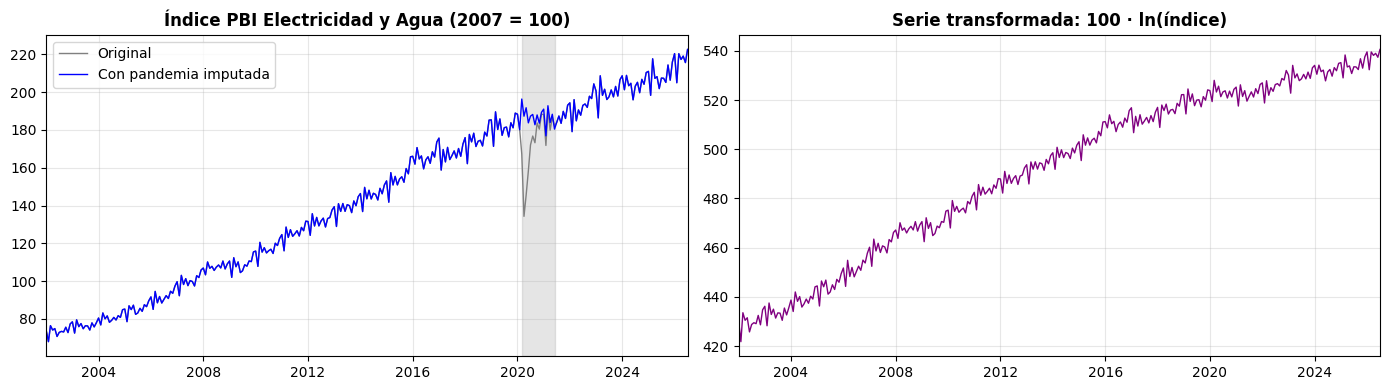

In [6]:
por_anio = pd.DataFrame({
    'Promedio del índice': indice.groupby(indice.index.year).mean(),
    'Desv. estándar en niveles': indice.groupby(indice.index.year).std(),
    'Desv. estándar en logaritmos (%)': serie.groupby(serie.index.year).std(),
})
display(por_anio.iloc[::4].round(2))
print('Correlación entre el nivel del índice y su dispersión anual:')
print(f'  en niveles:     {por_anio.iloc[:, 0].corr(por_anio.iloc[:, 1]):.3f}')
print(f'  en logaritmos:  {por_anio.iloc[:, 0].corr(por_anio.iloc[:, 2]):.3f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(indice_original, color='gray', linewidth=1, label='Original')
axes[0].plot(indice, color='blue', linewidth=1, label='Con pandemia imputada')
axes[0].axvspan(pandemia[0], pandemia[-1], color='gray', alpha=0.2)
axes[0].set_title('Índice PBI Electricidad y Agua (2007 = 100)', fontweight='bold'); axes[0].legend()
axes[1].plot(serie, color='purple', linewidth=1)
axes[1].set_title('Serie transformada: 100 · ln(índice)', fontweight='bold')
for ax in axes:
    ax.grid(alpha=0.3); ax.set_xlim(serie.index.min(), serie.index.max())
plt.tight_layout(); plt.show()

### 3.3. Ploteo de la serie y de las variables exógenas

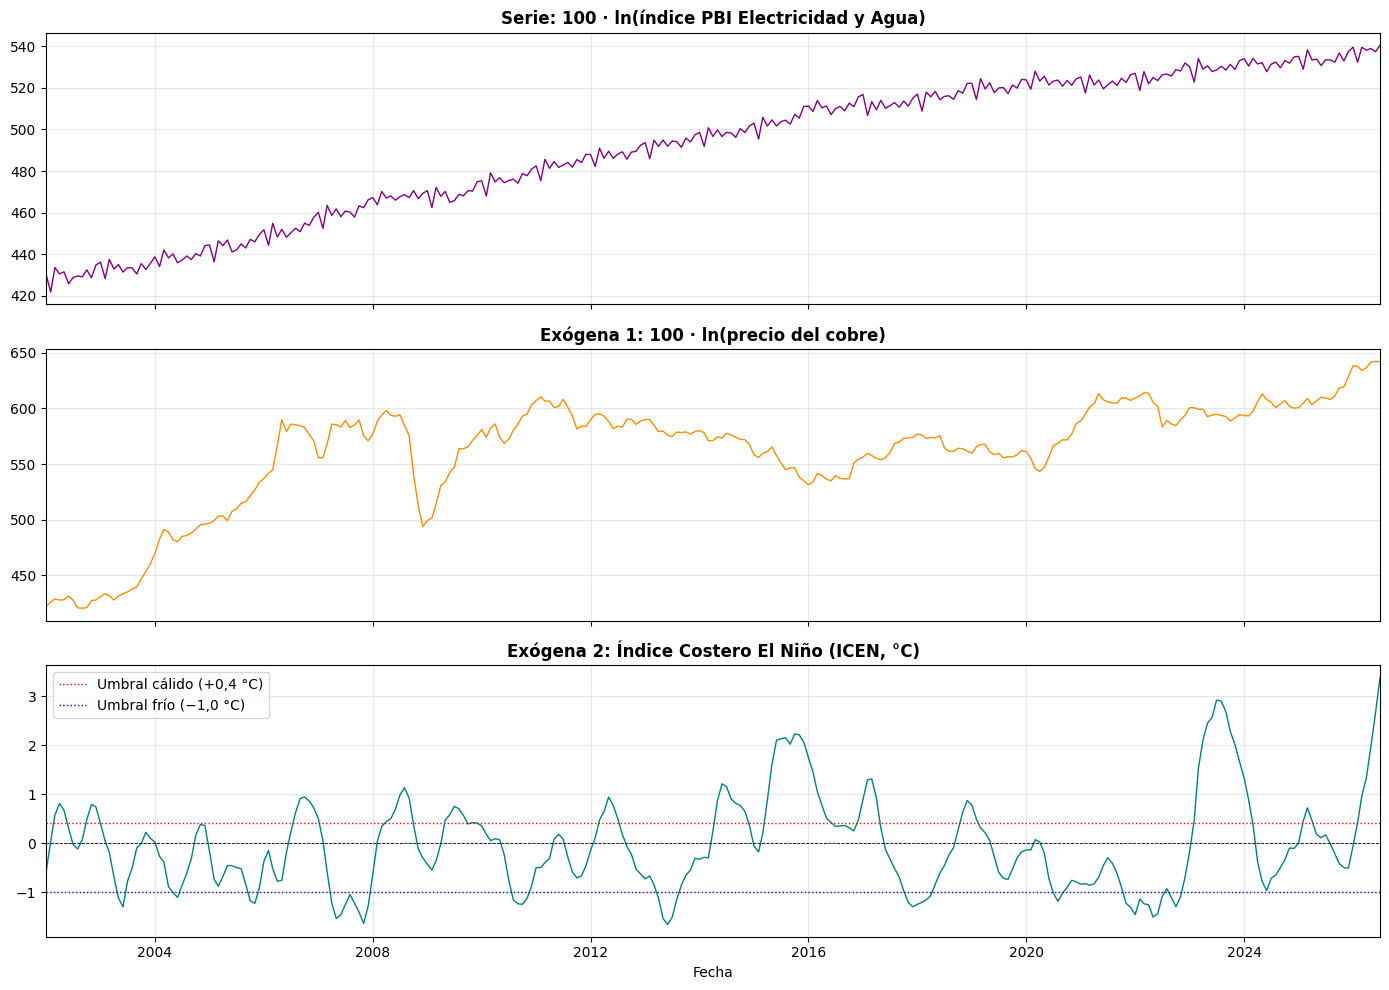

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
axes[0].plot(serie, color='purple', linewidth=1)
axes[0].set_title('Serie: 100 · ln(índice PBI Electricidad y Agua)', fontweight='bold')
axes[1].plot(cobre_log[serie.index], color='darkorange', linewidth=1)
axes[1].set_title('Exógena 1: 100 · ln(precio del cobre)', fontweight='bold')
axes[2].plot(icen[serie.index], color='teal', linewidth=1)
axes[2].axhline(0.4, color='red', linestyle=':', linewidth=1, label='Umbral cálido (+0,4 °C)')
axes[2].axhline(-1.0, color='blue', linestyle=':', linewidth=1, label='Umbral frío (−1,0 °C)')
axes[2].axhline(0, linestyle='--', color='black', linewidth=0.6)
axes[2].set_title('Exógena 2: Índice Costero El Niño (ICEN, °C)', fontweight='bold'); axes[2].legend(loc='upper left')
for ax in axes:
    ax.grid(alpha=0.3)
axes[-1].set_xlim(serie.index.min(), serie.index.max()); axes[-1].set_xlabel('Fecha')
plt.tight_layout(); plt.show()

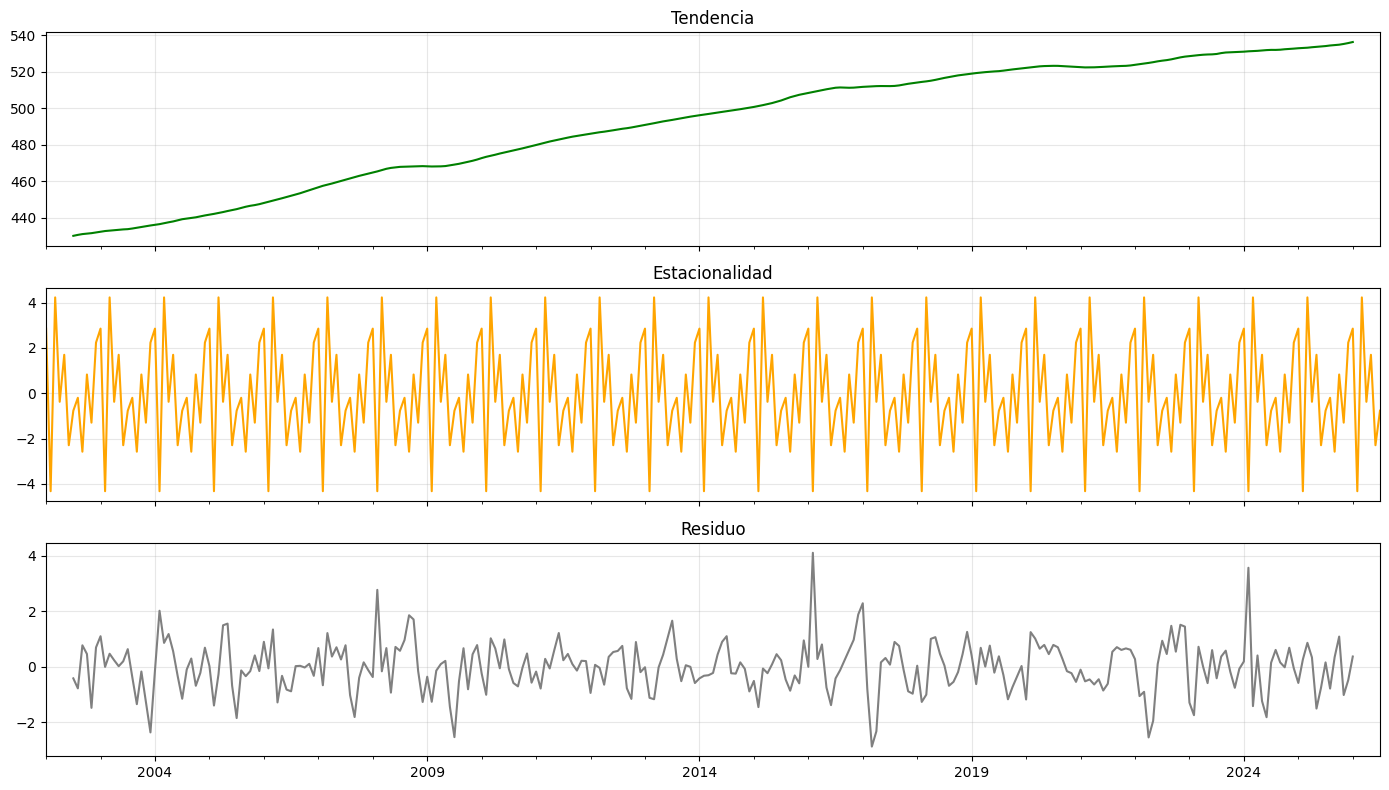

In [8]:
descomposicion = seasonal_decompose(serie, model='additive', period=12)

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
descomposicion.trend.plot(ax=axes[0], color='green', title='Tendencia')
descomposicion.seasonal.plot(ax=axes[1], color='orange', title='Estacionalidad')
descomposicion.resid.plot(ax=axes[2], color='gray', title='Residuo')
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretación de los gráficos**

- **Índice del PBI de Electricidad y Agua:** casi se triplica entre 2002 (promedio 73,6) y 2026 (217,2), un crecimiento cercano a 4,6 % anual. Tiene una **tendencia creciente** clara y un patrón **estacional** marcado; el más visible es la caída de cada febrero, que tiene menos días de producción.
- **Efecto del logaritmo:** en niveles, la dispersión de los meses dentro de cada año crece con el índice (de 2,5 puntos en 2002 a 6,5 en 2022). La correlación entre nivel y dispersión es de 0,86. En logaritmos, la dispersión se mantiene entre 2,6 % y 3,6 % y la correlación baja a −0,33. El logaritmo **estabilizó la varianza**: la estacionalidad pasa de crecer con el nivel (multiplicativa) a tener un tamaño constante (aditiva).
- **Cobre:** se mueve entre 67 y 616 ¢US$/lb, con grandes ciclos: el boom de 2006–2007, el desplome de 2009, el máximo de 2011 y el alza de 2021 y 2026.
- **ICEN:** marca los eventos El Niño Costero (sobre +0,4 °C), como los de 2015–2016, 2017 y 2023. A julio 2026 llega a **3,38 °C**, el valor más alto de la muestra, lo que indica un **El Niño Costero fuerte en curso**.
- **Descomposición:** la tendencia de la serie en logaritmos crece de forma casi lineal y la estacionalidad tiene un tamaño estable, lo que confirma que el modelo aditivo es adecuado después del logaritmo.

### 3.4. Cuartiles y deciles

Los **cuantiles** dividen un conjunto de datos **ordenado de menor a mayor** en partes con la misma cantidad de observaciones. Son medidas de **posición**: indican dónde se ubica un valor respecto del resto. A diferencia de la media y la desviación estándar, casi no se ven afectados por los valores extremos.

**Cuartiles:** dividen los datos en 4 partes iguales (25 % en cada una).

| Medida | Deja por debajo | Lectura |
|---|---|---|
| Q1 (primer cuartil, percentil 25) | 25 % de los datos | Límite del cuarto más bajo |
| Q2 (mediana, percentil 50) | 50 % | Valor central; no se mueve con los atípicos |
| Q3 (tercer cuartil, percentil 75) | 75 % | Límite del cuarto más alto |

- **Rango intercuartílico:** IQR = Q3 − Q1. Es el ancho del 50 % central de los datos, una medida de dispersión robusta.
- **Regla de Tukey para atípicos** (la del notebook 01 del curso): es atípico todo valor menor que Q1 − 1,5·IQR o mayor que Q3 + 1,5·IQR. Son los puntos que el **diagrama de caja (boxplot)** dibuja fuera de los "bigotes".

**Deciles:** dividen los datos en 10 partes iguales (10 % en cada una). D1 deja por debajo el 10 % de los datos, D2 el 20 %, …, D9 el 90 %. Dan una imagen más fina que los cuartiles: D1 y D9 marcan los valores excepcionalmente bajos y altos sin recurrir a la regla de 1,5·IQR.

**Equivalencias:** Q1 = P25, **Q2 = D5 = P50 = mediana** y Q3 = P75. En general, el cuantil de orden *p* deja por debajo una proporción *p* de los datos.

**Cálculo.** Con los *n* datos ordenados $x_{(1)} \le \dots \le x_{(n)}$, pandas (`quantile`) ubica el cuantil *p* en la posición $h = (n-1)\,p + 1$ y, si cae entre dos datos, **interpola linealmente**. Con 295 datos, la mediana es el dato 148 y Q1 está en la posición 74,5 (entre los datos 74 y 75). Excel y otras opciones de `numpy` usan reglas algo distintas, así que pueden dar valores ligeramente diferentes.

**Cuidado en series de tiempo.** Los cuantiles describen la distribución **sin tener en cuenta el orden temporal**. En una serie con tendencia, como el índice, los valores bajos son los años antiguos y los altos los recientes: los cuartiles del nivel describen *épocas*, no meses normales o anormales. Por eso conviene aplicarlos a una versión **estacionaria** de la serie, como la variación % interanual o el crecimiento mensual.

In [9]:
variacion_muestra = variacion[inicio_muestra:]
variables_desc = pd.DataFrame({'Índice PBI Electricidad y Agua': indice_original,
                               'Variación % interanual (BCRP)': variacion_muestra,
                               'Cobre (¢US$/lb)': cobre[inicio_muestra:FIN],
                               'ICEN (°C)': icen[inicio_muestra:FIN]})

cuartiles = variables_desc.quantile([0.25, 0.50, 0.75]).T
cuartiles.columns = ['Q1 (P25)', 'Q2 = mediana (P50)', 'Q3 (P75)']
cuartiles['IQR = Q3 − Q1'] = cuartiles['Q3 (P75)'] - cuartiles['Q1 (P25)']
cuartiles['Media'] = variables_desc.mean()
print('Cuartiles (2002-01 a 2026-07, datos reales sin imputar):')
display(cuartiles.round(2))

deciles = variables_desc.quantile(np.arange(0.1, 1.0, 0.1)).T
deciles.columns = [f'D{i}' for i in range(1, 10)]
print('Deciles:')
display(deciles.round(2))

# ¿En qué decil cae el último dato (julio 2026)?
ultimo = variables_desc.iloc[-1]
decil_ultimo = pd.DataFrame({'Último dato (2026-07)': ultimo,
                             'Decil': [int(np.searchsorted(deciles.loc[v].values, ultimo[v], side='right')) + 1
                                       for v in variables_desc.columns],
                             'Percentil empírico (%)': [100 * (variables_desc[v] <= ultimo[v]).mean()
                                                        for v in variables_desc.columns]})
print('Posición del último dato (decil 1 = 10 % más bajo; decil 10 = 10 % más alto):')
display(decil_ultimo.round(2))

Cuartiles (2002-01 a 2026-07, datos reales sin imputar):


,Q1 (P25),Q2 = mediana (P50),Q3 (P75),IQR = Q3 − Q1,Media
Índice PBI Electricidad y Agua,104.96,143.45,181.35,76.40,142.96
Variación % interanual (BCRP),3.06,4.99,6.83,3.77,4.79
Cobre (¢US$/lb),233.85,311.72,376.36,142.52,300.77
ICEN (°C),-0.72,-0.15,0.47,1.19,-0.03


Deciles:


,D1,D2,D3,D4,D5,D6,D7,D8,D9
Índice PBI Electricidad y Agua,80.19,94.58,109.28,127.92,143.45,164.20,175.88,187.87,202.57
Variación % interanual (BCRP),0.95,2.55,3.63,4.44,4.99,5.67,6.50,7.23,8.47
Cobre (¢US$/lb),130.05,213.13,259.53,285.94,311.72,337.50,361.97,386.11,432.43
ICEN (°C),-1.16,-0.84,-0.62,-0.39,-0.15,0.07,0.37,0.65,1.10


Posición del último dato (decil 1 = 10 % más bajo; decil 10 = 10 % más alto):


,Último dato (2026-07),Decil,Percentil empírico (%)
Índice PBI Electricidad y Agua,222.61,10,100.00
Variación % interanual (BCRP),7.30,9,81.69
Cobre (¢US$/lb),613.49,10,99.66
ICEN (°C),3.38,10,100.00


,Límite inferior,Límite superior,N.º de atípicos,% de atípicos
Serie,,,,
"Índice (nivel, con tendencia)",-9.64,295.95,0,0.00
Variación % interanual (estacionaria),-2.59,12.48,12,4.07


Meses atípicos de la variación % interanual (regla 1,5·IQR):


,2016-02,2020-03,2020-04,2020-05,2020-06,2020-07,2020-08,2021-02,2021-03,2021-04,2021-05,2021-06
Var. %,14.2,-11.8,-25.5,-21.7,-10.6,-5.0,-2.6,-4.6,14.0,34.0,28.5,15.1


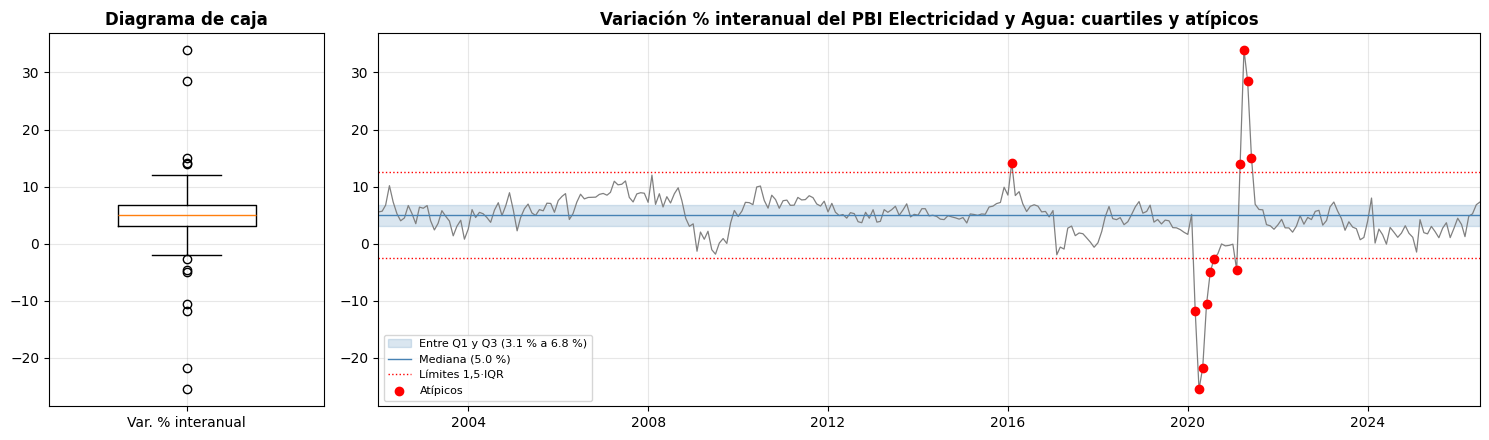

In [10]:
def atipicos_iqr(x):
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return inferior, superior, x[(x < inferior) | (x > superior)]

filas = []
for nombre, x in [('Índice (nivel, con tendencia)', indice_original), ('Variación % interanual (estacionaria)', variacion_muestra)]:
    inferior, superior, fuera = atipicos_iqr(x)
    filas.append({'Serie': nombre, 'Límite inferior': inferior, 'Límite superior': superior,
                  'N.º de atípicos': len(fuera), '% de atípicos': 100 * len(fuera) / len(x)})
display(pd.DataFrame(filas).set_index('Serie').round(2))

inferior, superior, atipicos_var = atipicos_iqr(variacion_muestra)
print('Meses atípicos de la variación % interanual (regla 1,5·IQR):')
display(atipicos_var.round(1).to_frame('Var. %').T.rename(columns=lambda f: f.strftime('%Y-%m')))

q1, q2, q3 = variacion_muestra.quantile([0.25, 0.5, 0.75])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [1, 4]})
axes[0].boxplot(variacion_muestra, widths=0.5)
axes[0].set_xticks([1], ['Var. % interanual'])
axes[0].set_title('Diagrama de caja', fontweight='bold')
axes[1].plot(variacion_muestra, color='gray', linewidth=0.9)
axes[1].axhspan(q1, q3, color='steelblue', alpha=0.2, label=f'Entre Q1 y Q3 ({q1:.1f} % a {q3:.1f} %)')
axes[1].axhline(q2, color='steelblue', linewidth=1, label=f'Mediana ({q2:.1f} %)')
axes[1].axhline(inferior, color='red', linestyle=':', linewidth=1, label='Límites 1,5·IQR')
axes[1].axhline(superior, color='red', linestyle=':', linewidth=1)
axes[1].scatter(atipicos_var.index, atipicos_var, color='red', zorder=3, label='Atípicos')
axes[1].set_title('Variación % interanual del PBI Electricidad y Agua: cuartiles y atípicos', fontweight='bold')
axes[1].legend(loc='lower left', fontsize=8)
axes[1].set_xlim(variacion_muestra.index.min(), variacion_muestra.index.max())
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Crecimiento mensual (%, 100·Δln índice) por mes del año:


,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Set,Oct,Nov,Dic
Q1,0.36,-7.92,8.62,-4.81,1.61,-4.26,1.30,0.26,-2.48,3.28,-2.37,3.13
Mediana,1.08,-7.47,9.11,-4.33,2.36,-3.72,2.04,0.89,-1.98,3.65,-1.57,3.86
Q3,1.50,-6.20,10.28,-3.09,3.07,-2.94,2.68,1.57,-1.70,4.27,-1.15,4.54
IQR,1.14,1.72,1.66,1.72,1.46,1.32,1.38,1.31,0.79,1.00,1.23,1.41


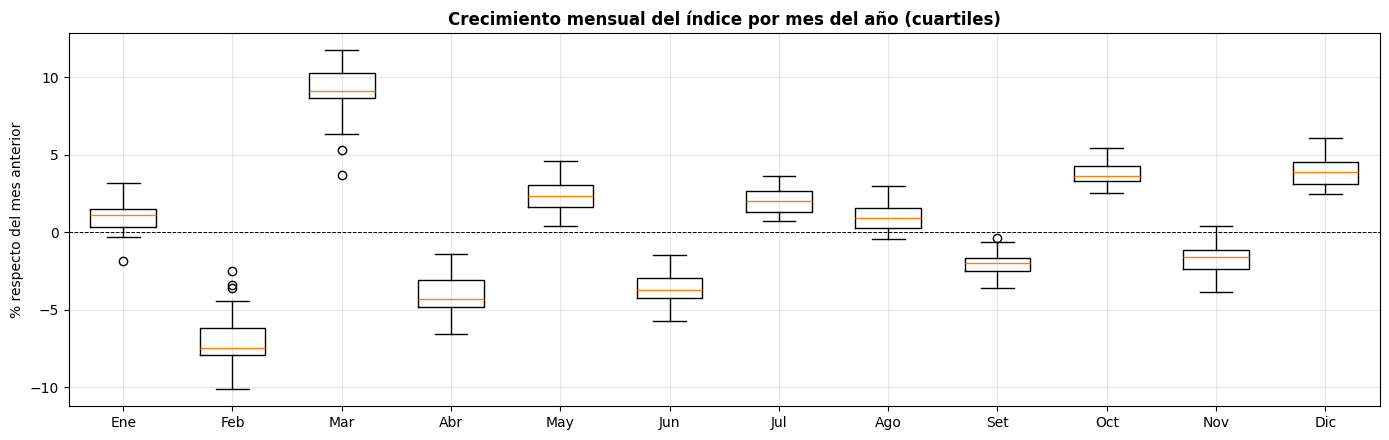

In [11]:
# Cuartiles del crecimiento mensual por mes del año (serie con la pandemia imputada)
crecimiento_mensual = (100 * np.log(indice).diff()).dropna()
nombres_mes = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Set', 'Oct', 'Nov', 'Dic']
por_mes = crecimiento_mensual.groupby(crecimiento_mensual.index.month)
cuartiles_mes = por_mes.quantile([0.25, 0.5, 0.75]).unstack()
cuartiles_mes.columns = ['Q1', 'Mediana', 'Q3']
cuartiles_mes['IQR'] = cuartiles_mes['Q3'] - cuartiles_mes['Q1']
cuartiles_mes.index = nombres_mes
print('Crecimiento mensual (%, 100·Δln índice) por mes del año:')
display(cuartiles_mes.T.round(2))

plt.figure(figsize=(14, 4.5))
plt.boxplot([grupo.values for _, grupo in por_mes], widths=0.6)
plt.xticks(range(1, 13), nombres_mes)
plt.axhline(0, color='black', linestyle='--', linewidth=0.7)
plt.title('Crecimiento mensual del índice por mes del año (cuartiles)', fontweight='bold')
plt.ylabel('% respecto del mes anterior'); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretación de cuartiles y deciles**

- **Variación % interanual:** la mediana es 4,99 % y la mitad central de los meses crece entre 3,06 % (Q1) y 6,83 % (Q3), un IQR de 3,77 pp. La media (4,79 %) queda algo por debajo de la mediana porque los meses de la pandemia, muy negativos, la jalan hacia abajo; la mediana no se ve afectada. Por deciles, en el 10 % de los peores meses el sector creció menos de 0,95 % (D1) y en el 10 % de los mejores, más de 8,47 % (D9).
- **Atípicos con la regla 1,5·IQR:** en la variación % interanual hay 12 meses (4,1 %) fuera de los límites −2,59 % y 12,48 %. Once están en el periodo imputado en la sección 3.1: el confinamiento (marzo–agosto 2020, hasta −25,5 % en abril) y el rebote (febrero–junio 2021, hasta +34,0 % en abril). Esto respalda la decisión de imputar ese tramo. El otro es febrero 2016 (+14,2 %), probablemente influido por el año bisiesto (un día más de producción que febrero 2015).
- **Índice en niveles:** la regla no marca ningún atípico. Los límites (−9,6 y 296,0) quedan muy lejos de los datos porque la tendencia ensancha el IQR (76,4 puntos). Los cuartiles del nivel separan épocas: Q1 = 105 corresponde a niveles de 2007–2008 y Q3 = 181 a niveles de 2019. Es el mismo problema de aplicar la regla al precio de Bitcoin en el notebook 01: en una serie con tendencia, los cuantiles deben calcularse sobre su versión estacionaria.
- **Posición del último dato (julio 2026):** el índice (222,6) y el ICEN (3,38 °C) son el máximo de toda la muestra (decil 10, percentil 100) y el cobre (613,5 ¢US$/lb) está en el percentil 99,7. La variación interanual (7,30 %) está en el decil 9: es un crecimiento alto, pero no excepcional (D9 = 8,47 %). Para el índice esto es esperable por la tendencia; para el cobre y el ICEN no: ambos están en valores extremos, lo que da peso a sus efectos en el pronóstico de la sección 9.
- **Crecimiento mensual por mes del año:** las cajas casi no se superponen. Febrero siempre cae (mediana −7,5 %) y marzo siempre sube (+9,1 %). Además, los meses de 30 días (abril, junio, setiembre y noviembre) caen y los de 31 días suben: la estacionalidad es, sobre todo, un **efecto calendario** del número de días. El IQR dentro de cada mes es pequeño (0,8 a 1,7 pp) frente a las diferencias entre meses (de −7,5 % a +9,1 %): la estacionalidad es muy estable, lo que coincide con el MA estacional cercano a −1 de la sección 6.1.

## 4. Identificación y estacionariedad

### 4.1. FAC y FACP de la serie en logaritmos

| Modelo sobre la serie estacionaria | FAC | FACP |
|---|---|---|
| AR(p) | Decae gradualmente | Corte después de p |
| MA(q) | Corte después de q | Decae gradualmente |
| ARMA(p,q) | Decae gradualmente | Decae gradualmente |

Una FAC que decae muy lento indica que la serie **no es estacionaria** y hay que diferenciarla. Si además los rezagos 12, 24 y 36 se mantienen altos, la estacionalidad tampoco es estacionaria y se necesita una **diferencia estacional**. Se usa solo el tramo de entrenamiento.

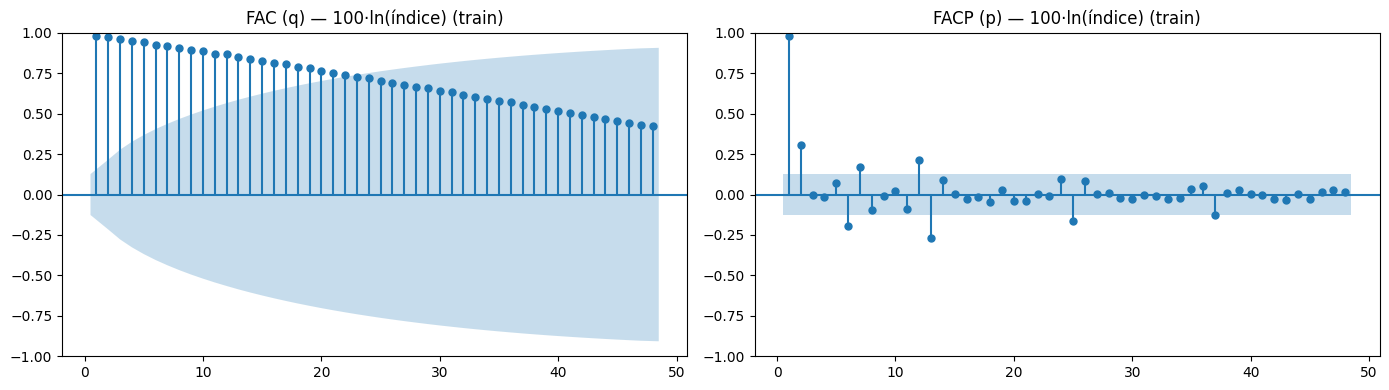

In [12]:
inicio_test = pd.Timestamp('2022-01-01')

def graficar_fac(x, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    plot_acf(x, lags=48, zero=False, ax=axes[0], title=f'FAC (q) — {titulo}')
    plot_pacf(x, lags=48, zero=False, method='ywm', ax=axes[1], title=f'FACP (p) — {titulo}')
    plt.tight_layout(); plt.show()

graficar_fac(serie[serie.index < inicio_test], '100·ln(índice) (train)')

### 4.2. ¿Es la serie estacionaria? Diferenciación regular y estacional

Se evalúan cuatro versiones de la serie en logaritmos: sin diferenciar, con primera diferencia (**d = 1**, crecimiento mensual), con diferencia estacional (**D = 1**, crecimiento interanual) y con ambas. Para cada una:

- **ADF:** H₀ = no es estacionaria (raíz unitaria). Se busca **p < 0,05**.
- **KPSS:** H₀ = es estacionaria. Se busca **p ≥ 0,05**. Es el complemento del ADF: una serie es claramente estacionaria cuando ambas pruebas coinciden.
- **FAC en el rezago 12:** si es mayor a 0,5, queda una estacionalidad no estacionaria que el ADF no detecta.

Se elige la versión con **menos diferencias** que cumple los tres criterios. Las pruebas se hacen solo con train.

In [13]:
def evaluar(x):
    x = x.dropna()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        p_kpss = kpss(x, regression='c', nlags='auto')[1]
    p_adf = adfuller(x, autolag='AIC')[1]
    fac12 = acf(x, nlags=12)[12]
    cumple = p_adf < alpha and p_kpss >= alpha and fac12 < 0.5
    return {'p-valor ADF': p_adf, 'p-valor KPSS': p_kpss, 'FAC rezago 12': fac12,
            'Conclusión': 'Estacionaria' if cumple else 'No estacionaria'}

train_log = serie[serie.index < inicio_test]
transformaciones = {
    (0, 0): ('Logaritmo (d=0, D=0)', train_log),
    (1, 0): ('Logaritmo + 1.ª diferencia (d=1, D=0)', train_log.diff()),
    (0, 1): ('Logaritmo + diferencia estacional (d=0, D=1)', train_log.diff(12)),
    (1, 1): ('Logaritmo + ambas diferencias (d=1, D=1)', train_log.diff().diff(12)),
}
pruebas_est = pd.DataFrame({nombre: evaluar(x) for nombre, x in transformaciones.values()}).T
display(pruebas_est.style.format({'p-valor ADF': '{:.4f}', 'p-valor KPSS': '{:.4f}', 'FAC rezago 12': '{:.4f}'}))

d, D = next(clave for clave, (nombre, x) in transformaciones.items() if evaluar(x)['Conclusión'] == 'Estacionaria')
print(f'Orden de diferenciación elegido: d = {d}, D = {D} (s = 12)')

,p-valor ADF,p-valor KPSS,FAC rezago 12,Conclusión
"Logaritmo (d=0, D=0)",0.4168,0.0100,0.8679,No estacionaria
"Logaritmo + 1.ª diferencia (d=1, D=0)",0.0115,0.1000,0.8746,No estacionaria
"Logaritmo + diferencia estacional (d=0, D=1)",0.1417,0.0171,-0.0055,No estacionaria
"Logaritmo + ambas diferencias (d=1, D=1)",0.0000,0.1000,-0.4709,Estacionaria


Orden de diferenciación elegido: d = 1, D = 1 (s = 12)


### 4.3. Serie transformada y su FAC y FACP

Se grafican las cuatro versiones y la FAC/FACP de la serie elegida, que es la que se usa para identificar los órdenes p, q, P y Q.

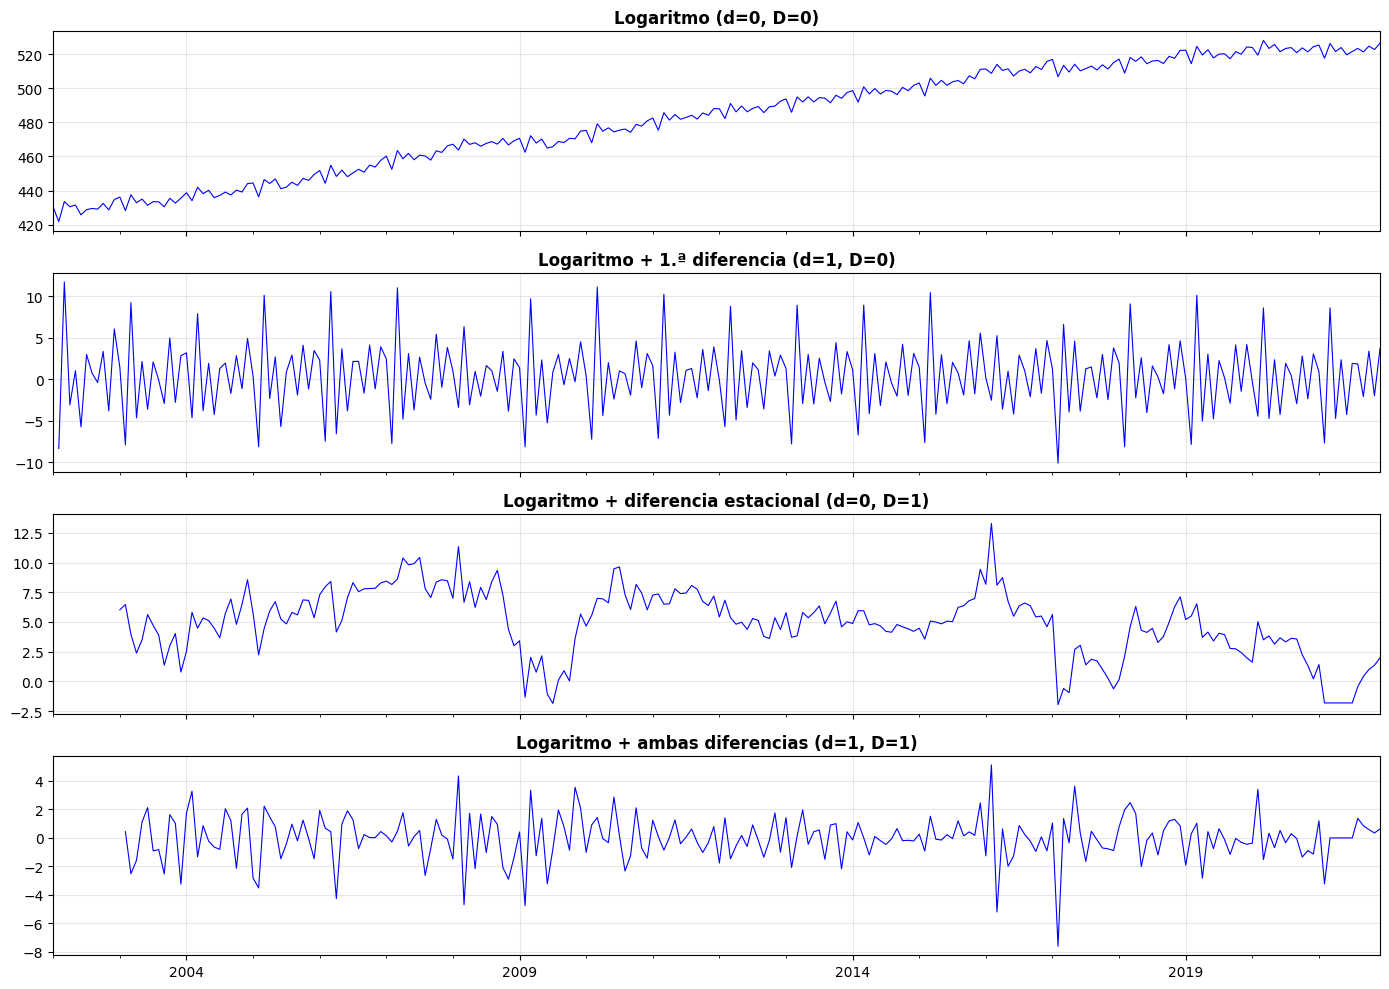

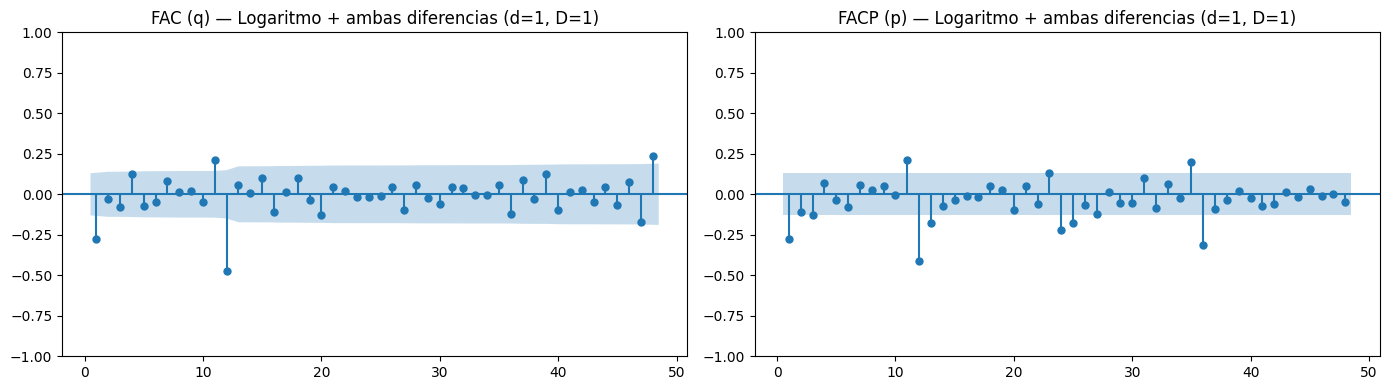

In [14]:
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for (nombre, x), ax in zip(transformaciones.values(), axes):
    x.dropna().plot(ax=ax, color='blue', linewidth=0.8)
    ax.set_title(nombre, fontweight='bold'); ax.grid(alpha=0.3)
axes[0].set_xlim(train_log.index.min(), train_log.index.max())
plt.tight_layout(); plt.show()

estacionaria_train = transformaciones[(d, D)][1].dropna()
graficar_fac(estacionaria_train, transformaciones[(d, D)][0])

**Interpretación de la estacionariedad y la FAC/FACP**

- **Logaritmo sin diferenciar:** no es estacionario. El ADF no rechaza la raíz unitaria (p = 0,42), el KPSS rechaza la estacionariedad (p = 0,01) y la FAC decae muy lento, por la tendencia.
- **Primera diferencia (d = 1):** el ADF ya la acepta (p = 0,012), pero la FAC en el rezago 12 es **0,87**. Queda una estacionalidad no estacionaria que el ADF no detecta, así que se necesita también la diferencia estacional.
- **Solo diferencia estacional (D = 1):** equivale al crecimiento interanual. Todavía no es estacionaria (ADF p = 0,14; KPSS p = 0,017).
- **Ambas diferencias (d = 1 y D = 1):** cumple los tres criterios (ADF p < 0,001, KPSS p = 0,10 y FAC₁₂ = −0,47). Se elige **d = 1 y D = 1**.
- **FAC y FACP de la serie diferenciada:** la FAC tiene picos negativos aislados en el **rezago 1** y en el **rezago 12**, y casi nada más. Eso indica un **MA(1)** regular y un **MA(1) estacional**. La FACP decae en los rezagos 1–3 y 12–13, lo que es consistente con términos MA. Es el patrón del clásico **"modelo de aerolínea"** de Box y Jenkins, SARIMA(0,1,1)(0,1,1)₁₂.

Notas sobre los criterios:
- El p-valor del KPSS de 0,10 es el límite superior de su tabla: significa **p ≥ 0,10**, no exactamente 0,10.
- El umbral FAC₁₂ < 0,5 es un criterio práctico de este trabajo, no una prueba formal. Una alternativa formal para decidir la diferencia estacional son las pruebas OCSB o Canova–Hansen (por ejemplo, `nsdiffs` de `pmdarima`).

## 5. División de la muestra en train y test

El test empieza en enero de 2022, después de los meses imputados de la pandemia (marzo 2020 – junio 2021), para evaluar los modelos solo con datos reales.

In [15]:
train, test = serie[serie.index < inicio_test], serie[serie.index >= inicio_test]
indice_test = indice[test.index]

print('Train:', train.index.min().strftime('%Y-%m'), 'a', train.index.max().strftime('%Y-%m'), f'({len(train)} datos, {len(train) / len(serie):.0%})')
print('Test: ', test.index.min().strftime('%Y-%m'), 'a', test.index.max().strftime('%Y-%m'), f'({len(test)} datos, {len(test) / len(serie):.0%})')

Train: 2002-01 a 2021-12 (240 datos, 81%)
Test:  2022-01 a 2026-07 (55 datos, 19%)


## 6. Identificación del modelo y estimación de parámetros

### 6.1. Modelos univariados: AR, MA, ARMA y SARIMA

Las diferencias elegidas (d y D) van **dentro** del modelo, como en el notebook 05 de SARIMA del curso. Sobre la serie diferenciada se prueban:

- **AR(p)**: SARIMA(p,d,0)(0,D,0)₁₂.
- **MA(q)**: SARIMA(0,d,q)(0,D,0)₁₂.
- **ARMA(p,q)**: SARIMA(p,d,q)(0,D,0)₁₂.
- **SARIMA**: además, términos estacionales AR (P) o MA (Q) en el rezago 12.

Como todos usan la misma transformación y las mismas diferencias, su AIC y BIC son comparables. Criterio: el menor **BIC** entre los modelos cuyos residuos **pasan Ljung–Box** (rezagos 12 y 24, descontando los parámetros estimados). Un modelo con residuos correlacionados se descarta y se vuelve a la identificación.

In [16]:
tendencia = 'n' if d + D >= 2 else 't' if d + D == 1 else 'c'

def ajustar(datos_y, orden, estacional, exog=None):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return ARIMA(datos_y, exog=exog, order=orden, seasonal_order=estacional,
                     trend=tendencia).fit(method_kwargs={'maxiter': 500})

def n_param(orden, estacional):
    return orden[0] + orden[2] + estacional[0] + estacional[2]

def familia(orden, estacional):
    if estacional[0] + estacional[2] > 0:
        return 'SARIMA'
    return 'AR' if orden[2] == 0 else 'MA' if orden[0] == 0 else 'ARMA'

def nombre_modelo(orden, estacional):
    return f'{familia(orden, estacional)}{orden}{estacional[:3]}12'

def residuos_validos(m):
    return m.resid.iloc[d + 12 * D:]

ordenes = [((p, d, q), (P, D, Q, 12)) for p in range(4) for q in range(4) for P in range(2) for Q in range(2)
           if p + q + P + Q > 0 and (P + Q == 0 or p + q <= 4)]

modelos, resultados = {}, []
for orden, estacional in ordenes:
    clave = nombre_modelo(orden, estacional)
    try:
        ajuste = ajustar(train, orden, estacional)
    except (ValueError, np.linalg.LinAlgError):
        continue
    if not ajuste.mle_retvals.get('converged', True) or not np.isfinite(ajuste.bic):
        continue
    lb = acorr_ljungbox(residuos_validos(ajuste), lags=[12, 24], model_df=n_param(orden, estacional))['lb_pvalue']
    modelos[clave] = (orden, estacional)
    resultados.append({'Modelo': clave, 'Familia': familia(orden, estacional), 'AIC': ajuste.aic, 'BIC': ajuste.bic,
                       'p-Ljung-Box(12)': lb.iloc[0], 'p-Ljung-Box(24)': lb.iloc[1]})

comparacion = pd.DataFrame(resultados).sort_values('BIC').reset_index(drop=True)
comparacion['Pasa Ljung-Box'] = np.where(comparacion[['p-Ljung-Box(12)', 'p-Ljung-Box(24)']].min(axis=1) >= alpha, 'Sí', 'No')
print(f'Modelos estimados: {len(comparacion)}. Se muestran los 15 de menor BIC:')
display(comparacion.head(15).round(4))

Modelos estimados: 54. Se muestran los 15 de menor BIC:


,Modelo,Familia,AIC,BIC,p-Ljung-Box(12),p-Ljung-Box(24),Pasa Ljung-Box
0,"SARIMA(0, 1, 1)(0, 1, 1)12",SARIMA,714.9946,725.2694,0.4032,0.4536,Sí
1,"SARIMA(0, 1, 2)(0, 1, 1)12",SARIMA,715.5613,729.2611,0.5073,0.5776,Sí
2,"SARIMA(1, 1, 0)(0, 1, 1)12",SARIMA,719.1460,729.4208,0.0803,0.1050,Sí
3,"SARIMA(1, 1, 1)(0, 1, 1)12",SARIMA,715.7611,729.4609,0.4579,0.5221,Sí
4,"SARIMA(0, 1, 1)(1, 1, 1)12",SARIMA,715.8040,729.5038,0.2877,0.3119,Sí
5,"SARIMA(2, 1, 0)(0, 1, 1)12",SARIMA,716.9140,730.6138,0.4265,0.5438,Sí
6,"SARIMA(3, 1, 0)(0, 1, 1)12",SARIMA,715.6124,732.7372,0.5441,0.6331,Sí
7,"SARIMA(0, 1, 2)(1, 1, 1)12",SARIMA,716.2871,733.4118,0.4105,0.4351,Sí
8,"SARIMA(1, 1, 1)(1, 1, 1)12",SARIMA,716.5305,733.6553,0.3476,0.3743,Sí
9,"SARIMA(1, 1, 0)(1, 1, 1)12",SARIMA,720.0839,733.7837,0.0399,0.0511,No


In [17]:
# Mejor modelo de cada familia (se prefiere el que pasa Ljung-Box y, entre ellos, el de menor BIC)
mejores = (comparacion.sort_values(['Pasa Ljung-Box', 'BIC'], ascending=[False, True])
           .groupby('Familia', sort=False).head(1).set_index('Familia').loc[['AR', 'MA', 'ARMA', 'SARIMA']])
display(mejores.round(4))

nombre_sarima = mejores.loc['SARIMA', 'Modelo']
orden, estacional = modelos[nombre_sarima]
k = n_param(orden, estacional)
modelo_sarima = ajustar(train, orden, estacional)
print(f'Orden base para el SARIMAX: {nombre_sarima}')
display(pd.DataFrame({'Coeficiente': modelo_sarima.params, 'p-valor': modelo_sarima.pvalues}).round(4))

,Modelo,AIC,BIC,p-Ljung-Box(12),p-Ljung-Box(24),Pasa Ljung-Box
Familia,,,,,,
AR,"AR(1, 1, 0)(0, 1, 0)12",847.2539,854.1038,0.0000,0.0000,No
MA,"MA(0, 1, 1)(0, 1, 0)12",843.3857,850.2356,0.0000,0.0000,No
ARMA,"ARMA(2, 1, 3)(0, 1, 0)12",831.5784,852.1281,0.0000,0.0000,No
SARIMA,"SARIMA(0, 1, 1)(0, 1, 1)12",714.9946,725.2694,0.4032,0.4536,Sí


Orden base para el SARIMAX: SARIMA(0, 1, 1)(0, 1, 1)12


,Coeficiente,p-valor
ma.L1,-0.3098,0.0
ma.S.L12,-0.9319,0.0
sigma2,1.1985,0.0


**Interpretación de la identificación**

- Se estimaron 54 modelos. Ninguno de los modelos **AR, MA o ARMA sin términos estacionales** pasa Ljung–Box (p = 0,000), porque sus residuos conservan la autocorrelación del rezago 12. Según Box-Jenkins no son válidos.
- El mejor modelo es **SARIMA(0,1,1)(0,1,1)₁₂**, el "modelo de aerolínea", tal como anticipaban la FAC y la FACP. Tiene el menor BIC (725,3), muy por debajo del mejor ARMA (852,1), y sus residuos son ruido blanco (Ljung–Box p = 0,40 y 0,45). Este orden se usa como base del SARIMAX.
- **MA(1) = −0,31:** el crecimiento mensual corrige parcialmente el shock del mes anterior.
- **MA estacional = −0,93:** es muy cercano a −1, lo que indica que el patrón estacional es casi **determinístico** (se repite igual cada año). Con la diferencia estacional, el modelo lo reproduce de forma estable. Un coeficiente tan cerca de −1 también puede indicar que la diferencia estacional es excesiva (casi se cancela con el MA estacional). Una alternativa sería usar d = 1 con variables indicadoras de cada mes (estacionalidad determinística); aquí se mantiene D = 1 porque el modelo es invertible y sus residuos pasan Ljung–Box.
- **Sin constante:** con d = 1 y D = 1 la constante se elimina al diferenciar. El crecimiento de largo plazo queda recogido en las diferencias.

### 6.2. Variables exógenas: fundamento y selección del rezago

#### a) ¿Por qué el precio del cobre y el ICEN?

Se usaron tres criterios para elegir las variables exógenas:

1. **Externas al sector.** No deben formar parte del cálculo del PBI de Electricidad y Agua. El INEI calcula este sector con los **volúmenes físicos** de producción de electricidad, gas y agua ([INEI, Informe Técnico N.° 05, marzo 2017, cuadro 14](https://www.inei.gob.pe/media/MenuRecursivo/boletines/05-informe-tecnico-n05_produccion-nacional-mar2017.pdf)). Por eso se descartaron otros sectores del PBI, la demanda interna y la producción eléctrica en GWh: forman parte del propio PBI o se usan para calcularlo.
2. **Canal causal documentado** por fuentes oficiales, académicas o periodísticas especializadas.
3. **Datos mensuales oficiales** desde 2000 que se puedan usar para pronosticar, ya sea con rezago o con pronósticos publicados.

Se evaluaron también el tipo de cambio, el IPC, las expectativas empresariales y la temperatura de Lima. Se descartaron porque su canal hacia la producción de electricidad y agua es más indirecto o porque se superponen con el ICEN.

**1. Precio del cobre (LME, ¢US$/lb; BCRP `PN01652XM`)**

| Argumento | Evidencia | Fuente |
|---|---|---|
| La minería es el mayor consumidor de electricidad del Perú | Los clientes libres mineros concentran más del 54 % del consumo de los clientes libres. Su participación en el consumo total pasó de 24 % a 34,1 % entre 2013 y 2022, y en la máxima demanda, de 18,1 % (2013) a 28,4 % (2023) | [BCRP, Revista *Moneda* N.° 198: "El vínculo entre minería, energía e industria en el Perú"](https://www.bcrp.gob.pe/docs/Publicaciones/Revista-Moneda/moneda-198/moneda-198-13.pdf) |
| La demanda eléctrica sigue a la producción minera | En 2023 la demanda eléctrica minera tocó su máximo con la entrada en operación de la mina de cobre Quellaveco; al agotarse ese efecto, el consumo eléctrico de minas e industrias cayó | [Gestión, 22/12/2023](https://gestion.pe/economia/consumo-electrico-de-industrias-y-minas-cae-en-ultimos-dos-meses-y-seguiria-en-baja-el-2024-noticia/) |
| La demanda minera sigue creciendo | Según el COES, la máxima demanda del sector minero pasó de 2 050,8 MW (junio 2024) a 2 182,9 MW (junio 2026), +6,4 % | [Energiminas, 10/08/2026](https://energiminas.com/?p=49601) |
| El precio del cobre mueve la inversión minera con retraso | El BCR explica que la inversión minera se decide con expectativas de precios de mediano y largo plazo; con el cobre por encima de US$ 2,80–3,00 por libra, la mayoría de proyectos es rentable | [Andina, 13/07/2018](https://andina.pe/ingles/noticia-bcr-exploraciones-mineras-son-rentables-peru-cobre-a-280-libra-716479.aspx) |
| Los precios de los metales mueven la economía peruana | Los choques externos explican alrededor del 60 % de la varianza de las variables domésticas, y un alza de los precios de los minerales es un choque favorable de oferta y demanda | [Ganiko y Jiménez (2023), *Revista Estudios Económicos* N.° 43, BCRP](https://www.bcrp.gob.pe/docs/Publicaciones/Revista-Estudios-Economicos/43/ree-43-ganiko-jimenez.pdf) |

**Canal esperado:** un cobre más caro impulsa la producción y las ampliaciones mineras (con meses de retraso), lo que eleva la demanda de electricidad. Se espera un **efecto positivo y rezagado**, coherente con lo estimado más abajo: elasticidad positiva con 7 meses de rezago.

**2. Índice Costero El Niño (ICEN, °C; ENFEN/IGP)**

| Argumento | Evidencia | Fuente |
|---|---|---|
| Es el indicador oficial de El Niño costero en el Perú | El ENFEN lo estableció en 2012 para determinar de forma operativa El Niño y La Niña en la costa del Perú y su magnitud. Usa la región Niño 1+2, ligada a los impactos locales en la costa (la región Niño 3.4 refleja impactos remotos). Requiere datos con al menos un mes de retraso | [Takahashi (2015), IGP, *Boletín Técnico* Vol. 2 N.° 3](https://repositorio.igp.gob.pe/bitstreams/11a1226e-4f5a-4990-97fa-c4be061da3fc/download); [datos del ICEN](http://met.igp.gob.pe/datos/ICEN.txt) |
| El Niño costero reduce la producción de agua | Marzo 2017: el subsector agua cayó 8,18 % y la producción de Sedapal 9,99 % por menor actividad de sus plantas de tratamiento; hubo distritos de Lima sin agua durante cuatro días | [INEI, Informe Técnico N.° 05, marzo 2017](https://www.inei.gob.pe/media/MenuRecursivo/boletines/05-informe-tecnico-n05_produccion-nacional-mar2017.pdf) |
| | Abril 2017: el sector Electricidad, Gas y Agua cayó 1,55 %, con la producción de agua en −8,11 % "por el Fenómeno de El Niño costero" | [INEI, Nota de prensa N.° 126, 15/06/2017](https://m.inei.gob.pe/media/MenuRecursivo/noticias/nota-de-prensa-n126-2017-inei.pdf) |
| Daña la infraestructura | Los huaicos elevaron la turbidez del río Rímac y obligaron a Sedapal a restringir el agua de Lima; en el país colapsaron 159 puentes y se destruyeron 1 909 km de carreteras y 614 km de canales | [Circle of Blue, 21/03/2017](https://www.circleofblue.org/2017/water-climate/heavy-rains-unleash-mudslides-destruction-peru/) |
| Afecta la generación hidroeléctrica | El presidente del COES advirtió que un Niño que cause sequía en el centro y sur del país afectaría la generación hidroeléctrica y obligaría a usar centrales a diésel | [Gestión, 06/06/2023](https://gestion.pe/economia/el-nino-podria-volver-a-contraer-la-produccion-con-hidroelectricas-este-ano-noticia/) |
| | En 2023 la generación hidroeléctrica cayó 2,3 %, aunque el sector creció 3,68 % gracias a la generación térmica | [INEI, Nota de prensa N.° 018-2024](https://m.inei.gob.pe/media/MenuRecursivo/noticias/nota-de-prensa-n-018-2024-inei.pdf) |
| Es un riesgo vigente | En setiembre 2026 el BCRP elevó la intensidad esperada de El Niño a "extraordinario" y estimó un impacto de 0,9 % del PBI en 2026 y de 1,1 % en 2027 | [La Cámara, 18/09/2026, sobre el Reporte de Inflación del BCRP](https://lacamara.pe/peru-reduce-crecimiento-a-32-por-el-nino-y-preve-mayor-inflacion-este-ano/) |

**Canal esperado:** El Niño costero trae lluvias y huaicos en la costa, que dañan captaciones y plantas de agua, y puede traer sequía en el centro y sur, que reduce la generación hidroeléctrica. Se espera un **efecto negativo**, que puede aparecer con retraso. La celda siguiente revisa en los datos qué pasó con el sector después de los dos últimos eventos fuertes.

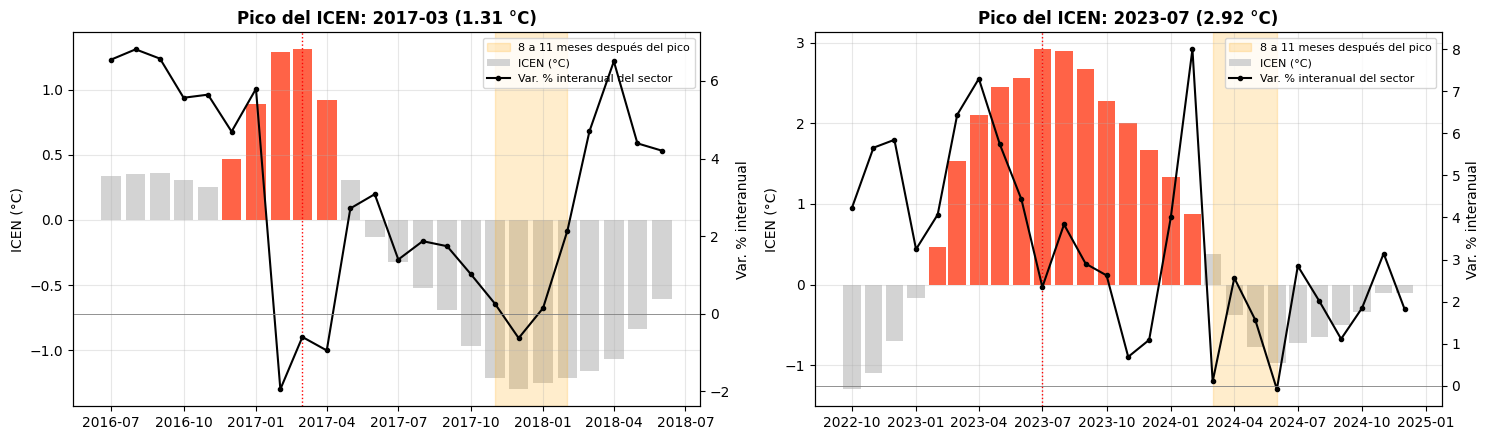

,Promedio 2002–2019,2017,2018,2023,2024
Var. % interanual promedio,5.53,1.15,4.4,3.73,2.41


In [18]:
# ICEN y crecimiento del sector alrededor de los eventos El Niño costero de 2017 y 2023 (datos BCRP / IGP)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (inicio, fin) in zip(axes, [('2016-07-01', '2018-06-01'), ('2022-10-01', '2024-12-01')]):
    tramo = slice(inicio, fin)
    pico = icen[tramo].idxmax()
    ax.bar(icen[tramo].index, icen[tramo], width=25, color=np.where(icen[tramo] > 0.4, 'tomato', 'lightgray'), label='ICEN (°C)')
    ax2 = ax.twinx()
    ax2.plot(variacion[tramo], color='black', marker='o', markersize=3, label='Var. % interanual del sector')
    ax2.axhline(0, color='gray', linewidth=0.6)
    ax.axvline(pico, color='red', linestyle=':', linewidth=1)
    ax.axvspan(pico + pd.DateOffset(months=8), pico + pd.DateOffset(months=11), color='orange', alpha=0.2,
               label='8 a 11 meses después del pico')
    ax.set_title(f'Pico del ICEN: {pico:%Y-%m} ({icen[pico]:.2f} °C)', fontweight='bold')
    ax.set_ylabel('ICEN (°C)'); ax2.set_ylabel('Var. % interanual')
    lineas = ax.get_legend_handles_labels(); lineas2 = ax2.get_legend_handles_labels()
    ax.legend(lineas[0] + lineas2[0], lineas[1] + lineas2[1], loc='upper right', fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

resumen_eventos = pd.DataFrame({
    'Promedio 2002–2019': variacion['2002':'2019'].mean(),
    '2017': variacion['2017'].mean(), '2018': variacion['2018'].mean(),
    '2023': variacion['2023'].mean(), '2024': variacion['2024'].mean()}, index=['Var. % interanual promedio'])
display(resumen_eventos.round(2))

**Lectura de la evidencia**

- **2017:** el ICEN llegó a su máximo en marzo 2017 (1,31 °C). El sector cayó de inmediato (−1,9 % en febrero, −0,6 % en marzo y −0,9 % en abril, por la menor producción de agua que reporta el INEI) y volvió a quedar casi sin crecimiento entre noviembre 2017 y enero 2018 (0,26 %, −0,63 % y 0,15 %), de 8 a 10 meses después del pico. El año 2017 promedió 1,2 %, frente a 5,5 % en 2002–2019.
- **2023:** el ICEN llegó a su máximo en julio 2023 (2,92 °C). Ese año el sector **creció** 3,7 % (el INEI lo atribuye a la generación térmica, que compensó la caída hidroeléctrica). La desaceleración llegó después: noviembre 2023 (0,69 %), marzo 2024 (0,10 %) y junio 2024 (−0,08 %), entre 4 y 11 meses después del pico. El promedio de 2024 fue 2,4 %.
- En ambas ventanas el ICEN ya era negativo (condiciones frías), así que la caída no se explica por un Niño en curso. Es compatible con un efecto rezagado, aunque otros factores también pudieron influir.
- Es decir, además del golpe inmediato a la producción de agua, hay un **efecto que aparece meses después**. Esto respalda usar el ICEN rezagado, aunque con solo dos eventos fuertes la duración exacta del rezago (10 meses, elegida por BIC en el punto b) debe tomarse con cautela. Posibles explicaciones son el tiempo que toma reparar captaciones y redes, y el efecto de la sequía sobre los reservorios de las hidroeléctricas en la siguiente temporada seca.

#### b) Selección del rezago

El efecto de las exógenas no tiene por qué ser inmediato: un alza del cobre tarda meses en traducirse en más producción minera, y El Niño afecta el consumo y la infraestructura con retraso. Por eso se prueban rezagos de 0 a 12 meses.

En un SARIMAX con diferencias, la regresión se plantea en niveles, $z_t = \beta\, x_{t-L} + u_t$, y el modelo diferencia por igual a la serie y a la exógena. Por eso:

1. La **correlación cruzada** se calcula entre la serie y la exógena **con las mismas diferencias** (d, D), solo en train.
2. Para cada rezago se estima un **SARIMAX con una sola exógena** y el orden base de la sección 6.1, y se registra el BIC, el coeficiente y su p-valor. Se elige el rezago con **menor BIC**.

Usar un rezago tiene una ventaja práctica: con la exógena rezagada *L* meses, los primeros *L* meses del pronóstico usan valores **ya observados**.

Nota: el ICEN es una media móvil centrada de 3 meses (usa el mes siguiente), así que el rezago 0 no estaría disponible al momento de pronosticar; un rezago ≥ 1 sí lo está.

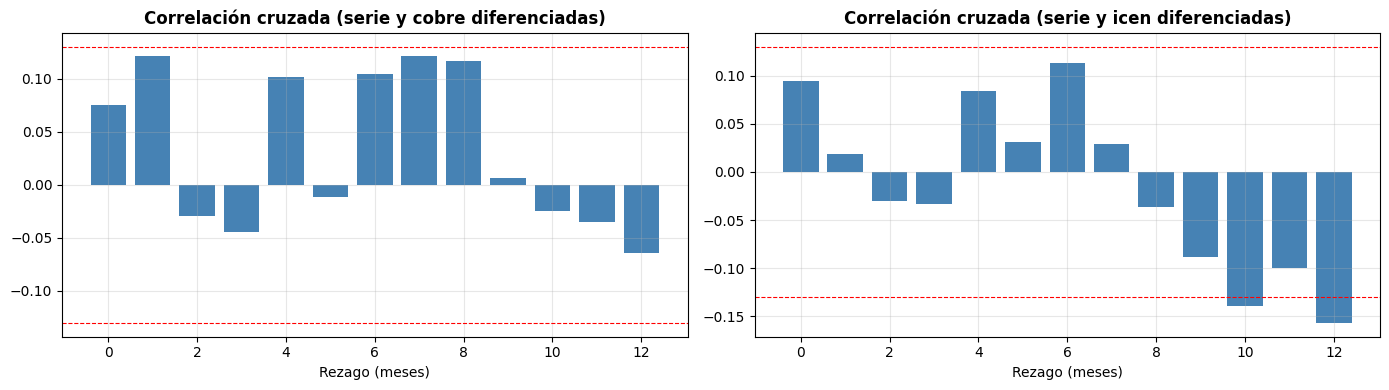

BIC           Coeficiente         p-valor        
Variable     cobre      icen       cobre    icen   cobre    icen
Rezago                                                          
0         730.3343  728.9298      0.0054  0.2553  0.5030  0.1307
1         729.6716  729.7812      0.0091  0.1848  0.2748  0.2806
2         730.5961  730.4643      0.0028  0.0938  0.7229  0.6212
3         730.6698  730.2737      0.0014  0.1265  0.8612  0.5322
4         729.9110  727.6647      0.0080  0.3334  0.4198  0.1115
5         729.5697  728.1133      0.0096  0.3080  0.4222  0.1577
6         728.1491  728.5568      0.0143  0.2812  0.1670  0.2027
7         725.8293  730.6660      0.0195  0.0325  0.0528  0.8762
8         728.9014  729.9450      0.0120 -0.1670  0.2434  0.3959
9         730.2949  727.7488      0.0057 -0.3283  0.5353  0.0485
10        730.6907  724.9905      0.0005 -0.4530  0.9488  0.0028
11        730.3591  725.6589     -0.0053 -0.4256  0.5666  0.0074
12        729.2795  728.1137     -0.0107 -0.3071  0.2284  0.0757

Rezago elegido (menor BIC):


,Rezago,BIC,Δ BIC vs sin exógena,Coeficiente,p-valor
Variable,,,,,
cobre,7,725.8293,0.5599,0.0195,0.0528
icen,10,724.9905,-0.2789,-0.4530,0.0028


In [19]:
def diferenciar(x):
    x = x.diff(1) if d else x
    return x.diff(12) if D else x

exogenas = {'cobre': cobre_log, 'icen': icen}
rezagos = range(0, 13)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
y_dif = diferenciar(serie)[train.index].dropna()
banda = 1.96 / np.sqrt(len(y_dif))
for ax, (variable, x) in zip(axes, exogenas.items()):
    x_dif = diferenciar(x)
    corr = [y_dif.corr(x_dif.shift(L).loc[y_dif.index]) for L in rezagos]
    ax.bar(list(rezagos), corr, color='steelblue')
    ax.axhline(banda, color='red', linestyle='--', linewidth=0.8); ax.axhline(-banda, color='red', linestyle='--', linewidth=0.8)
    ax.set_title(f'Correlación cruzada (serie y {variable} diferenciadas)', fontweight='bold')
    ax.set_xlabel('Rezago (meses)'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

filas = []
for variable, x in exogenas.items():
    for L in rezagos:
        m = ajustar(train, orden, estacional, exog=x.shift(L).loc[train.index].rename(variable))
        filas.append({'Variable': variable, 'Rezago': L, 'BIC': m.bic, 'Δ BIC vs sin exógena': m.bic - modelo_sarima.bic,
                      'Coeficiente': m.params[variable], 'p-valor': m.pvalues[variable]})
busqueda = pd.DataFrame(filas)
rezago_elegido = busqueda.loc[busqueda.groupby('Variable')['BIC'].idxmin()].set_index('Variable')
display(busqueda.pivot(index='Rezago', columns='Variable', values=['BIC', 'Coeficiente', 'p-valor']).round(4))
print('Rezago elegido (menor BIC):')
display(rezago_elegido.round(4))

In [20]:
L_cobre, L_icen = int(rezago_elegido.loc['cobre', 'Rezago']), int(rezago_elegido.loc['icen', 'Rezago'])
col_cobre, col_icen = f'ln_cobre_t-{L_cobre}', f'icen_t-{L_icen}'

X = pd.DataFrame(index=serie.index)
X[col_cobre] = cobre_log.shift(L_cobre).reindex(serie.index)
X[col_icen] = icen.shift(L_icen).reindex(serie.index)
X.head()

,ln_cobre_t-7,icen_t-10
2002-01-01,429.116889,0.02
2002-02-01,423.776854,-0.05
2002-03-01,419.933040,-0.39
2002-04-01,417.045094,-0.67
2002-05-01,413.479415,-0.75


**Interpretación de los rezagos**

- **Cobre:** el rezago elegido es **7 meses** (menor BIC, elasticidad +0,0195 y p = 0,053). Los rezagos de 0 a 7 meses tienen todos signo positivo y el efecto llega a su máximo a los 7 meses. Es coherente: un alza del cobre tarda unos meses en traducirse en más producción minera y, con ello, en más demanda eléctrica.
- **ICEN:** el efecto inmediato es pequeño y no significativo. Desde los 9 meses el signo se vuelve **negativo** y significativo; el rezago elegido es **10** (coeficiente −0,45 y p = 0,003). Un El Niño Costero reduce el nivel del sector unos 10 meses después, como ocurrió tras los eventos de 2017 y 2023: lluvias, huaicos y daños a la infraestructura de agua, y cambios en la hidrología de las centrales.
- **Aporte al ajuste:** el ICEN baja el BIC respecto del SARIMA sin exógenas (−0,3). El cobre lo sube levemente (+0,6), así que su aporte es modesto.
- **Ventaja para pronosticar:** con estos rezagos, los primeros 7 meses (cobre) y 10 meses (ICEN) del pronóstico a futuro usan **datos ya observados** de las exógenas.
- **Cautela:** se probaron 13 rezagos por variable y se eligió el mejor, lo que aumenta la probabilidad de encontrar un coeficiente significativo por azar. Además, el signo del ICEN cambia según el rezago (positivo hasta el rezago 7 y negativo desde el 8), así que la explicación del efecto a 10 meses debe leerse como una hipótesis. Un respaldo es que, al reestimar con toda la serie (sección 9), ambos coeficientes mantienen su signo y se vuelven significativos al 5 %.

### 6.3. Estimación de los modelos SARIMAX

Al incluir variables exógenas el modelo pasa a ser **SARIMAX**: una regresión cuyos errores siguen un SARIMA (notebook 06 del curso).

$$100\ln(\text{índice}_t) = \beta_1 \cdot 100\ln(\text{cobre}_{t-L_1}) + \beta_2\, \text{ICEN}_{t-L_2} + u_t, \qquad u_t \sim \text{SARIMA}(p,d,q)(P,D,Q)_{12}$$

- $\beta_1$ es una **elasticidad**: un cobre 10 % más caro eleva el índice del sector en ≈ $10\beta_1$ %.
- $\beta_2$ es una **semielasticidad**: cada °C adicional de ICEN cambia el índice en ≈ $\beta_2$ %.

Se estiman tres versiones con el orden base: solo cobre, solo ICEN y **cobre + ICEN** (modelo propuesto).

In [21]:
conjuntos = {
    'SARIMAX + cobre': [col_cobre],
    'SARIMAX + ICEN': [col_icen],
    'SARIMAX + cobre + ICEN': [col_cobre, col_icen],
}
sarimax = {etiqueta: ajustar(train, orden, estacional, exog=X.loc[train.index, cols]) for etiqueta, cols in conjuntos.items()}

for etiqueta, m in sarimax.items():
    lb = acorr_ljungbox(residuos_validos(m), lags=[12, 24], model_df=k)['lb_pvalue']
    print(f'\n{etiqueta} {orden}{estacional[:3]}12 | AIC {m.aic:.2f} | BIC {m.bic:.2f} | p-Ljung-Box(12, 24) = {lb.iloc[0]:.4f}, {lb.iloc[1]:.4f}')
    display(pd.DataFrame({'Coeficiente': m.params, 'Error estándar': m.bse, 'p-valor': m.pvalues}).round(4))

modelo = sarimax['SARIMAX + cobre + ICEN']
cols_exog = conjuntos['SARIMAX + cobre + ICEN']


SARIMAX + cobre (0, 1, 1)(0, 1, 1)12 | AIC 712.13 | BIC 725.83 | p-Ljung-Box(12, 24) = 0.4214, 0.4683


,Coeficiente,Error estándar,p-valor
ln_cobre_t-7,0.0195,0.0101,0.0528
ma.L1,-0.3293,0.0480,0.0000
ma.S.L12,-0.9306,0.0774,0.0000
sigma2,1.1739,0.0987,0.0000



SARIMAX + ICEN (0, 1, 1)(0, 1, 1)12 | AIC 711.29 | BIC 724.99 | p-Ljung-Box(12, 24) = 0.2216, 0.3065


,Coeficiente,Error estándar,p-valor
icen_t-10,-0.4530,0.1515,0.0028
ma.L1,-0.3367,0.0487,0.0000
ma.S.L12,-0.9365,0.0862,0.0000
sigma2,1.1653,0.1052,0.0000



SARIMAX + cobre + ICEN (0, 1, 1)(0, 1, 1)12 | AIC 709.11 | BIC 726.23 | p-Ljung-Box(12, 24) = 0.2076, 0.3007


,Coeficiente,Error estándar,p-valor
ln_cobre_t-7,0.0176,0.0102,0.0832
icen_t-10,-0.4163,0.1578,0.0083
ma.L1,-0.3510,0.0481,0.0000
ma.S.L12,-0.9366,0.0834,0.0000
sigma2,1.1440,0.1018,0.0000


**Interpretación de los coeficientes**

- **SARIMAX + cobre + ICEN** tiene el **menor AIC** de todos los modelos (709,1 frente a 715,0 del SARIMA). Su BIC es apenas mayor (726,2 frente a 725,3) porque el BIC castiga más cada parámetro adicional. Sus residuos siguen siendo ruido blanco (Ljung–Box p = 0,21 y 0,30).
- **Criterio de elección:** en la sección 6.1 se usó el BIC para fijar el orden SARIMA. Entre las versiones SARIMAX, el menor BIC lo tiene **SARIMAX + ICEN** (724,99); agregar el cobre lo sube a 726,2. Sin embargo, las diferencias de BIC entre el SARIMA y las tres versiones SARIMAX son menores a 2 puntos, lo que se considera evidencia débil a favor de cualquiera de ellas. Por eso, para elegir entre modelos con el mismo orden se usa el **AIC**, que es el criterio orientado a pronosticar, y se mantienen ambas exógenas por su sentido económico. La elección se hace solo con train; el test se usa después para evaluar.
- **Elasticidad del cobre (t−7) = +0,018** (p = 0,083): si el cobre sube 10 %, el índice del sector sube ≈ 0,18 % siete meses después. El efecto es pequeño pero tiene el signo esperado.
- **Semielasticidad del ICEN (t−10) = −0,42** (p = 0,008): cada grado de anomalía cálida del mar reduce el índice del sector en ≈ 0,42 % diez meses después. Con el ICEN de 3,4 °C de julio 2026, el efecto esperado ronda **−1,4 % hacia mayo 2027**.
- El ICEN es significativo al 5 % y el cobre al 10 %. Los coeficientes MA casi no cambian al agregar las exógenas, así que estas explican una parte adicional de la serie sin alterar su dinámica.

## 7. Pronóstico y contraste con los valores reales

Cada modelo se estima **solo con train** y pronostica la serie en logaritmos. El pronóstico se lleva de vuelta a la escala original con $\text{índice} = e^{z/100}$, y a partir del índice se calcula la variación % interanual. Igual que en el notebook 06 del curso, los SARIMAX usan los valores observados de las exógenas en el test. En el pronóstico a 1 mes esto no da ventaja, porque con los rezagos elegidos (7 y 10 meses) esos valores ya se conocen. En el horizonte completo sí la da: más allá de 7 y 10 meses, el SARIMAX usa valores de las exógenas que en la práctica habría que pronosticar, así que su ventaja sobre el SARIMA en ese horizonte es optimista.

Se evalúan dos usos:
- **Horizonte completo:** se pronostican los 55 meses de test de una sola vez desde diciembre 2021.
- **A 1 mes:** cada mes se pronostica el siguiente usando el dato real del mes anterior (parámetros fijos de train). Es el uso real de un modelo mensual.

Modelos ingenuos de referencia:
- **Ingenuo estacional:** el índice de cada mes es igual al del mismo mes del año anterior (crecimiento 0 %).
- **Ingenuo con último crecimiento:** el índice crece al mismo ritmo interanual del último dato conocido.

La variación % interanual del test se compara con la **cifra oficial del BCRP** (`PN01723AM`). Para calcularla se usa como base el índice **real** de hace 12 meses, sin imputar.

Métricas **sobre el índice**: MSE, RMSE y MAE (en puntos del índice) y **MAPE**. El MAPE ahora es interpretable: el índice vale entre 150 y 230 y nunca está cerca de cero. Además se reporta el **RMSE de la variación % interanual** (en pp), para leer el error en la escala que usa el BCRP.

In [22]:
candidatos = {f'{familia} - {mejores.loc[familia, "Modelo"]}': (modelos[mejores.loc[familia, 'Modelo']], None)
              for familia in ['AR', 'MA', 'ARMA', 'SARIMA']}
for etiqueta, cols in conjuntos.items():
    candidatos[f'{etiqueta} - {orden}{estacional[:3]}12'] = ((orden, estacional), cols)

def a_indice(z):
    return np.exp(z / 100)

def a_variacion(indice_pred, indice_base):
    # Variación % interanual: el mes de hace 12 meses sale del índice real si existe, si no del propio pronóstico
    base = indice_base.reindex(indice_pred.index - pd.DateOffset(years=1)).values
    base = np.where(np.isnan(base), indice_pred.shift(12).values, base)
    return pd.Series(100 * (indice_pred.values / base - 1), index=indice_pred.index)

def metricas(real, pred):
    return {'MSE': mean_squared_error(real, pred), 'RMSE': np.sqrt(mean_squared_error(real, pred)),
            'MAE': mean_absolute_error(real, pred), 'MAPE (%)': np.mean(np.abs((real - pred) / real)) * 100}

indice_train = indice[train.index]
variacion_test = variacion[test.index]   # cifra oficial del BCRP

pronosticos, pronosticos_1m, bandas, ajustes = {}, {}, {}, {}
for etiqueta, ((o, e), cols) in candidatos.items():
    m = ajustar(train, o, e, exog=X.loc[train.index, cols] if cols else None)
    f = m.get_forecast(steps=len(test), exog=X.loc[test.index, cols] if cols else None)
    pronosticos[etiqueta] = a_indice(f.predicted_mean)
    bandas[etiqueta] = a_indice(f.conf_int(alpha=0.05))
    actualizado = m.apply(serie, exog=X.loc[serie.index, cols] if cols else None)
    pronosticos_1m[etiqueta] = a_indice(actualizado.get_prediction(start=test.index[0], end=test.index[-1]).predicted_mean)
    ajustes[etiqueta] = (m, n_param(o, e))

# Ingenuos (horizonte completo, desde dic-2021)
ultimo_crecimiento = indice_original[train.index].iloc[-1] / indice_original[train.index].iloc[-13]
anios = np.arange(len(test)) // 12 + 1
mismo_mes_2021 = indice_original[train.index].iloc[-12:].values[np.arange(len(test)) % 12]
pronosticos['Ingenuo estacional'] = pd.Series(mismo_mes_2021, index=test.index)
pronosticos['Ingenuo con último crecimiento'] = pd.Series(mismo_mes_2021 * ultimo_crecimiento ** anios, index=test.index)
# Ingenuos a 1 mes
pronosticos_1m['Ingenuo estacional'] = indice_original.shift(12)[test.index]
pronosticos_1m['Ingenuo con último crecimiento'] = (indice_original.shift(12) * indice_original.shift(1) / indice_original.shift(13))[test.index]

test_consolidado = pd.concat({'Real': indice_test, **pronosticos}, axis=1)
test_consolidado.head().round(2)

,Real,"AR - AR(1, 1, 0)(0, 1, 0)12","MA - MA(0, 1, 1)(0, 1, 0)12","ARMA - ARMA(2, 1, 3)(0, 1, 0)12","SARIMA - SARIMA(0, 1, 1)(0, 1, 1)12","SARIMAX + cobre - (0, 1, 1)(0, 1, 1)12","SARIMAX + ICEN - (0, 1, 1)(0, 1, 1)12","SARIMAX + cobre + ICEN - (0, 1, 1)(0, 1, 1)12",Ingenuo estacional,Ingenuo con último crecimiento
2022-01-01,194.35,194.52,194.29,194.46,195.39,195.33,195.46,195.42,188.18,192.93
2022-02-01,179.10,180.20,179.91,179.71,182.28,182.09,182.31,182.15,171.79,176.13
2022-03-01,196.04,196.40,196.11,195.77,199.58,199.34,199.52,199.33,190.75,195.57
2022-04-01,184.83,187.33,187.05,187.11,191.54,191.29,191.23,191.05,179.86,184.40
2022-05-01,190.59,191.81,191.51,191.35,196.64,196.59,196.14,196.16,186.83,191.54


### 7.1. Ploteo de los pronósticos

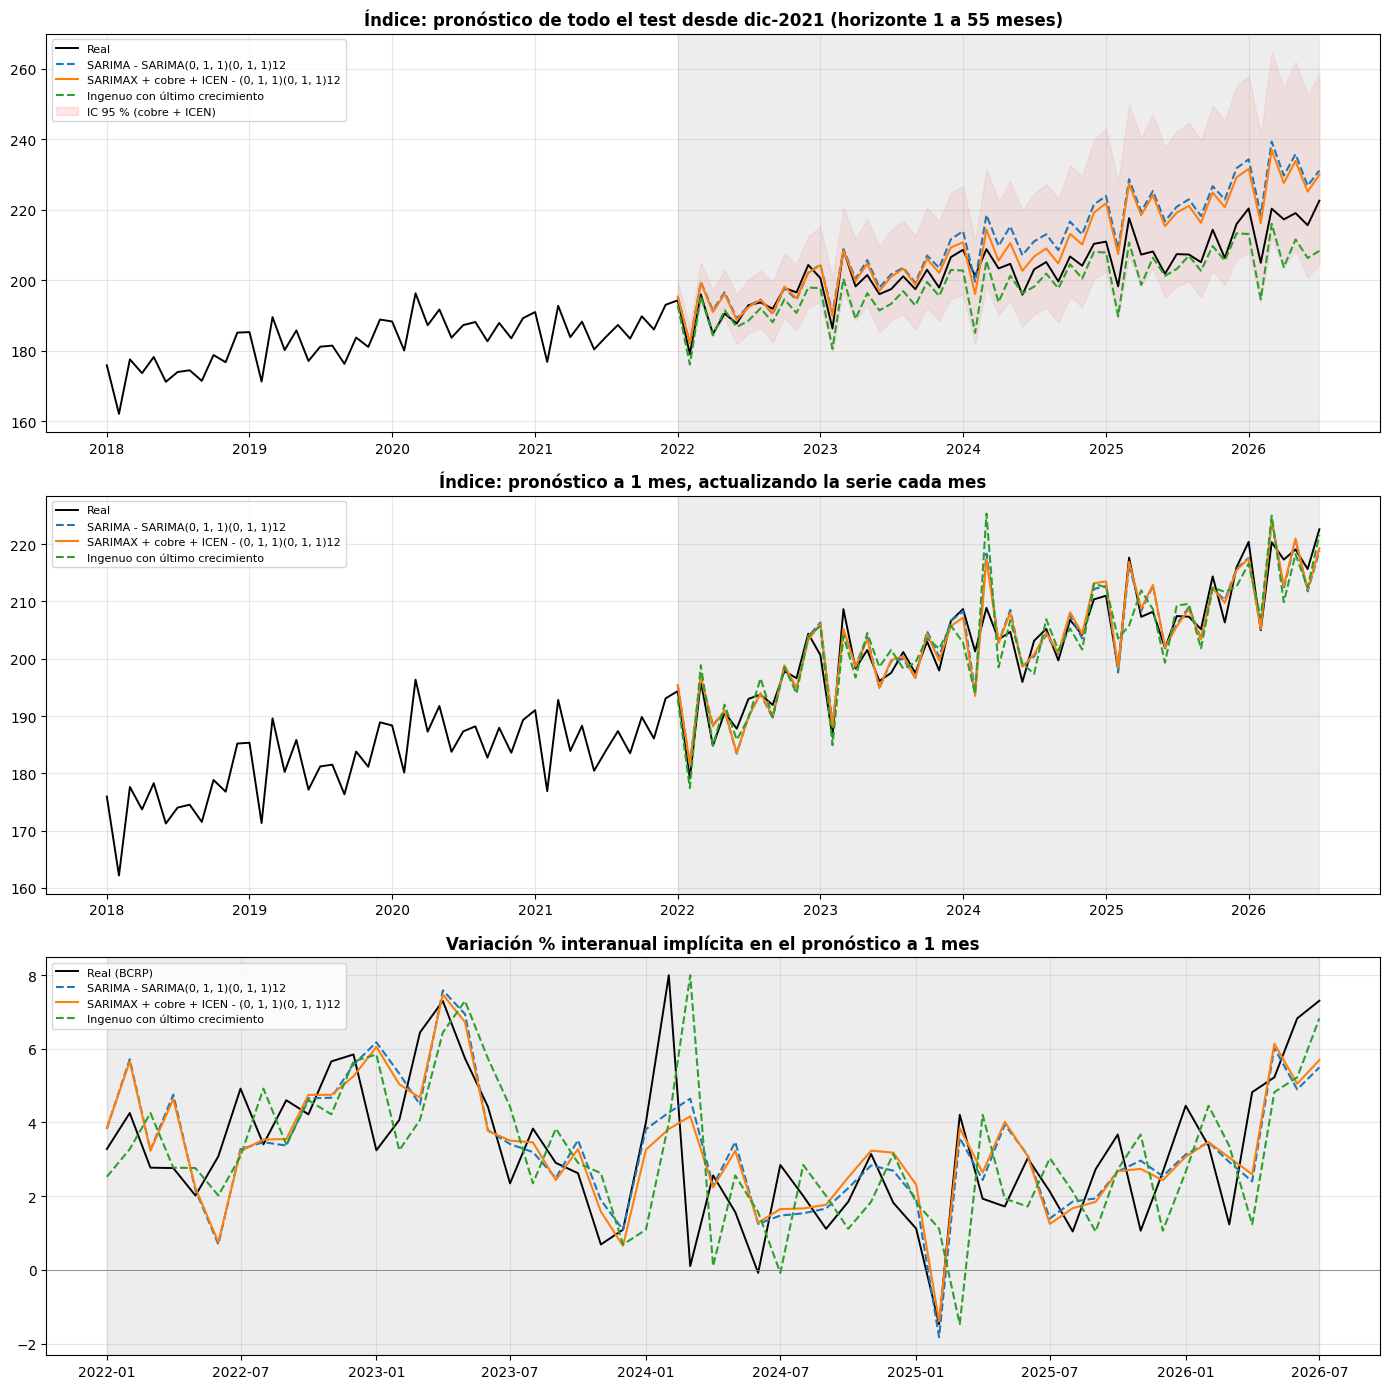

In [23]:
etiqueta_final = f'SARIMAX + cobre + ICEN - {orden}{estacional[:3]}12'
etiqueta_sarima = f'SARIMA - {nombre_sarima}'
mostrar = [etiqueta_sarima, etiqueta_final, 'Ingenuo con último crecimiento']

fig, axes = plt.subplots(3, 1, figsize=(14, 14))
axes[0].plot(indice['2018-01-01':], color='black', linewidth=1.4, label='Real')
for etiqueta in mostrar:
    axes[0].plot(pronosticos[etiqueta], linestyle='-' if etiqueta == etiqueta_final else '--', label=etiqueta)
axes[0].fill_between(test.index, bandas[etiqueta_final].iloc[:, 0], bandas[etiqueta_final].iloc[:, 1],
                     color='red', alpha=0.1, label='IC 95 % (cobre + ICEN)')
axes[0].set_title('Índice: pronóstico de todo el test desde dic-2021 (horizonte 1 a 55 meses)', fontweight='bold')

axes[1].plot(indice['2018-01-01':], color='black', linewidth=1.4, label='Real')
for etiqueta in mostrar:
    axes[1].plot(pronosticos_1m[etiqueta], linestyle='-' if etiqueta == etiqueta_final else '--', label=etiqueta)
axes[1].set_title('Índice: pronóstico a 1 mes, actualizando la serie cada mes', fontweight='bold')

variacion_real = variacion
axes[2].plot(variacion_real['2022-01-01':], color='black', linewidth=1.4, label='Real (BCRP)')
for etiqueta in mostrar:
    axes[2].plot(a_variacion(pronosticos_1m[etiqueta], indice_original), linestyle='-' if etiqueta == etiqueta_final else '--', label=etiqueta)
axes[2].axhline(0, color='gray', linewidth=0.6)
axes[2].set_title('Variación % interanual implícita en el pronóstico a 1 mes', fontweight='bold')
for ax in axes:
    ax.axvspan(test.index[0], test.index[-1], color='lightgray', alpha=0.4)
    ax.grid(alpha=0.3); ax.legend(loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

### 7.2. Tabla de métricas de los mejores modelos

Se resumen los mejores modelos considerados: el mejor de cada familia univariada (AR, MA, ARMA, SARIMA), las tres versiones SARIMAX y los ingenuos. Las métricas de error se calculan sobre el **índice** (escala original, después de deshacer el logaritmo). Las columnas "var. %" miden el error en la variación interanual, en pp.

In [24]:
filas = []
for etiqueta in pronosticos:
    fila = {'Modelo': etiqueta}
    if etiqueta in ajustes:
        m, kk = ajustes[etiqueta]
        fila.update({'AIC': m.aic, 'BIC': m.bic,
                     'p-Ljung-Box(24)': acorr_ljungbox(residuos_validos(m), lags=[24], model_df=kk)['lb_pvalue'].iloc[0]})
    fila.update(metricas(indice_test, pronosticos[etiqueta]))
    fila['RMSE var. % (pp)'] = np.sqrt(mean_squared_error(variacion_test, a_variacion(pronosticos[etiqueta], indice_original[train.index])))
    m1 = metricas(indice_test, pronosticos_1m[etiqueta])
    fila.update({f'{c} 1 mes': m1[c] for c in ['RMSE', 'MAE', 'MAPE (%)']})
    fila['RMSE var. % (pp) 1 mes'] = np.sqrt(mean_squared_error(variacion_test, a_variacion(pronosticos_1m[etiqueta], indice_original)))
    filas.append(fila)

resumen_metricas = pd.DataFrame(filas).set_index('Modelo')
resumen_metricas.columns = pd.MultiIndex.from_tuples(
    [('Ajuste (train)', c) for c in ['AIC', 'BIC', 'p-Ljung-Box(24)']] +
    [('Test - horizonte completo', c) for c in ['MSE', 'RMSE', 'MAE', 'MAPE (%)', 'RMSE var. % (pp)']] +
    [('Test - 1 mes', c) for c in ['RMSE 1 mes', 'MAE 1 mes', 'MAPE (%) 1 mes', 'RMSE var. % (pp) 1 mes']])
(resumen_metricas.style.format('{:.4f}', na_rep='—')
 .highlight_min(subset=[c for c in resumen_metricas.columns if c[1] != 'p-Ljung-Box(24)'], color='#c6efce')
 .set_caption('Métricas de los mejores modelos (verde = mejor valor de cada columna)'))

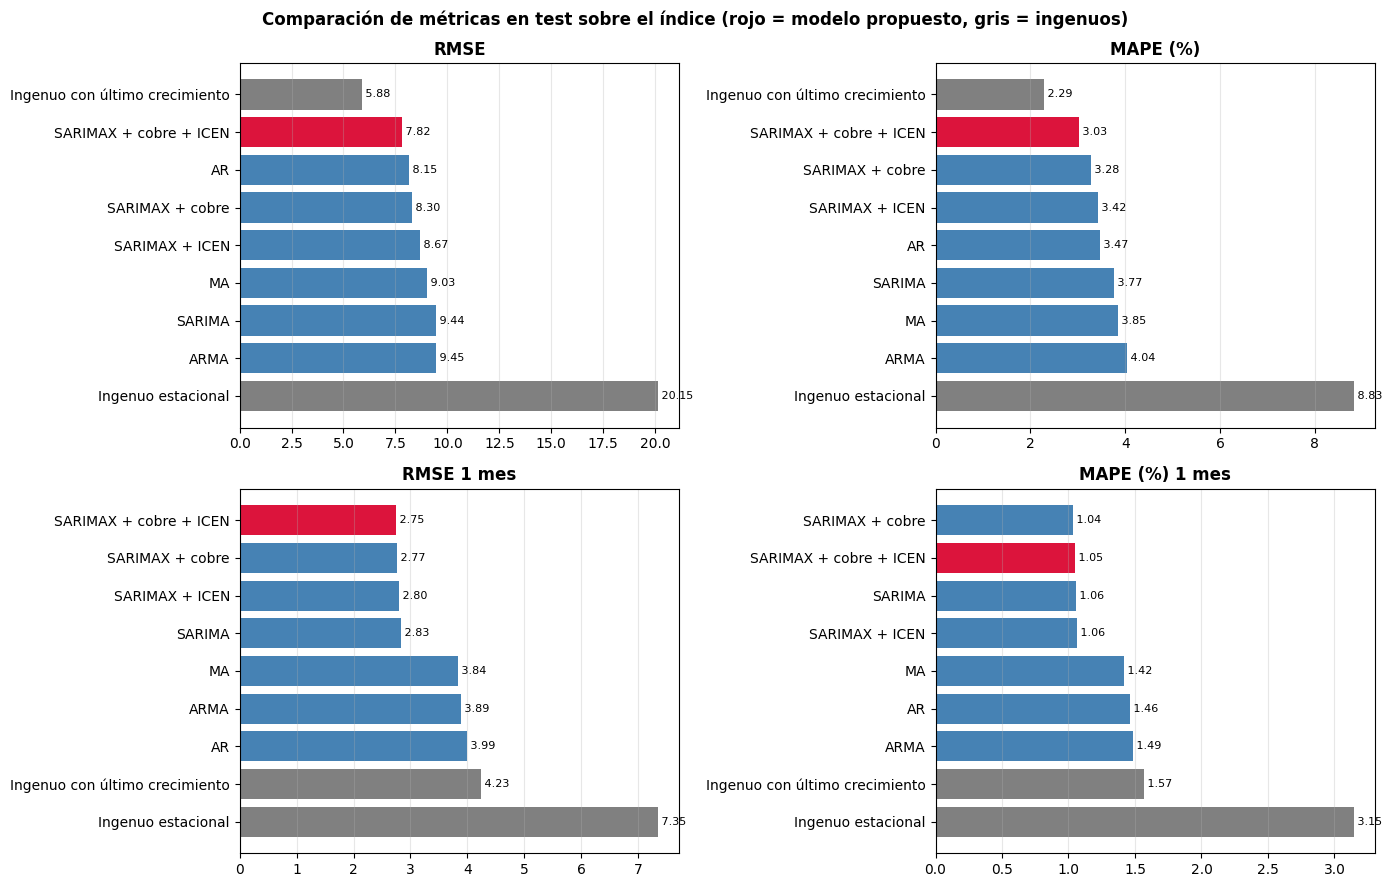

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
tabla_plana = resumen_metricas.droplevel(0, axis=1)
for ax, columna in zip(axes.flat, ['RMSE', 'MAPE (%)', 'RMSE 1 mes', 'MAPE (%) 1 mes']):
    valores = tabla_plana[columna].sort_values()
    colores = ['crimson' if 'cobre + ICEN' in e else 'gray' if 'Ingenuo' in e else 'steelblue' for e in valores.index]
    ax.barh([e.split(' - ')[0] for e in valores.index], valores.values, color=colores)
    ax.set_title(columna, fontweight='bold'); ax.invert_yaxis(); ax.grid(alpha=0.3, axis='x')
    for i, v in enumerate(valores.values):
        ax.text(v, i, f' {v:.2f}', va='center', fontsize=8)
plt.suptitle('Comparación de métricas en test sobre el índice (rojo = modelo propuesto, gris = ingenuos)', fontweight='bold')
plt.tight_layout(); plt.show()

**Diebold–Mariano**: H₀ = los dos pronósticos tienen el mismo error cuadrático. Si p < 0,05 la diferencia es significativa; un estadístico negativo indica que el modelo propuesto tiene menor error y uno positivo, mayor error. Se compara el modelo propuesto a 1 mes con el SARIMA sin exógenas y con los ingenuos.

In [26]:
def diebold_mariano(real, pred_a, pred_b):
    dif = (real - pred_a)**2 - (real - pred_b)**2
    dm = dif.mean() / (dif.std() / np.sqrt(len(dif)))
    return dm, 2 * stats.norm.sf(abs(dm))

dm_tabla = []
for rival in [etiqueta_sarima, 'Ingenuo estacional', 'Ingenuo con último crecimiento']:
    dm, p = diebold_mariano(indice_test, pronosticos_1m[etiqueta_final], pronosticos_1m[rival])
    dm_tabla.append({'Comparación (1 mes)': f'Propuesto vs {rival.split(" - ")[0]}', 'Estadístico DM': dm, 'p-valor': p,
                     'Conclusión': 'Sin diferencia significativa' if p >= alpha else
                                   'El propuesto es significativamente mejor' if dm < 0 else 'El propuesto es significativamente peor'})
display(pd.DataFrame(dm_tabla).round(4))

,Comparación (1 mes),Estadístico DM,p-valor,Conclusión
0,Propuesto vs SARIMA,-0.8954,0.3706,Sin diferencia significativa
1,Propuesto vs Ingenuo estacional,-6.1887,0.0000,El propuesto es significativamente mejor
2,Propuesto vs Ingenuo con último crecimiento,-2.2886,0.0221,El propuesto es significativamente mejor


**Interpretación de la tabla de métricas**

- **A 1 mes (uso real), el modelo propuesto tiene el menor RMSE y el menor error en la variación interanual:**
  - Error sobre el índice: RMSE 2,75 puntos y **MAPE 1,05 %**.
  - Error en la variación interanual: **1,39 pp**.
  - Mejora al SARIMA sin exógenas (2,83 puntos; 1,06 %; 1,43 pp) y supera claramente a los ingenuos (MAPE 1,57 % y 3,15 %).
  - En **MAE y MAPE** a 1 mes el mejor es el SARIMAX **solo con cobre** (2,11 puntos y 1,04 %, frente a 2,14 y 1,05 % del propuesto). Las diferencias entre las tres versiones SARIMAX y el SARIMA son de centésimas: en la práctica, los cuatro tienen una precisión muy parecida a 1 mes.
  - Diebold–Mariano: la mejora frente a ambos ingenuos es **significativa** (p = 0,022 y p < 0,001). Frente al SARIMA la mejora es pequeña y no significativa (p = 0,37).
- **Horizonte completo (55 meses desde dic-2021):** entre los modelos estimados, el propuesto es el de menor error (RMSE 7,82; MAPE 3,03 %), mejor que el SARIMA (9,44; 3,77 %). Aun así, ningún modelo supera al ingenuo con último crecimiento (5,88; 2,29 %). La razón es que en 2022–2026 el sector creció ≈ 3 % anual, por debajo de su promedio histórico (≈ 4,6 %), y los modelos, que extrapolan la tendencia de 2002–2021, sobreestiman el nivel a varios años. Además, en el error de la **variación interanual** (2,49 pp) el propuesto no es el mejor: quedan por debajo el AR (2,37), el SARIMAX solo con cobre (2,40), el SARIMA (2,47) y el ingenuo con último crecimiento (2,08).
- **AR, MA y ARMA** quedan peor a 1 mes (MAPE 1,42–1,49 %) y además **no pasan Ljung–Box**, así que no son modelos válidos.
- **El MAPE ahora es interpretable:** el índice vale entre 150 y 230 y nunca se acerca a cero. Un MAPE de 1,05 % significa que, en promedio, el pronóstico del mes siguiente se equivoca en ≈ 1 % del nivel del índice.
- **Efecto del logaritmo:** en una versión anterior de este trabajo, que modelaba directamente la variación % interanual, el error a 1 mes era de 2,11 pp. Modelar el logaritmo del índice lo reduce a **1,39 pp** (≈ 34 % menos). Esa versión anterior no se incluye en este notebook.

## 8. Análisis de residuales del modelo propuesto

Para que el modelo sea válido sus residuos deben comportarse como **ruido blanco**: media cero, sin autocorrelación y, idealmente, varianza constante y distribución normal (notebook 06 del curso). Se descartan los primeros 13 residuos, que corresponden a la inicialización de las diferencias.

- **Ljung–Box** (rezagos 12 y 24): aceptable si p ≥ 0,05 → residuos no correlacionados. Si p < 0,05, se vuelve a la identificación.
- **ARCH**: aceptable si p ≥ 0,05 → varianza constante.
- **Jarque–Bera**: aceptable si p ≥ 0,05 → residuos normales.

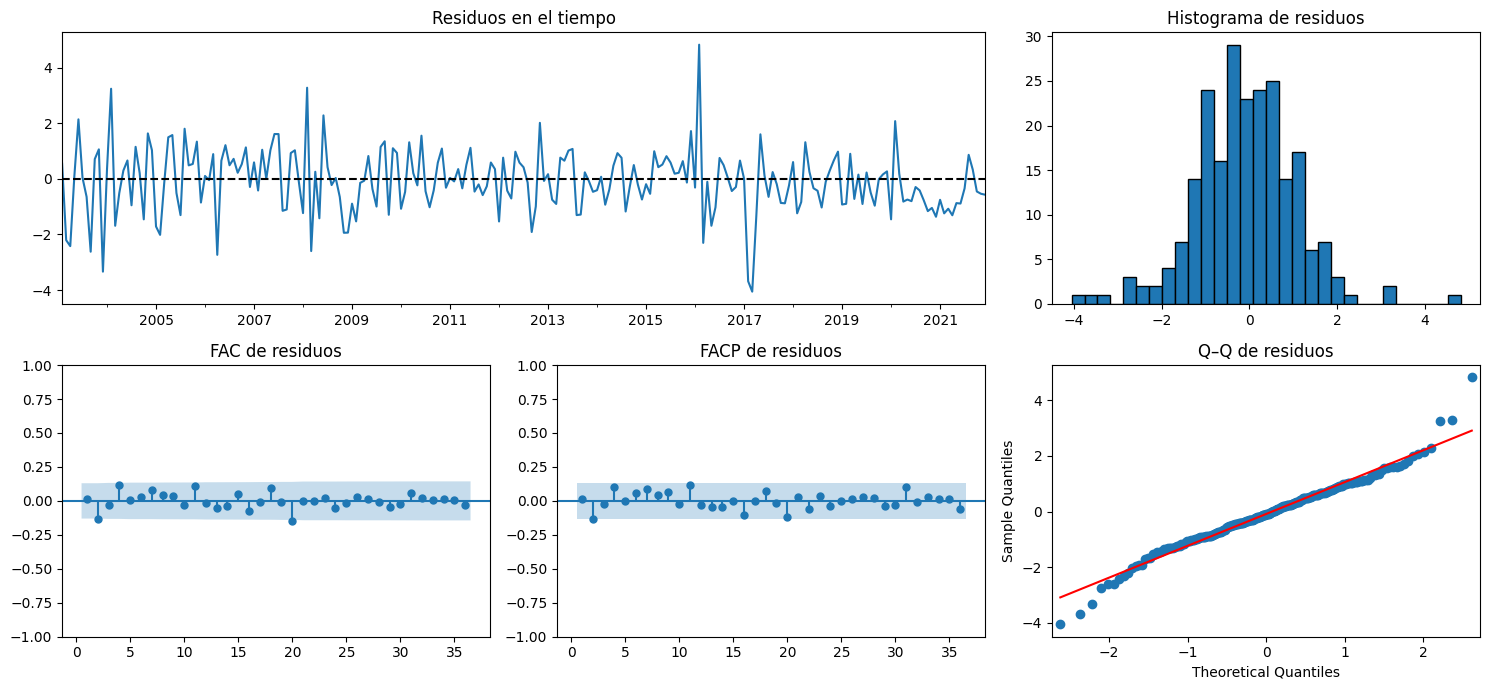

In [27]:
residuales = residuos_validos(modelo)

fig, axes = plt.subplot_mosaic([['t', 't', 'hist'], ['fac', 'facp', 'qq']], figsize=(15, 7))
residuales.plot(ax=axes['t'], title='Residuos en el tiempo')
axes['t'].axhline(0, color='black', linestyle='--')
plot_acf(residuales, lags=36, zero=False, ax=axes['fac'], title='FAC de residuos')
plot_pacf(residuales, lags=36, zero=False, method='ywm', ax=axes['facp'], title='FACP de residuos')
axes['hist'].hist(residuales, bins=30, edgecolor='black')
axes['hist'].set_title('Histograma de residuos')
qqplot(residuales, line='s', ax=axes['qq'])
axes['qq'].set_title('Q–Q de residuos')
plt.tight_layout(); plt.show()

In [28]:
lb = acorr_ljungbox(residuales, lags=[12, 24], model_df=k)
arch = het_arch(residuales, nlags=12)
jb = jarque_bera(residuales)

pruebas = pd.DataFrame({
    'Prueba': ['Ljung–Box (12)', 'Ljung–Box (24)', 'ARCH', 'Jarque–Bera'],
    'Estadístico': [lb['lb_stat'].iloc[0], lb['lb_stat'].iloc[1], arch[0], jb[0]],
    'p-valor': [lb['lb_pvalue'].iloc[0], lb['lb_pvalue'].iloc[1], arch[1], jb[1]],
})
pruebas['Interpretación'] = np.where(pruebas['p-valor'] >= alpha, 'Aceptable: p-valor ≥ 0,05', 'Revisar: p-valor < 0,05')
display(pruebas.round(4))
t_media = stats.ttest_1samp(residuales, 0)
print(f'Media de residuos: {residuales.mean():.4f} (prueba t de media cero: p-valor {t_media.pvalue:.4f})')
print('¿Residuos no correlacionados?', 'Sí → el modelo es adecuado para pronosticar' if lb['lb_pvalue'].min() >= alpha
      else 'No → se vuelve a la identificación del modelo (sección 6)')

,Prueba,Estadístico,p-valor,Interpretación
0,Ljung–Box (12),13.2952,0.2076,"Aceptable: p-valor ≥ 0,05"
1,Ljung–Box (24),24.9254,0.3007,"Aceptable: p-valor ≥ 0,05"
2,ARCH,28.3522,0.0049,"Revisar: p-valor < 0,05"
3,Jarque–Bera,36.4285,0.0000,"Revisar: p-valor < 0,05"


Media de residuos: -0.0894 (prueba t de media cero: p-valor 0.2414)
¿Residuos no correlacionados? Sí → el modelo es adecuado para pronosticar


**Interpretación de los residuales**

- **Ljung–Box** (p = 0,21 y 0,30): los residuos no están autocorrelacionados. El modelo capturó la dinámica de la serie y es adecuado para pronosticar.
- **Media de los residuos:** −0,09, sin diferencia significativa con cero (p = 0,24).
- **ARCH** (p = 0,005): la varianza **no es constante**. En el gráfico de residuos en el tiempo hay periodos más volátiles que otros. El pronóstico puntual no se ve afectado, pero los intervalos de confianza pueden quedarse cortos en periodos turbulentos y ser algo amplios en periodos calmos.
- **Jarque–Bera** (p ≈ 0): los residuos **no son normales** y tienen colas pesadas por unos pocos meses atípicos. El gráfico Q–Q lo confirma en los extremos.

## 9. Pronóstico a futuro (12 meses)

Se reestiman los parámetros del modelo propuesto con **toda** la serie (train + test) y se pronostican agosto 2026 – julio 2027. El resultado se presenta como índice y como variación % interanual. Como los 12 meses de hace un año ya son conocidos, la variación % y su intervalo se obtienen directamente del índice pronosticado.

Valores futuros de las exógenas:
- Gracias a los rezagos, los primeros meses usan valores **ya observados** del cobre y del ICEN.
- Los meses restantes se pronostican con un ARIMA propio de cada exógena (el de menor BIC). En el caso del ICEN, estos valores pueden reemplazarse por los pronósticos oficiales del comunicado mensual del **ENFEN**.

In [29]:
pasos = 12
fechas_futuras = pd.date_range(serie.index[-1] + pd.offsets.MonthBegin(1), periods=pasos, freq='MS')

def extender(x, meses, d_x):
    # Completa la exógena con el pronóstico de su propio ARIMA (menor BIC)
    x = x[inicio_muestra - pd.DateOffset(years=1):FIN].dropna()
    if meses <= 0:
        return x, None
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        candidatos_x = [ARIMA(x, order=(p, d_x, q), trend='c' if d_x == 0 else 'n').fit()
                        for p in range(3) for q in range(3) if p + q > 0]
    mejor = min(candidatos_x, key=lambda m: m.bic)
    return pd.concat([x, mejor.get_forecast(steps=meses).predicted_mean]), mejor.model.order

X_futuro = pd.DataFrame(index=fechas_futuras)
origen = pd.DataFrame(index=fechas_futuras)
for col, x, L, d_x in [(col_cobre, cobre_log, L_cobre, 1), (col_icen, icen, L_icen, 0)]:
    extendida, orden_x = extender(x, pasos - L, d_x)
    X_futuro[col] = extendida.shift(L, freq='MS').reindex(fechas_futuras)
    origen[col] = ['Observado' if i < L else f'Pronosticado ARIMA{orden_x}' for i in range(pasos)]
display(pd.concat({'Valor': X_futuro.round(2), 'Origen': origen}, axis=1))

Valor                                 Origen  \
           ln_cobre_t-7 icen_t-10                 ln_cobre_t-7   
2026-08-01       638.43     -0.42                    Observado   
2026-09-01       637.71     -0.50                    Observado   
2026-10-01       634.03     -0.51                    Observado   
2026-11-01       636.59     -0.06                    Observado   
2026-12-01       641.58      0.42                    Observado   
2027-01-01       642.28      0.96                    Observado   
2027-02-01       641.92      1.34                    Observado   
2027-03-01       641.77      1.98  Pronosticado ARIMA(1, 1, 0)   
2027-04-01       641.71      2.66  Pronosticado ARIMA(1, 1, 0)   
2027-05-01       641.69      3.38  Pronosticado ARIMA(1, 1, 0)   
2027-06-01       641.68      3.57  Pronosticado ARIMA(1, 1, 0)   
2027-07-01       641.67      3.48  Pronosticado ARIMA(1, 1, 0)   

                                         
                              icen_t-10  
2026-08-01                    Observado  
2026-09-01                    Observado  
2026-10-01                    Observado  
2026-11-01                    Observado  
2026-12-01                    Observado  
2027-01-01                    Observado  
2027-02-01                    Observado  
2027-03-01                    Observado  
2027-04-01                    Observado  
2027-05-01                    Observado  
2027-06-01  Pronosticado ARIMA(2, 0, 2)  
2027-07-01  Pronosticado ARIMA(2, 0, 2)

,Índice pronosticado,Var. % interanual,Var. % IC 95 % inf.,Var. % IC 95 % sup.,Var. % SARIMA sin exógenas
2026-08-01,223.71,7.89,5.51,10.31,7.59
2026-09-01,219.23,6.86,4.12,9.66,6.58
2026-10-01,227.18,5.97,2.93,9.10,5.81
2026-11-01,222.69,7.92,4.52,11.43,7.88
2026-12-01,231.48,7.18,3.53,10.96,7.19
2027-01-01,232.99,5.71,1.86,9.71,5.86
2027-02-01,217.48,6.09,1.99,10.36,6.41
2027-03-01,236.31,7.24,2.87,11.80,7.81
2027-04-01,226.47,4.21,-0.24,8.87,5.05
2027-05-01,230.55,5.23,0.54,10.15,6.34


Coeficientes reestimados con toda la serie:


,Coeficiente,p-valor
ln_cobre_t-7,0.0214,0.0341
icen_t-10,-0.3594,0.0087
ma.L1,-0.4025,0.0000
ma.S.L12,-0.8967,0.0000
sigma2,1.2868,0.0000


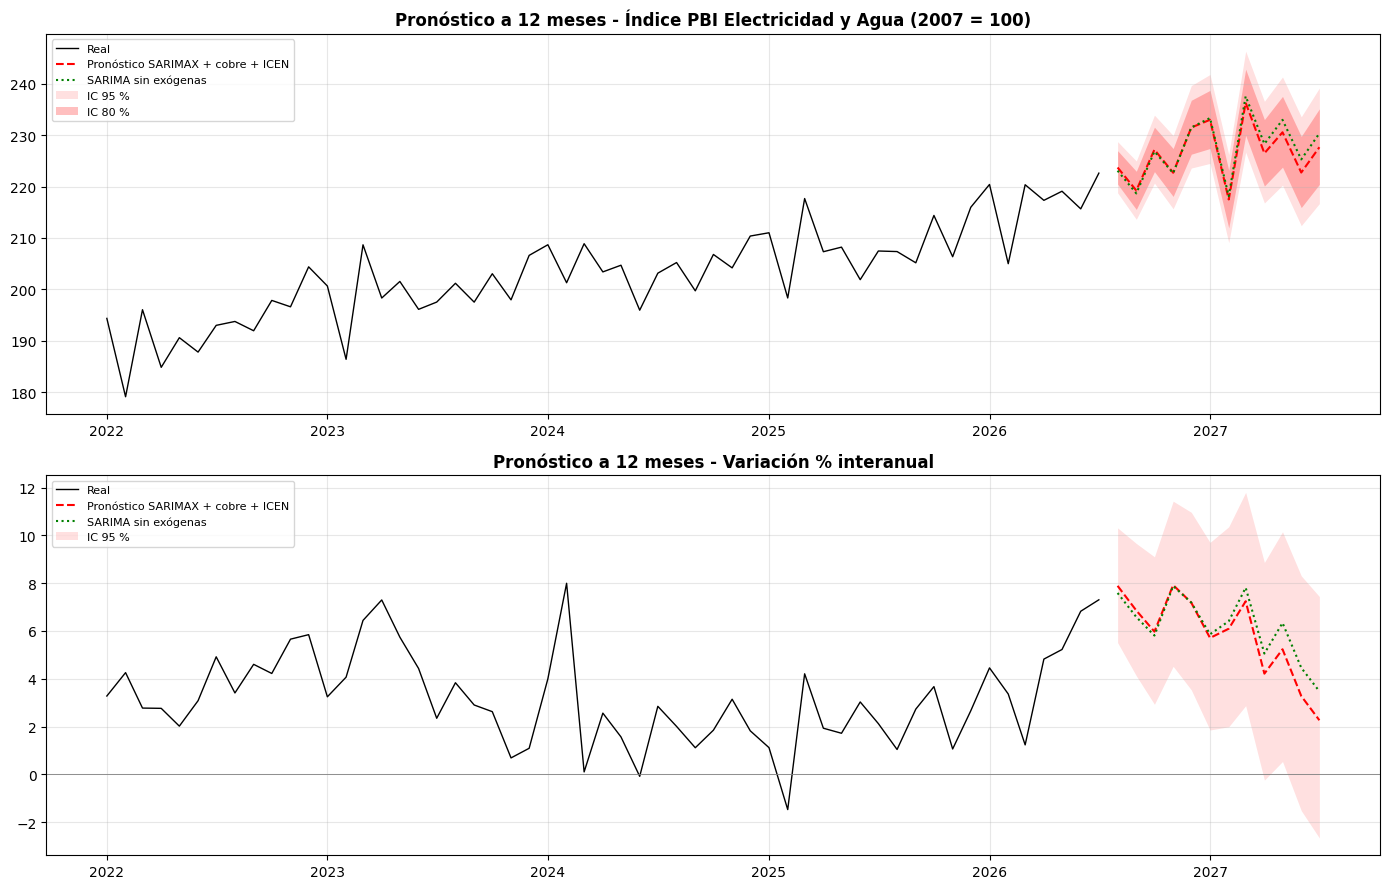

In [30]:
modelo_completo = ajustar(serie, orden, estacional, exog=X.loc[serie.index, cols_exog])
f_futuro = modelo_completo.get_forecast(steps=pasos, exog=X_futuro[cols_exog])
indice_futuro = a_indice(f_futuro.predicted_mean)
ic_futuro = {nivel: a_indice(f_futuro.conf_int(alpha=1 - nivel / 100)) for nivel in (80, 95)}
base = indice.reindex(fechas_futuras - pd.DateOffset(years=1)).values
sin_exog = a_indice(ajustar(serie, orden, estacional).get_forecast(steps=pasos).predicted_mean)

tabla_futuro = pd.DataFrame({
    'Índice pronosticado': indice_futuro,
    'Var. % interanual': 100 * (indice_futuro / base - 1),
    'Var. % IC 95 % inf.': 100 * (ic_futuro[95].iloc[:, 0].values / base - 1),
    'Var. % IC 95 % sup.': 100 * (ic_futuro[95].iloc[:, 1].values / base - 1),
    'Var. % SARIMA sin exógenas': 100 * (sin_exog.values / base - 1),
}, index=fechas_futuras)
display(tabla_futuro.round(2))
print('Coeficientes reestimados con toda la serie:')
display(pd.DataFrame({'Coeficiente': modelo_completo.params, 'p-valor': modelo_completo.pvalues}).round(4))

fig, axes = plt.subplots(2, 1, figsize=(14, 9))
axes[0].plot(indice['2022-01-01':], color='black', linewidth=1, label='Real')
axes[0].plot(indice_futuro, color='red', linestyle='--', linewidth=1.5, label='Pronóstico SARIMAX + cobre + ICEN')
axes[0].plot(sin_exog, color='green', linestyle=':', linewidth=1.5, label='SARIMA sin exógenas')
for nivel, transparencia in [(95, 0.12), (80, 0.25)]:
    axes[0].fill_between(fechas_futuras, ic_futuro[nivel].iloc[:, 0], ic_futuro[nivel].iloc[:, 1],
                         color='red', alpha=transparencia, linewidth=0, label=f'IC {nivel} %')
axes[0].set_title('Pronóstico a 12 meses - Índice PBI Electricidad y Agua (2007 = 100)', fontweight='bold')
axes[1].plot(variacion_real['2022-01-01':], color='black', linewidth=1, label='Real')
axes[1].plot(tabla_futuro['Var. % interanual'], color='red', linestyle='--', linewidth=1.5, label='Pronóstico SARIMAX + cobre + ICEN')
axes[1].plot(tabla_futuro['Var. % SARIMA sin exógenas'], color='green', linestyle=':', linewidth=1.5, label='SARIMA sin exógenas')
axes[1].fill_between(fechas_futuras, tabla_futuro['Var. % IC 95 % inf.'], tabla_futuro['Var. % IC 95 % sup.'],
                     color='red', alpha=0.12, linewidth=0, label='IC 95 %')
axes[1].axhline(0, color='gray', linewidth=0.6)
axes[1].set_title('Pronóstico a 12 meses - Variación % interanual', fontweight='bold')
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

**Interpretación del pronóstico a futuro**

- Reestimado con toda la serie (2002–2026), los dos efectos se vuelven **significativos al 5 %**: la elasticidad del cobre es +0,021 (p = 0,034) y la semielasticidad del ICEN −0,36 (p = 0,009). Los datos del test refuerzan la relación encontrada en train.
- **Pronóstico:** índice de 223,7 en agosto 2026 (+7,9 % interanual). Hacia julio 2027 el crecimiento baja gradualmente a **+2,3 %**.
- **Diferencia con el SARIMA sin exógenas:** entre agosto y diciembre 2026 ambos son casi iguales; el SARIMAX está apenas por encima por el cobre caro. Desde marzo 2027 el SARIMAX queda **≈ 0,6 a 1,2 pp por debajo**. Ese es el efecto del **El Niño Costero fuerte de 2026**, que entra con 10 meses de rezago. Es la principal ventaja del modelo con exógenas: **anticipa el impacto de El Niño**, algo que un SARIMA no puede hacer.
- **Incertidumbre:** el intervalo del 95 % de la variación % se ensancha de ±2,4 a ±5,1 pp y en abril, junio y julio 2027 llega a incluir crecimiento negativo. Como la prueba ARCH mostró varianza cambiante, conviene leer los intervalos como aproximados. Además, el cobre desde marzo 2027 y el ICEN desde junio 2027 son pronósticos propios; en el caso del ICEN conviene reemplazarlo por el pronóstico oficial del ENFEN y actualizar el modelo cada mes.

## 10. Modelos de Machine Learning: XGBoost, LightGBM y CatBoost

Se comparan los tres modelos de *boosting* del notebook 08 del curso. Como predictores se usan las **variables creadas en el notebook 01** (Retorno, Log_Return, Cambio y las medias móviles MA_3, MA_6 y MA_9), los **rezagos** del notebook 08 y las dos exógenas del SARIMAX.

Diferencia con los modelos de las secciones 4–9: los árboles no necesitan estacionariedad ni supuestos sobre los residuos, pero **no extrapolan**. Solo pueden predecir valores dentro del rango que vieron en el entrenamiento. Por eso el diseño cuida que el objetivo y los predictores tengan, en el test, valores parecidos a los de train.

### 10.1. Variables del notebook 01

Se crean las mismas variables del notebook 01, con las mismas fórmulas, sobre el índice del PBI de Electricidad y Agua (en el notebook 01 se aplicaban al precio de cierre de Bitcoin). La tabla compara el rango de cada variable en train y en test.

In [31]:
serie_tiempo = indice.to_frame('Close')   # índice con la pandemia imputada (sección 3.1)

# Variables del notebook 01
serie_tiempo['Retorno'] = serie_tiempo['Close'].pct_change()                                     # rendimiento simple
serie_tiempo['Log_Return'] = np.log(serie_tiempo['Close'] / serie_tiempo['Close'].shift(1))     # rendimiento logarítmico
serie_tiempo['Cambio'] = serie_tiempo['Close'].diff()                                          # variación absoluta
serie_tiempo['MA_3'] = serie_tiempo['Close'].rolling(3).mean()                                 # medias móviles
serie_tiempo['MA_6'] = serie_tiempo['Close'].rolling(6).mean()
serie_tiempo['MA_9'] = serie_tiempo['Close'].rolling(9).mean()
display(serie_tiempo.tail().round(4))

en_train = serie_tiempo[serie_tiempo.index < inicio_test]
en_test = serie_tiempo[serie_tiempo.index >= inicio_test]
rango = pd.DataFrame({'Train mín.': en_train.min(), 'Train máx.': en_train.max(),
                      'Test mín.': en_test.min(), 'Test máx.': en_test.max(),
                      '% del test por encima del máx. de train': 100 * (en_test > en_train.max()).mean()})
display(rango.round(4))

,Close,Retorno,Log_Return,Cambio,MA_3,MA_6,MA_9
2026-03-01,220.3523,0.0749,0.0723,15.3633,215.2500,213.7402,211.3794
2026-04-01,217.3173,-0.0138,-0.0139,-3.0350,214.2195,214.2298,212.4747
2026-05-01,219.0891,0.0082,0.0081,1.7718,218.9196,216.3537,213.7789
2026-06-01,215.6596,-0.0157,-0.0158,-3.4295,217.3553,216.3027,214.9453
2026-07-01,222.6123,0.0322,0.0317,6.9527,219.1203,216.6699,215.8600


,Train mín.,Train máx.,Test mín.,Test máx.,% del test por encima del máx. de train
Close,67.9233,196.3463,179.1029,222.6123,78.1818
Retorno,-0.0964,0.1248,-0.0784,0.1195,0.0000
Log_Return,-0.1013,0.1176,-0.0817,0.1129,0.0000
Cambio,-16.9280,18.2824,-15.4196,22.2807,3.6364
MA_3,72.2875,191.7899,186.6563,219.1203,85.4545
MA_6,72.7916,189.1072,187.6578,216.6699,90.9091
MA_9,73.0037,188.0031,186.4124,215.8600,96.3636


**Lectura de la tabla**

- El índice (`Close`) y sus medias móviles en el test están mayormente **por encima del máximo de train**: el 78 % de los meses en el caso del índice y entre el 85 % y el 96 % en MA_3, MA_6 y MA_9. Un árbol asigna a todos esos meses la hoja del valor más alto que conoce, así que con esas variables el pronóstico quedaría plano.
- Las variables de cambio del notebook 01 (`Retorno`, `Log_Return` y `Cambio`) tienen en el test rangos parecidos a los de train: solo el 4 % de los meses de `Cambio` supera el máximo de train. Son las adecuadas para un árbol.

**Diseño** (pronóstico a 1 mes, como en la sección 7):

- **Variable objetivo:** `Log_Return` del mes *t*, el crecimiento mensual en logaritmos del notebook 01. El índice se reconstruye con $\hat{I}_t = I_{t-1}\, e^{\widehat{\text{Log\_Return}}_t}$, coherente con la transformación logarítmica de la sección 3.2.
- **Predictores:** todos se conocen al cierre del mes *t − 1*. Se rezagan al menos un mes para que no haya fuga de información.

| Grupo | Variables | Origen y motivo |
|---|---|---|
| Rezagos del objetivo | `lag_1` … `lag_12` de Log_Return | `make_lags` del notebook 08. `lag_12` es el crecimiento del mismo mes del año anterior (estacionalidad) |
| Variables del notebook 01 | `Retorno_t-1`, `Cambio_t-1` | Rendimiento simple y variación absoluta del mes anterior |
| Medias móviles del notebook 01 | `MA_3_rel_t-1`, `MA_6_rel_t-1`, `MA_9_rel_t-1` | $\ln(I_{t-1}/\text{MA}_k)$: distancia del último dato a su media móvil. Se usa la versión **relativa** porque el nivel de la media móvil no extrapola |
| Calendario | `mes` | Estacionalidad |
| Exógenas | `ret_cobre_t-7`, `icen_t-10` | Mismos rezagos del SARIMAX (sección 6.2). El cobre entra como su propio Log_Return, porque su nivel tampoco extrapola |

`Log_Return` del mes anterior es `lag_1`, y `Retorno_t-1` es casi igual a él (para cambios pequeños, el rendimiento simple y el logarítmico casi coinciden). Los árboles toleran esa redundancia.

In [32]:
def make_lags(df, columna, n_lags):
    # Igual que en el notebook 08: agrega los rezagos lag_1 ... lag_n de la columna
    data = df.copy()
    for i in range(1, n_lags + 1):
        data[f'lag_{i}'] = df[columna].shift(i)
    return data

variables_ml = pd.DataFrame({'Log_Return': serie_tiempo['Log_Return']})
variables_ml = make_lags(variables_ml, 'Log_Return', 12)
variables_ml['Retorno_t-1'] = serie_tiempo['Retorno'].shift(1)
variables_ml['Cambio_t-1'] = serie_tiempo['Cambio'].shift(1)
for k in (3, 6, 9):
    variables_ml[f'MA_{k}_rel_t-1'] = np.log(serie_tiempo['Close'] / serie_tiempo[f'MA_{k}']).shift(1)
variables_ml['mes'] = variables_ml.index.month
variables_ml[f'ret_cobre_t-{L_cobre}'] = np.log(cobre / cobre.shift(1)).shift(L_cobre).reindex(variables_ml.index)
variables_ml[f'icen_t-{L_icen}'] = icen.shift(L_icen).reindex(variables_ml.index)
variables_ml = variables_ml.dropna()

X_ml, y_ml = variables_ml.drop(columns='Log_Return'), variables_ml['Log_Return']
X_train_ml, y_train_ml = X_ml[X_ml.index < inicio_test], y_ml[y_ml.index < inicio_test]
X_test_ml, y_test_ml = X_ml[X_ml.index >= inicio_test], y_ml[y_ml.index >= inicio_test]

print('Predictores:', X_ml.shape[1], '|', ', '.join(X_ml.columns))
print('Train:', X_train_ml.index.min().strftime('%Y-%m'), 'a', X_train_ml.index.max().strftime('%Y-%m'), f'({len(X_train_ml)} meses)')
print('Test: ', X_test_ml.index.min().strftime('%Y-%m'), 'a', X_test_ml.index.max().strftime('%Y-%m'), f'({len(X_test_ml)} meses)')
variables_ml.head(3).round(4)

Predictores: 20 | lag_1, lag_2, lag_3, lag_4, lag_5, lag_6, lag_7, lag_8, lag_9, lag_10, lag_11, lag_12, Retorno_t-1, Cambio_t-1, MA_3_rel_t-1, MA_6_rel_t-1, MA_9_rel_t-1, mes, ret_cobre_t-7, icen_t-10
Train: 2003-02 a 2021-12 (227 meses)
Test:  2022-01 a 2026-07 (55 meses)


,Log_Return,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,...,lag_11,lag_12,Retorno_t-1,Cambio_t-1,MA_3_rel_t-1,MA_6_rel_t-1,MA_9_rel_t-1,mes,ret_cobre_t-7,icen_t-10
2003-02-01,-0.0792,0.0145,0.0609,-0.0382,0.0336,-0.0039,0.0073,0.0300,-0.0574,0.0104,...,0.1176,-0.0836,0.0146,1.1322,0.0294,0.0437,0.0539,2,-0.0379,0.81
2003-03-01,0.0925,-0.0792,0.0145,0.0609,-0.0382,0.0336,-0.0039,0.0073,0.0300,-0.0574,...,-0.0309,0.1176,-0.0762,-5.9738,-0.0486,-0.0335,-0.0217,3,-0.0684,0.67
2003-04-01,-0.0466,0.0925,-0.0792,0.0145,0.0609,-0.0382,0.0336,-0.0039,0.0073,0.0300,...,0.0104,-0.0309,0.0969,7.0193,0.0344,0.0448,0.0576,4,-0.0028,0.30


### 10.2. Entrenamiento y ajuste de hiperparámetros

Igual que en el notebook 08, se usa `GridSearchCV` con la misma grilla (número de árboles, profundidad y tasa de aprendizaje) y el RMSE como métrica. Hay una diferencia: en lugar de `cv=5`, que en algunos pliegues usa el futuro para predecir el pasado, se usa **`TimeSeriesSplit(5)`**. Cada pliegue entrena con el pasado y valida con el bloque siguiente, como ocurre al pronosticar. Se fija la semilla para que los resultados se repitan, y se usa directamente el mejor modelo de la búsqueda (`best_estimator_`).

In [33]:
cv_temporal = TimeSeriesSplit(n_splits=5)
grilla = {'n_estimators': [100, 200, 300, 400, 500], 'max_depth': [2, 3, 4, 5], 'learning_rate': [0.05, 0.01]}
grilla_catb = {'iterations': [100, 200, 300, 400, 500], 'depth': [2, 3, 4, 5], 'learning_rate': [0.05, 0.01]}
estimadores = {
    'XGBoost': (XGBRegressor(random_state=0), grilla),
    'LightGBM': (LGBMRegressor(random_state=0, verbose=-1), grilla),
    'CatBoost': (CatBoostRegressor(random_seed=0, logging_level='Silent', allow_writing_files=False), grilla_catb),
}

modelos_ml, mejores_param = {}, []
for nombre, (estimador, grid) in estimadores.items():
    busqueda_ml = GridSearchCV(estimador, grid, cv=cv_temporal, scoring='neg_root_mean_squared_error', refit=True)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')   # aviso informativo de joblib en Windows
        busqueda_ml.fit(X_train_ml, y_train_ml)
    modelos_ml[nombre] = busqueda_ml.best_estimator_
    p = busqueda_ml.best_params_
    mejores_param.append({'Modelo': nombre, 'Árboles': p.get('n_estimators', p.get('iterations')),
                          'Profundidad': p.get('max_depth', p.get('depth')), 'Tasa de aprendizaje': p['learning_rate'],
                          'RMSE validación (Log_Return)': -busqueda_ml.best_score_})
display(pd.DataFrame(mejores_param).set_index('Modelo').round(5))

,Árboles,Profundidad,Tasa de aprendizaje,RMSE validación (Log_Return)
Modelo,,,,
XGBoost,100,2,0.05,0.01278
LightGBM,200,5,0.05,0.01559
CatBoost,200,5,0.05,0.01089


,XGBoost,LightGBM,CatBoost,Promedio
lag_12,0.373,0.089,0.328,0.264
lag_1,0.147,0.040,0.064,0.084
MA_3_rel_t-1,0.125,0.050,0.034,0.070
lag_8,0.035,0.085,0.051,0.057
lag_6,0.071,0.048,0.037,0.052
lag_11,0.048,0.039,0.052,0.046
mes,0.064,0.020,0.046,0.044
lag_3,0.033,0.062,0.022,0.039
Retorno_t-1,0.000,0.000,0.116,0.039
lag_7,0.033,0.045,0.037,0.039


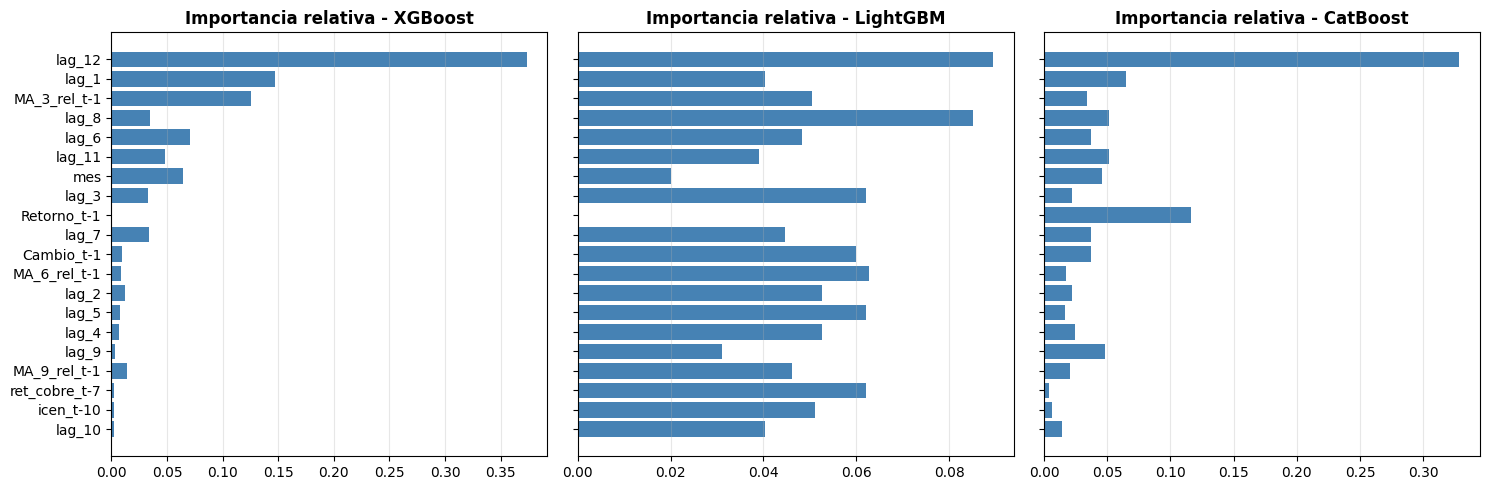

In [34]:
importancias = pd.DataFrame({nombre: m.feature_importances_ / m.feature_importances_.sum()
                             for nombre, m in modelos_ml.items()}, index=X_train_ml.columns)
importancias['Promedio'] = importancias.mean(axis=1)
importancias = importancias.sort_values('Promedio', ascending=False)
display(importancias.head(10).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, nombre in zip(axes, modelos_ml):
    ax.barh(importancias.index, importancias[nombre], color='steelblue')
    ax.set_title(f'Importancia relativa - {nombre}', fontweight='bold'); ax.grid(alpha=0.3, axis='x')
axes[0].invert_yaxis()
plt.tight_layout(); plt.show()

### 10.3. Pronóstico a 1 mes y métricas

Cada modelo predice el `Log_Return` de cada mes del test con los datos disponibles hasta el mes anterior. El índice se reconstruye con $\hat{I}_t = I_{t-1}\, e^{\widehat{\text{Log\_Return}}_t}$. Como en el notebook 08, se agrega un **ensamble** (promedio de los tres) y el **Índice de Error Compuesto (IEC)**. Las métricas se calculan sobre el índice, igual que la columna "Test - 1 mes" de la sección 7, así que son comparables con el SARIMAX.

In [35]:
def a_indice_ml(pred_log_return):
    return pd.Series(indice.shift(1)[X_test_ml.index].values * np.exp(pred_log_return), index=X_test_ml.index)

def IEC(mse, rmse, mae, mape):
    # Índice de Error Compuesto del notebook 08: cada métrica se normaliza como m / (1 + m)
    return np.mean([mse / (1 + mse), rmse / (1 + rmse), mae / (1 + mae), mape / (1 + mape)])

pronosticos_ml = {nombre: a_indice_ml(m.predict(X_test_ml)) for nombre, m in modelos_ml.items()}
pronosticos_ml['Ensamble'] = (pronosticos_ml['XGBoost'] + pronosticos_ml['LightGBM'] + pronosticos_ml['CatBoost']) / 3

def tabla_metricas(pronos):
    filas = []
    for nombre, pred in pronos.items():
        fila = {'Modelo': nombre, **metricas(indice_test, pred)}
        fila['RMSE var. % (pp)'] = np.sqrt(mean_squared_error(variacion_test, a_variacion(pred, indice_original)))
        fila['IEC'] = IEC(fila['MSE'], fila['RMSE'], fila['MAE'], fila['MAPE (%)'])
        filas.append(fila)
    return pd.DataFrame(filas).set_index('Modelo')

metricas_ml = tabla_metricas(pronosticos_ml)
display(metricas_ml.round(4))

,MSE,RMSE,MAE,MAPE (%),RMSE var. % (pp),IEC
Modelo,,,,,,
XGBoost,11.2837,3.3591,2.7062,1.3284,1.7085,0.7475
LightGBM,11.9181,3.4523,2.8376,1.3892,1.7380,0.7547
CatBoost,10.1180,3.1809,2.5738,1.2647,1.6204,0.7374
Ensamble,10.4640,3.2348,2.6625,1.3059,1.6389,0.7425


**Interpretación de los modelos de boosting**

- **Hiperparámetros:** con la validación temporal, XGBoost elige árboles poco profundos (profundidad 2, 100 árboles) y LightGBM y CatBoost, árboles más profundos (profundidad 5, 200 árboles). Los tres usan una tasa de aprendizaje de 0,05. En validación, CatBoost tiene el menor error (RMSE de 0,0109 en Log_Return, ≈ 1,1 % de crecimiento mensual).
- **Importancia de las variables:** la más importante es `lag_12` (26 % en promedio; 37 % en XGBoost y 33 % en CatBoost): el crecimiento del mismo mes del año anterior, que resume el efecto calendario visto en la sección 3.4. Le siguen `lag_1` y la media móvil relativa `MA_3_rel_t-1` (13 % en XGBoost); en CatBoost también pesa `Retorno_t-1` (12 %). Las variables del notebook 01 sí aportan, sobre todo como medida de cuánto se alejó el último dato de su tendencia reciente. Las exógenas pesan poco: menos de 1 % en XGBoost y CatBoost, y entre 5 % y 6 % en LightGBM, en línea con su efecto pequeño en el SARIMAX.
- **Resultados en el test:** CatBoost es el mejor de los tres (RMSE 3,18 puntos; MAPE 1,26 %), seguido del ensamble (3,23), XGBoost (3,36) y LightGBM (3,45). Los tres superan con claridad a los ingenuos (RMSE 4,23 y 7,35), pero no alcanzan al SARIMA ni al SARIMAX (sección 12).
- **IEC:** ordena los modelos igual que el RMSE. Todos quedan entre 0,74 y 0,75, en el tramo "deficiente" de la escala del notebook 08, y el SARIMAX también (0,70). La escala depende de las unidades: con el índice en puntos, el MSE (≈ 10) aporta MSE/(1 + MSE) ≈ 0,9 al promedio. El IEC sirve para comparar modelos sobre la misma serie, no como calificación absoluta.

## 11. AutoML con H2O

Siguiendo el notebook 09 del curso, `H2OAutoML` entrena y compara automáticamente varios algoritmos (GBM, Random Forest, Extremely Randomized Trees, GLM, redes neuronales y *Stacked Ensembles*) y los ordena en una tabla de posiciones (*leaderboard*). Se usan **los mismos predictores, el mismo objetivo (`Log_Return`) y el mismo train/test** de la sección 10, para que la comparación sea justa.

Adaptaciones para series de tiempo:
- **Validación por bloques de tiempo:** en lugar de `nfolds=5` (pliegues al azar, que mezclan meses de distintas épocas) se usa una `fold_column` que divide el train en **5 bloques consecutivos**.
- **Métrica de orden:** RMSE (`sort_metric='RMSE'`), porque es una regresión; el notebook 09 usaba AUC porque era una clasificación.
- `max_models=10` y `seed=1`, como en el notebook 09.

Notas: H2O no incluye XGBoost en Windows, así que en este equipo AutoML no lo prueba. Con solo 227 meses de entrenamiento, algunos GBM con mínimo de 100 filas por hoja no se pueden entrenar y H2O los omite (aparece un aviso). Las redes neuronales de H2O no son exactamente reproducibles con varios núcleos, así que el *leaderboard* puede variar un poco entre ejecuciones.

In [36]:
import h2o
from h2o.automl import H2OAutoML

h2o.init(verbose=False)
h2o.no_progress()

datos_train_h2o = pd.concat([X_train_ml, y_train_ml], axis=1)
datos_train_h2o['bloque'] = np.arange(len(datos_train_h2o)) * 5 // len(datos_train_h2o)   # 5 bloques de tiempo
print('Meses por bloque de validación:', datos_train_h2o['bloque'].value_counts().sort_index().tolist())
train_h2o = h2o.H2OFrame(datos_train_h2o.reset_index(drop=True))
test_h2o = h2o.H2OFrame(X_test_ml.reset_index(drop=True))

automl_model = H2OAutoML(max_models=10, seed=1, sort_metric='RMSE', max_runtime_secs=600)
automl_model.train(x=list(X_train_ml.columns), y='Log_Return', training_frame=train_h2o, fold_column='bloque')

with warnings.catch_warnings():
    warnings.simplefilter('ignore')   # aviso informativo de H2O al convertir a pandas
    lb = automl_model.leaderboard.as_data_frame()
lb[['model_id', 'rmse', 'mae']]

Meses por bloque de validación: [46, 45, 46, 45, 45]



09:56:21.498: Fold column bloque will be used for cross-validation. nfolds parameter will be ignored.
09:56:21.515: AutoML: XGBoost is not available; skipping it.




09:56:22.409: GBM_1_AutoML_1_20261025_95621 [GBM def_5] failed: water.exceptions.H2OModelBuilderIllegalArgumentException: Illegal argument(s) for GBM model: GBM_1_AutoML_1_20261025_95621.  Details: ERRR on field: _min_rows: The dataset size is too small to split for min_rows=100.0: must have at least 200.0 (weighted) rows, but have only 181.0.
ERRR on field: _min_rows: The dataset size is too small to split for min_rows=100.0: must have at least 200.0 (weighted) rows, but have only 182.0.
ERRR on field: _min_rows: The dataset size is too small to split for min_rows=100.0: must have at least 200.0 (weighted) rows, but have only 181.0.
ERRR on field: _min_rows: The dataset size is too small to split for min_rows=100.0: must have at least 200.0 (weighted) rows, but have only 182.0.
ERRR on field: _min_rows: The dataset size is too small to split for min_rows=100.0: must have at least 200.0 (weighted) rows, but have only 182.0.




,model_id,rmse,mae
0,StackedEnsemble_BestOfFamily_1_AutoML_1_202610...,0.011133,0.008471
1,StackedEnsemble_AllModels_1_AutoML_1_20261025_...,0.011242,0.008560
2,DRF_1_AutoML_1_20261025_95621,0.011317,0.008636
3,XRT_1_AutoML_1_20261025_95621,0.011574,0.008776
4,GBM_5_AutoML_1_20261025_95621,0.011758,0.008773
5,GBM_2_AutoML_1_20261025_95621,0.012311,0.009191
6,GBM_4_AutoML_1_20261025_95621,0.012346,0.009148
7,GBM_grid_1_AutoML_1_20261025_95621_model_1,0.012458,0.009690
8,GBM_3_AutoML_1_20261025_95621,0.012583,0.009237
9,DeepLearning_grid_1_AutoML_1_20261025_95621_mo...,0.012753,0.009465


In [37]:
automl_model_best = automl_model.leader
print('Mejor modelo de AutoML:', automl_model_best.model_id)

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    pred_automl = automl_model_best.predict(test_h2o).as_data_frame()['predict'].values
pronosticos_ml['AutoML (H2O)'] = a_indice_ml(pred_automl)
display(tabla_metricas({'AutoML (H2O)': pronosticos_ml['AutoML (H2O)']}).round(4))

Mejor modelo de AutoML: StackedEnsemble_BestOfFamily_1_AutoML_1_20261025_95621


,MSE,RMSE,MAE,MAPE (%),RMSE var. % (pp),IEC
Modelo,,,,,,
AutoML (H2O),10.9925,3.3155,2.6511,1.3034,1.6951,0.7442


**Interpretación de AutoML**

- AutoML entrenó 12 modelos: 10 modelos base (GBM, Random Forest `DRF`, Extremely Randomized Trees `XRT`, GLM y redes neuronales) y 2 *Stacked Ensembles*. Lidera el **StackedEnsemble_BestOfFamily**, que combina el mejor modelo de cada familia, con un RMSE de validación de 0,0111 en Log_Return, apenas mejor que el Random Forest (0,0113). El GLM, que es una regresión lineal, y la red neuronal por defecto quedan últimos.
- En el test, el líder logra un RMSE de 3,32 puntos y un MAPE de 1,30 %: queda entre el ensamble y XGBoost, por detrás de CatBoost.
- **Variabilidad:** en seis ejecuciones del notebook, el RMSE de test del líder de AutoML varió entre 3,30 y 3,38 (su puesto osciló entre el 5.º y el 6.º lugar de la sección 12), porque las redes neuronales de H2O no son exactamente reproducibles y entran en el ensamble. Los modelos de la sección 10 sí dan siempre el mismo resultado.
- Los errores de validación de AutoML y de la sección 10 no son directamente comparables, porque usan esquemas distintos (5 bloques de tiempo frente a `TimeSeriesSplit`). La comparación justa es la del test, en la sección 12.

## 12. Comparación final: SARIMAX, boosting y AutoML

Se comparan todos los modelos en el **mismo escenario**: pronóstico a 1 mes del índice en los 55 meses del test (enero 2022 – julio 2026). Se incluyen el SARIMA y el SARIMAX propuesto (sección 7), los tres modelos de *boosting* y su ensamble (sección 10), el mejor modelo de AutoML (sección 11) y los dos modelos ingenuos de referencia. En verde, el mejor valor de cada columna.

,Tipo,MSE,RMSE,MAE,MAPE (%),RMSE var. % (pp),IEC
Modelo,,,,,,,
SARIMAX + cobre + ICEN,Econometría,7.5794,2.7531,2.1351,1.0468,1.3935,0.7024
SARIMA,Econometría,7.9847,2.8257,2.1527,1.0568,1.4278,0.7060
CatBoost,Boosting,10.1180,3.1809,2.5738,1.2647,1.6204,0.7374
Ensamble,Boosting,10.4640,3.2348,2.6625,1.3059,1.6389,0.7425
AutoML (H2O),AutoML,10.9925,3.3155,2.6511,1.3034,1.6951,0.7442
XGBoost,Boosting,11.2837,3.3591,2.7062,1.3284,1.7085,0.7475
LightGBM,Boosting,11.9181,3.4523,2.8376,1.3892,1.7380,0.7547
Ingenuo con último crecimiento,Referencia,17.9053,4.2315,3.2136,1.5670,2.0930,0.7823
Ingenuo estacional,Referencia,54.0070,7.3489,6.4090,3.1488,3.7755,0.8715


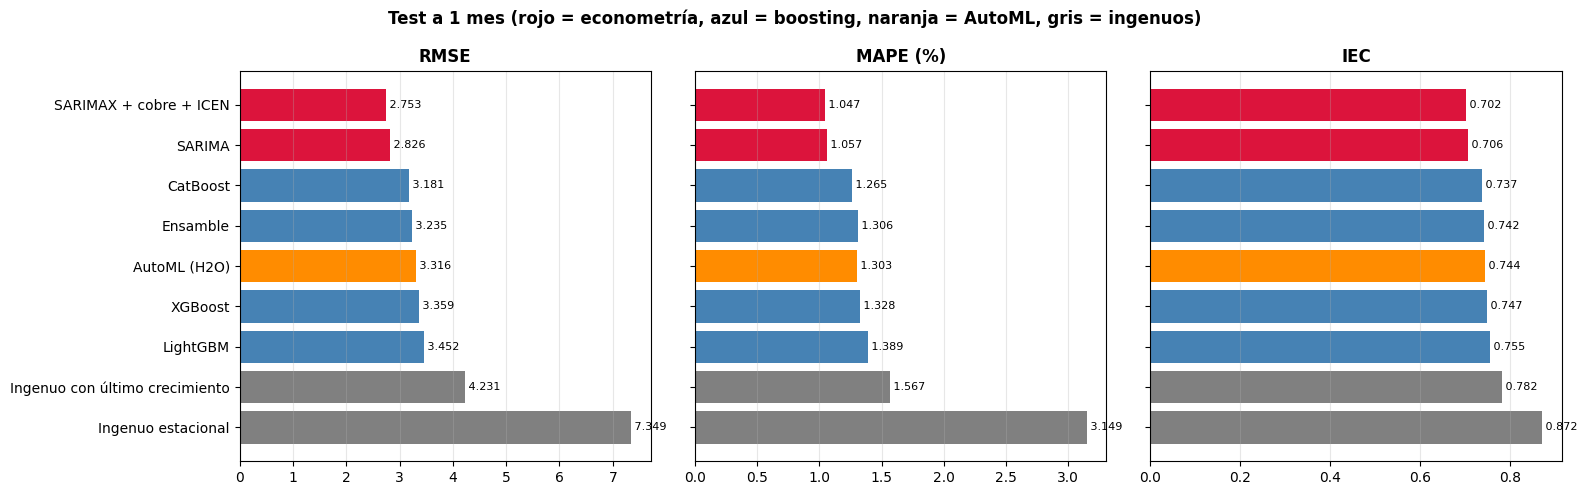

In [38]:
comparacion_final = tabla_metricas({
    'SARIMAX + cobre + ICEN': pronosticos_1m[etiqueta_final],
    'SARIMA': pronosticos_1m[etiqueta_sarima],
    **pronosticos_ml,
    'Ingenuo con último crecimiento': pronosticos_1m['Ingenuo con último crecimiento'],
    'Ingenuo estacional': pronosticos_1m['Ingenuo estacional'],
}).sort_values('RMSE')
comparacion_final.insert(0, 'Tipo', ['Econometría' if 'SARIMA' in m else 'Referencia' if 'Ingenuo' in m
                                     else 'AutoML' if 'AutoML' in m else 'Boosting' for m in comparacion_final.index])
display(comparacion_final.style.format('{:.4f}', subset=comparacion_final.columns[1:])
        .highlight_min(subset=comparacion_final.columns[1:], color='#c6efce')
        .set_caption('Test a 1 mes, métricas sobre el índice (verde = mejor valor de cada columna)'))

colores_tipo = {'Econometría': 'crimson', 'Boosting': 'steelblue', 'AutoML': 'darkorange', 'Referencia': 'gray'}
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, columna in zip(axes, ['RMSE', 'MAPE (%)', 'IEC']):
    ax.barh(comparacion_final.index, comparacion_final[columna], color=comparacion_final['Tipo'].map(colores_tipo))
    for i, v in enumerate(comparacion_final[columna]):
        ax.text(v, i, f' {v:.3f}', va='center', fontsize=8)
    ax.set_title(columna, fontweight='bold'); ax.grid(alpha=0.3, axis='x')
axes[0].invert_yaxis()
plt.suptitle('Test a 1 mes (rojo = econometría, azul = boosting, naranja = AutoML, gris = ingenuos)', fontweight='bold')
plt.tight_layout(); plt.show()

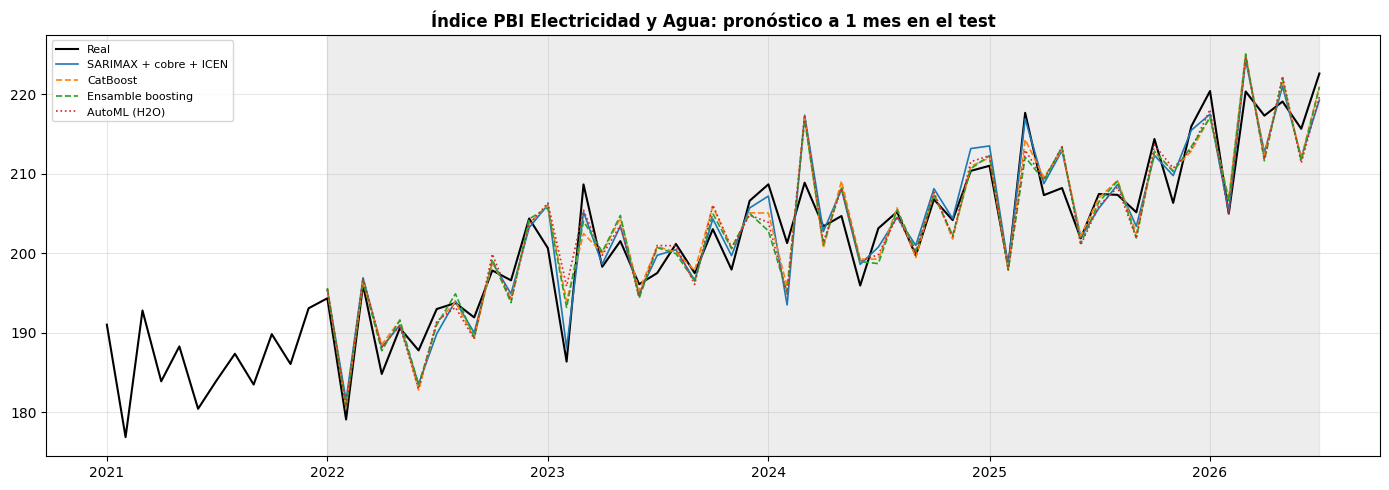

In [39]:
mejor_boosting = metricas_ml.drop(index='Ensamble')['RMSE'].idxmin()
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(indice['2021-01-01':], color='black', linewidth=1.5, label='Real')
for nombre, serie_pred, estilo in [('SARIMAX + cobre + ICEN', pronosticos_1m[etiqueta_final], '-'),
                                   (mejor_boosting, pronosticos_ml[mejor_boosting], '--'),
                                   ('Ensamble boosting', pronosticos_ml['Ensamble'], '--'),
                                   ('AutoML (H2O)', pronosticos_ml['AutoML (H2O)'], ':')]:
    ax.plot(serie_pred, linestyle=estilo, linewidth=1.2, label=nombre)
ax.axvspan(test.index[0], test.index[-1], color='lightgray', alpha=0.4)
ax.set_title('Índice PBI Electricidad y Agua: pronóstico a 1 mes en el test', fontweight='bold')
ax.grid(alpha=0.3); ax.legend(loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

**Diebold–Mariano** (sección 7): un estadístico negativo indica que el primer modelo tiene menor error cuadrático; la diferencia es significativa si p < 0,05.

In [40]:
pares = [('SARIMAX + cobre + ICEN', 'AutoML (H2O)'), ('SARIMAX + cobre + ICEN', 'Ensamble'),
         ('SARIMAX + cobre + ICEN', mejor_boosting), ('AutoML (H2O)', 'Ensamble')]
pares += [('AutoML (H2O)', nombre) for nombre in ['XGBoost', 'LightGBM', 'CatBoost']]
todos = {'SARIMAX + cobre + ICEN': pronosticos_1m[etiqueta_final], **pronosticos_ml}

dm_ml = []
for a, b in pares:
    dm, p = diebold_mariano(indice_test, todos[a], todos[b])
    dm_ml.append({'Comparación': f'{a} vs {b}', 'Estadístico DM': dm, 'p-valor': p,
                  'Conclusión': 'Sin diferencia significativa' if p >= alpha else
                                f'{a} es significativamente mejor' if dm < 0 else f'{b} es significativamente mejor'})
display(pd.DataFrame(dm_ml).drop_duplicates('Comparación').round(4))

,Comparación,Estadístico DM,p-valor,Conclusión
0,SARIMAX + cobre + ICEN vs AutoML (H2O),-1.9661,0.0493,SARIMAX + cobre + ICEN es significativamente m...
1,SARIMAX + cobre + ICEN vs Ensamble,-2.2228,0.0262,SARIMAX + cobre + ICEN es significativamente m...
2,SARIMAX + cobre + ICEN vs CatBoost,-1.8934,0.0583,Sin diferencia significativa
3,AutoML (H2O) vs Ensamble,0.5552,0.5788,Sin diferencia significativa
4,AutoML (H2O) vs XGBoost,-0.2801,0.7794,Sin diferencia significativa
5,AutoML (H2O) vs LightGBM,-0.5149,0.6066,Sin diferencia significativa
6,AutoML (H2O) vs CatBoost,0.9571,0.3385,Sin diferencia significativa


**Deciles del error absoluto.** Las métricas promedio (RMSE, MAE) pueden ocultar cómo se reparten los errores. Con los deciles de |real − pronóstico| se ve, por ejemplo, el error del mes típico (D5 = mediana) y el de los peores meses (D9: solo el 10 % de los meses tiene un error mayor).

Deciles del error absoluto a 1 mes (puntos del índice):


,D1,D2,D3,D4,D5,D6,D7,D8,D9,Máximo
SARIMA,0.31,0.69,0.97,1.27,1.69,2.15,2.59,3.70,4.17,9.48
SARIMAX + cobre + ICEN,0.35,0.75,1.09,1.32,1.76,1.98,2.64,3.35,4.13,8.48
Ensamble,0.60,1.13,1.48,1.75,1.99,2.84,3.23,4.34,5.40,7.88
AutoML (H2O),0.57,0.88,1.43,1.76,2.07,2.89,3.25,4.32,5.06,9.48
LightGBM,0.76,1.40,1.62,1.87,2.37,2.53,3.68,4.23,5.72,8.38
CatBoost,0.41,0.81,1.13,1.74,2.38,2.79,3.33,3.91,4.95,8.15
XGBoost,0.49,0.88,1.41,1.81,2.51,2.84,3.53,4.18,5.40,8.72
Ingenuo con último crecimiento,0.83,1.47,1.77,2.10,2.57,2.91,3.38,4.64,5.60,16.47


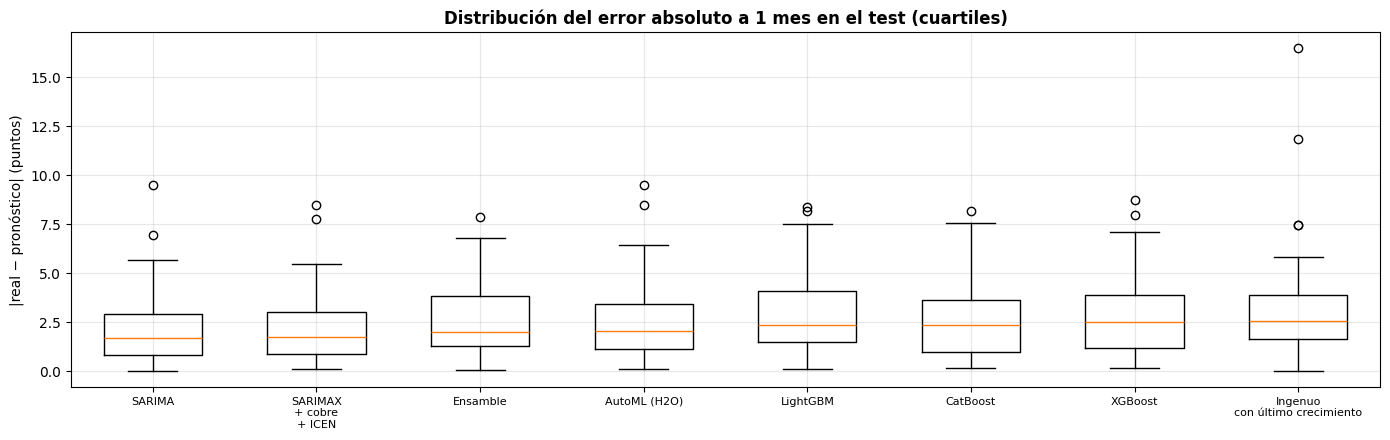

In [41]:
errores_abs = pd.DataFrame({nombre: (indice_test - pred).abs() for nombre, pred in {
    'SARIMAX + cobre + ICEN': pronosticos_1m[etiqueta_final], 'SARIMA': pronosticos_1m[etiqueta_sarima],
    **pronosticos_ml, 'Ingenuo con último crecimiento': pronosticos_1m['Ingenuo con último crecimiento']}.items()})
deciles_error = errores_abs.quantile(np.arange(0.1, 1.0, 0.1)).T
deciles_error.columns = [f'D{i}' for i in range(1, 10)]
deciles_error['Máximo'] = errores_abs.max()
deciles_error = deciles_error.sort_values('D5')
print('Deciles del error absoluto a 1 mes (puntos del índice):')
display(deciles_error.style.format('{:.2f}').highlight_min(color='#c6efce'))

plt.figure(figsize=(14, 4.5))
plt.boxplot([errores_abs[m] for m in deciles_error.index], widths=0.6)
plt.xticks(range(1, len(deciles_error) + 1), [m.replace(' + ', '\n+ ').replace(' con ', '\ncon ') for m in deciles_error.index], fontsize=8)
plt.ylabel('|real − pronóstico| (puntos)'); plt.grid(alpha=0.3)
plt.title('Distribución del error absoluto a 1 mes en el test (cuartiles)', fontweight='bold')
plt.tight_layout(); plt.show()

**Interpretación de la comparación final**

- **El mejor modelo sigue siendo el SARIMAX + cobre + ICEN.** Gana en todas las métricas (RMSE 2,75; MAE 2,14; MAPE 1,05 %; 1,39 pp en la variación interanual; IEC 0,702), seguido del SARIMA. El mejor modelo de Machine Learning, CatBoost, tiene un RMSE 16 % mayor (3,18) y AutoML, uno 20 % mayor (3,32).
- **Diebold–Mariano:** la ventaja del SARIMAX es significativa frente al ensamble (p = 0,026) y está cerca de serlo frente a CatBoost (p = 0,058). Frente a AutoML fue significativa en esta ejecución (p = 0,049), pero en otras ejecuciones el p-valor estuvo entre 0,07 y 0,13, así que esa conclusión no es robusta. Entre AutoML y los modelos de boosting no hay diferencias significativas (p ≥ 0,34): **AutoML no superó a los modelos ajustados a mano**, aunque llegó a un resultado similar sin elegir algoritmos ni hiperparámetros.
- **Deciles del error:** el SARIMAX y el SARIMA tienen errores menores en casi todos los deciles. En el mes típico (D5) se equivocan en 1,7–1,8 puntos, frente a 2,0–2,5 en los modelos de Machine Learning, y el 90 % de sus meses (D9) queda por debajo de 4,1–4,2 puntos, frente a 4,9–5,7. El ensamble tiene el menor error máximo (7,9 puntos): promediar modelos reduce los errores extremos, aunque no el típico. AutoML tiene el peor mes entre los modelos de Machine Learning (9,5 puntos).
- **¿Por qué gana la econometría en este caso?**
  1. **Pocos datos:** 227 meses de entrenamiento son pocos para árboles con 20 predictores.
  2. **Estructura muy regular:** la tendencia y la estacionalidad por calendario (sección 3.4) las captura el SARIMA con solo dos parámetros MA; los árboles tienen que aprenderlas a partir de los datos y con saltos discretos.
  3. **Los árboles no extrapolan:** eso obliga a modelar cambios mensuales en vez de niveles, y cualquier error en el cambio se traslada al índice.

  Los modelos de Machine Learning suelen ganar con muchas observaciones, relaciones no lineales o interacciones entre muchas variables, condiciones que esta serie mensual no tiene.
- **Recomendación:** mantener el SARIMAX como modelo principal para el pronóstico mensual del sector, por precisión e interpretabilidad (elasticidades del cobre y del ICEN). CatBoost puede servir como segunda opinión. Como mejora futura, se podría probar un ensamble SARIMAX + CatBoost o entrenar los árboles sobre los residuos del SARIMAX (modelo híbrido, como en la lectura L2 del curso).

### Tabla consolidada: todos los modelos

Reúne los **14 modelos** del notebook en el mismo escenario: pronóstico a 1 mes del índice en los 55 meses del test. Incluye los modelos econométricos de la sección 7 (AR, MA, ARMA, SARIMA y las tres versiones del SARIMAX), los de *boosting* y su ensamble (sección 10), AutoML (sección 11) y los dos ingenuos. Para los modelos econométricos se agregan el AIC, el BIC y si sus residuos pasan Ljung–Box; los modelos de Machine Learning no tienen esas medidas. El ranking ordena por RMSE.

In [42]:
def nombre_corto(etiqueta):
    # 'AR - AR(1, 1, 0)(0, 1, 0)12' -> 'AR(1, 1, 0)(0, 1, 0)12'; 'SARIMAX + cobre - (0, 1, 1)(...)12' -> 'SARIMAX(0, 1, 1)(...)12 + cobre'
    if ' - ' not in etiqueta:
        return etiqueta
    familia_m, orden_m = etiqueta.split(' - ', 1)
    return orden_m if familia_m in ('AR', 'MA', 'ARMA', 'SARIMA') else f"SARIMAX{orden_m}{familia_m.replace('SARIMAX', '')}"

econometricos = [e for e in pronosticos_1m if e in ajustes]
consolidada = tabla_metricas({**{nombre_corto(e): pronosticos_1m[e] for e in econometricos},
                              **pronosticos_ml,
                              **{e: pronosticos_1m[e] for e in pronosticos_1m if e not in ajustes}})
ajuste_train = resumen_metricas['Ajuste (train)'].dropna(how='all').rename(index=nombre_corto)
consolidada = ajuste_train.join(consolidada, how='right')
consolidada.insert(0, 'Tipo', ['Econometría' if m in ajuste_train.index else 'Referencia' if 'Ingenuo' in m
                               else 'AutoML' if 'AutoML' in m else 'Boosting' for m in consolidada.index])
consolidada.insert(4, '¿Pasa Ljung–Box?', np.where(consolidada['p-Ljung-Box(24)'].isna(), '—',
                                                    np.where(consolidada['p-Ljung-Box(24)'] >= alpha, 'Sí', 'No')))
consolidada = consolidada.sort_values('RMSE')
consolidada.insert(0, 'Ranking', range(1, len(consolidada) + 1))

columnas_error = ['MSE', 'RMSE', 'MAE', 'MAPE (%)', 'RMSE var. % (pp)', 'IEC']
display(consolidada.style
        .format('{:.4f}', subset=['AIC', 'BIC', 'p-Ljung-Box(24)'] + columnas_error, na_rep='—')
        .highlight_min(subset=columnas_error + ['AIC', 'BIC'], color='#c6efce')
        .set_caption('Todos los modelos - test a 1 mes, métricas sobre el índice (verde = mejor valor de cada columna)'))

,Ranking,Tipo,AIC,BIC,p-Ljung-Box(24),¿Pasa Ljung–Box?,MSE,RMSE,MAE,MAPE (%),RMSE var. % (pp),IEC
Modelo,,,,,,,,,,,,
"SARIMAX(0, 1, 1)(0, 1, 1)12 + cobre + ICEN",1,Econometría,709.1056,726.2304,0.3007,Sí,7.5794,2.7531,2.1351,1.0468,1.3935,0.7024
"SARIMAX(0, 1, 1)(0, 1, 1)12 + cobre",2,Econometría,712.1295,725.8293,0.4683,Sí,7.6698,2.7694,2.1116,1.0362,1.3992,0.7017
"SARIMAX(0, 1, 1)(0, 1, 1)12 + ICEN",3,Econometría,711.2907,724.9905,0.3065,Sí,7.8384,2.7997,2.1691,1.0640,1.4177,0.7059
"SARIMA(0, 1, 1)(0, 1, 1)12",4,Econometría,714.9946,725.2694,0.4536,Sí,7.9847,2.8257,2.1527,1.0568,1.4278,0.7060
CatBoost,5,Boosting,—,—,—,—,10.1180,3.1809,2.5738,1.2647,1.6204,0.7374
Ensamble,6,Boosting,—,—,—,—,10.4640,3.2348,2.6625,1.3059,1.6389,0.7425
AutoML (H2O),7,AutoML,—,—,—,—,10.9925,3.3155,2.6511,1.3034,1.6951,0.7442
XGBoost,8,Boosting,—,—,—,—,11.2837,3.3591,2.7062,1.3284,1.7085,0.7475
LightGBM,9,Boosting,—,—,—,—,11.9181,3.4523,2.8376,1.3892,1.7380,0.7547


**Interpretación de la tabla consolidada**

- **Los cuatro primeros puestos son los modelos econométricos estacionales:** las tres versiones del SARIMAX y el SARIMA, todos con residuos sin autocorrelación. Les siguen los modelos de Machine Learning (puestos 5 a 9), luego el MA, el ARMA y el AR sin parte estacional (puestos 10 a 12), que no pasan Ljung–Box, y al final los dos ingenuos.
- **Entre los SARIMAX las diferencias son mínimas.** El propuesto (cobre + ICEN) tiene el menor RMSE (2,75) y el menor error en la variación interanual (1,39 pp); el SARIMAX solo con cobre tiene el menor MAE, MAPE e IEC (MAPE 1,04 %; IEC 0,7017 frente a 0,7024), y el SARIMAX solo con ICEN, el menor BIC. Agregar exógenas mejora poco frente al SARIMA (RMSE de 2,83 a 2,75, un 2,6 % menos).
- **Lo que más pesa es modelar la estacionalidad.** Los AR, MA y ARMA sin parte estacional (RMSE 3,84 a 3,99) quedan por debajo de **todos** los modelos de Machine Learning (3,18 a 3,45), que sí la capturan con `lag_12` y `mes`. A su vez, ningún modelo de Machine Learning alcanza al SARIMA, que representa la estacionalidad con un solo parámetro.
- El AIC y el BIC solo se comparan entre modelos econométricos, porque se calculan sobre la misma serie transformada. Los modelos de Machine Learning no tienen una verosimilitud comparable.


## 13. Detección de anomalías con Isolation Forest (H2O)

Esta sección incorpora el notebook *Isolation Forest para Series de Tiempo* del curso. Los modelos anteriores pronostican la serie. Aquí el objetivo cambia: encontrar los meses en que el sector se comportó de forma inusual, sin etiquetas y sin un modelo de pronóstico.

**Objetivo de negocio:** identificar los meses de producción anormalmente alta o baja del sector Electricidad y Agua para revisarlos antes de usar el pronóstico en la planificación de la inversión. Un mes anómalo puede ser un shock puntual (la pandemia o El Niño Costero) o una señal de que el sector cambió de comportamiento.

**Objetivo de Machine Learning:** detectar esos meses con el modelo no supervisado **Isolation Forest** de H2O y contrastarlos con la regla 1,5·IQR (sección 3.4) y con los meses de la pandemia imputados en la sección 3.1.

**Cómo funciona.** Isolation Forest construye muchos árboles que parten los datos con cortes aleatorios. Un mes atípico queda aislado con pocos cortes, mientras que un mes normal necesita muchos. El promedio de cortes (`mean_length`) se transforma en un score `predict` entre 0 y 1: mientras más alto, más anómalo es el mes.

### 13.1. Preparación de los datos

In [44]:
# Calendario: la producción mensual depende del número de días del mes (febrero tiene 28 o 29, y el resto 30 o 31).
# Se trabaja con el índice por día calendario para que un año bisiesto no parezca una anomalía.
dias = pd.Series(indice_original.index.days_in_month, index=indice_original.index)
dias_previo = pd.Series((indice_original.index - pd.DateOffset(years=1)).days_in_month, index=indice_original.index)

def variables_if(ind):
    # Variables de entrada del Isolation Forest a partir de un índice mensual (con o sin pandemia imputada)
    var = (100 * (ind / ind.shift(12) - 1)).fillna(variacion_muestra)             # 2002: variación % del BCRP
    d = pd.DataFrame({'var_interanual_dia': 100 * ((1 + var / 100) * dias_previo / dias - 1),
                      'crec_mensual_dia': 100 * np.log(ind / dias).diff()})
    d['mes'] = d.index.month
    # Se resta la mediana de cada mes del año (estacionalidad residual); la mediana casi no se afecta por los atípicos
    d['crec_mensual_desest'] = d['crec_mensual_dia'] - d.groupby('mes')['crec_mensual_dia'].transform('median')
    return d.drop(columns='crec_mensual_dia').dropna()

variables = ['var_interanual_dia', 'crec_mensual_desest']
datos_if = variables_if(indice_original)       # serie real, sin imputar: así se puede probar si el modelo encuentra la pandemia
datos_if['pandemia'] = datos_if.index.isin(pandemia)

print('Periodo:', datos_if.index.min().strftime('%Y-%m'), 'a', datos_if.index.max().strftime('%Y-%m'), f'({len(datos_if)} meses)')
display(datos_if.head().round(2))
display(datos_if[variables].describe().T.round(2))

Periodo: 2002-02 a 2026-07 (294 meses)


,var_interanual_dia,mes,crec_mensual_desest,pandemia
2002-02-01,5.69,2,-0.55,False
2002-03-01,6.74,3,1.89,False
2002-04-01,10.16,4,1.24,False
2002-05-01,7.32,5,-1.67,False
2002-06-01,5.24,6,-2.33,False


,count,mean,std,min,25%,50%,75%,max
var_interanual_dia,294.0,4.78,4.46,-25.52,3.04,4.96,6.82,33.97
crec_mensual_desest,294.0,-0.07,1.87,-17.67,-0.74,0.00,0.60,11.89


### 13.2. Modelado

Se mantiene la configuración `ntrees = 1000` y `sample_rate = 0.1`. Cada árbol se construye con el 10 % de los meses (unos 29) y la semilla fija permite repetir el resultado. `predict` es el score de anomalía y `mean_length`, el número promedio de cortes que hizo falta para aislar el mes.

In [45]:
import h2o
from h2o.estimators import H2OIsolationForestEstimator

h2o.init(verbose=False)
h2o.no_progress()

def a_pandas(marco):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')   # aviso informativo de H2O al convertir a pandas
        return marco.as_data_frame()

data_if = h2o.H2OFrame(datos_if[variables].reset_index(drop=True))   # las filas conservan el orden de datos_if
modelo_if = H2OIsolationForestEstimator(ntrees=1000,          # número de árboles
                                        sample_rate=0.1,      # proporción de meses que usa cada árbol
                                        seed=1234)
modelo_if.train(x=variables, training_frame=data_if)

predicciones = a_pandas(modelo_if.predict(data_if))
predicciones.index = datos_if.index
display(predicciones.head().round(3))
print('Correlación entre predict y mean_length:', round(predicciones['predict'].corr(predicciones['mean_length']), 3))

,predict,mean_length
2002-02-01,0.081,5.675
2002-03-01,0.262,4.824
2002-04-01,0.371,4.309
2002-05-01,0.312,4.587
2002-06-01,0.394,4.200


Correlación entre predict y mean_length: -1.0


**Lectura del modelo**

- `predict` y `mean_length` tienen una correlación de −1,0. Mientras menos cortes se necesitan para aislar un mes, mayor es su score. Es la misma propiedad inversa que muestra el notebook del curso.

### 13.3. Estabilidad entre semillas

Un solo Isolation Forest depende del azar de sus cortes. Con 294 meses y árboles de apenas 29, dos semillas distintas pueden señalar meses distintos. Por eso se entrena el modelo con 10 semillas y se **promedia el score**. La estabilidad se mide con dos indicadores:

- **Spearman:** qué tan parecido es el orden de los 294 meses entre dos semillas (1 = idéntico).
- **Jaccard del top 5 %:** qué porcentaje de los meses señalados coincide entre dos modelos (1 = los mismos 15 meses). Además de comparar semillas sueltas, se compara el promedio de las semillas 1 a 5 con el de las semillas 6 a 10.

In [46]:
from itertools import combinations
from scipy.stats import spearmanr

def puntuar_if(datos, columnas, semillas):
    # Entrena un Isolation Forest de H2O por semilla y devuelve el score de cada mes (una columna por semilla)
    marco = h2o.H2OFrame(datos[columnas].reset_index(drop=True))
    scores = {}
    for semilla in semillas:
        m = H2OIsolationForestEstimator(ntrees=1000, sample_rate=0.1, seed=semilla)
        m.train(x=columnas, training_frame=marco)
        scores[f'semilla {semilla}'] = a_pandas(m.predict(marco))['predict'].values
    return pd.DataFrame(scores, index=datos.index)

def top_5(score):
    return set(score.index[score > score.quantile(0.95)])

def jaccard(a, b):
    return len(a & b) / len(a | b)

scores = puntuar_if(datos_if, variables, range(1, 11))
score_prom = scores.mean(axis=1).rename('score')

pares_semillas = list(combinations(scores.columns, 2))
mitad_1, mitad_2 = scores.iloc[:, :5].mean(axis=1), scores.iloc[:, 5:].mean(axis=1)
estabilidad = pd.Series({
    'Spearman entre semillas (promedio de los pares)': np.mean([spearmanr(scores[a], scores[b])[0] for a, b in pares_semillas]),
    'Jaccard del top 5 % entre semillas (promedio de los pares)': np.mean([jaccard(top_5(scores[a]), top_5(scores[b])) for a, b in pares_semillas]),
    'Jaccard del top 5 % entre dos promedios de 5 semillas': jaccard(top_5(mitad_1), top_5(mitad_2)),
}, name='Valor')
display(estabilidad.to_frame().round(2))

frecuencia = pd.Series({t: sum(t in top_5(scores[col]) for col in scores.columns) for t in scores.index})
print(f'Meses que al menos una semilla señala en su top 5 %: {int((frecuencia > 0).sum())} | '
      f'meses que señalan las 10 semillas: {int((frecuencia == 10).sum())} | máximo de semillas que coinciden en un mes: {int(frecuencia.max())}')

,Valor
Spearman entre semillas (promedio de los pares),0.87
Jaccard del top 5 % entre semillas (promedio de los pares),0.25
Jaccard del top 5 % entre dos promedios de 5 semillas,0.43


Meses que al menos una semilla señala en su top 5 %: 52 | meses que señalan las 10 semillas: 0 | máximo de semillas que coinciden en un mes: 8


**Lectura de la estabilidad**

- El orden general es parecido entre semillas (Spearman 0,87), pero los 15 meses del top 5 % coinciden poco: 25 % entre semillas sueltas y 43 % entre dos promedios de 5 semillas.
- Ningún mes aparece en el top 5 % de las 10 semillas. Los más repetidos (mayo, junio y julio de 2020) aparecen en 8 de 10, y en total 52 meses fueron señalados al menos una vez.
- Por eso el modelo se usa con el **score promedio**, y el top 5 % se lee como una lista de meses **para revisar** y no como una lista exacta de anomalías. Por la misma razón en 13.5 se trabaja con deciles.

### 13.4. Meses señalados como anomalías

El notebook del curso marca como anomalías los casos con score igual a 1 o superior a un percentil. Un score igual a 1 señalaría un solo mes, así que se usa el **percentil 95** del score promedio: los 15 meses con mayor score (el 5 % de 294).

Umbral (percentil 95 del score promedio): 0.632 | meses señalados: 15 de 294


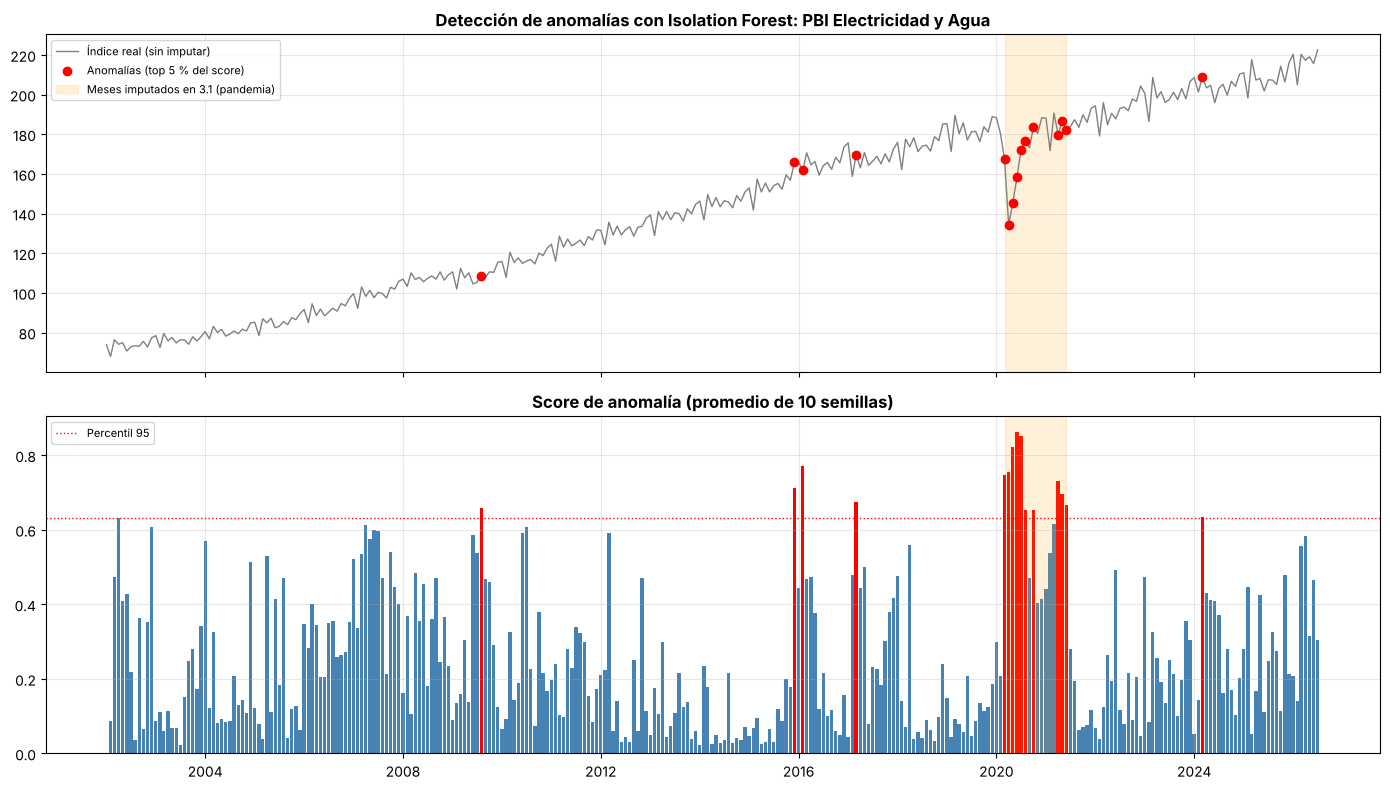

,Score,Índice,Var. % interanual (BCRP),Var. % interanual por día,Crec. mensual desest. (%),Pandemia (3.1),"Atípico 1,5·IQR (3.4)"
2020-06,0.86,158.30,-10.64,-10.64,11.89,Sí,Sí
2020-07,0.85,172.08,-5.03,-5.03,6.26,Sí,Sí
2020-05,0.82,145.43,-21.74,-21.74,5.29,Sí,Sí
2016-02,0.77,161.90,14.21,10.27,1.77,No,Sí
2020-04,0.76,134.26,-25.52,-25.52,-17.67,Sí,Sí
2020-03,0.75,167.30,-11.76,-11.76,-13.75,Sí,Sí
2021-04,0.73,179.86,33.97,33.97,-1.55,Sí,Sí
2015-12,0.71,165.78,9.89,9.89,1.69,No,No
2021-05,0.70,186.83,28.47,28.47,1.10,Sí,Sí
2017-03,0.68,169.64,-0.60,-0.60,-3.24,No,No


In [47]:
datos_if['score'] = score_prom
umbral = score_prom.quantile(0.95)
alertas = datos_if[datos_if['score'] > umbral].sort_values('score', ascending=False)
print(f'Umbral (percentil 95 del score promedio): {umbral:.3f} | meses señalados: {len(alertas)} de {len(datos_if)}')

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(indice_original, color='gray', linewidth=1, label='Índice real (sin imputar)')
axes[0].scatter(alertas.index, indice_original[alertas.index], color='red', zorder=3, label='Anomalías (top 5 % del score)')
axes[0].axvspan(pandemia[0], pandemia[-1], color='orange', alpha=0.15, label='Meses imputados en 3.1 (pandemia)')
axes[0].set_title('Detección de anomalías con Isolation Forest: PBI Electricidad y Agua', fontweight='bold')
axes[0].legend(loc='upper left', fontsize=8)
axes[1].bar(datos_if.index, datos_if['score'], width=25, color=np.where(datos_if['score'] > umbral, 'red', 'steelblue'))
axes[1].axhline(umbral, color='red', linestyle=':', linewidth=1, label='Percentil 95')
axes[1].axvspan(pandemia[0], pandemia[-1], color='orange', alpha=0.15)
axes[1].set_title('Score de anomalía (promedio de 10 semillas)', fontweight='bold')
axes[1].legend(loc='upper left', fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

tabla_alertas = pd.DataFrame({
    'Score': alertas['score'],
    'Índice': indice_original[alertas.index],
    'Var. % interanual (BCRP)': variacion_muestra[alertas.index],
    'Var. % interanual por día': alertas['var_interanual_dia'],
    'Crec. mensual desest. (%)': alertas['crec_mensual_desest'],
    'Pandemia (3.1)': np.where(alertas['pandemia'], 'Sí', 'No'),
    'Atípico 1,5·IQR (3.4)': np.where(alertas.index.isin(atipicos_var.index), 'Sí', 'No'),
})
tabla_alertas.index = tabla_alertas.index.strftime('%Y-%m')
display(tabla_alertas.round(2))

**Lectura de los meses señalados**

- **Pandemia:** 10 de los 15 meses son de la pandemia (marzo a agosto y octubre de 2020, y abril a junio de 2021). El modelo, sin saber nada de la pandemia, la encuentra. Además coincide con la regla 1,5·IQR de 3.4: 10 de sus 12 meses atípicos están en este top 5 %. Los dos que no (febrero y marzo de 2021) quedan en los deciles 9 y 10 (13.5).
- **Febrero de 2016:** en 3.4 se atribuyó a un posible efecto del año bisiesto. El ajuste por días confirma solo una parte: la variación baja de 14,2 % a 10,3 % y el mes sigue en el top 5 %.
- **Marzo de 2017:** el crecimiento mensual quedó 3,2 puntos por debajo de lo normal para un marzo. Coincide con el máximo del ICEN (1,31 °C en marzo de 2017, sección 6.2), aunque este notebook no prueba que esa sea la causa.
- **Diciembre de 2015, agosto de 2009 y marzo de 2024:** la regla del IQR no los detecta. Diciembre de 2015 creció 9,9 % (alto), mientras que agosto de 2009 y marzo de 2024 crecieron apenas 0,1 %. Para marzo de 2024 una hipótesis es la Semana Santa, que cayó en marzo y no en abril como en 2023. No se probó aquí.
- **Alcance:** el score mide qué tan raro es un mes, no por qué lo es. Estos meses son candidatos para revisar y no para eliminar.

### 13.5. Deciles del score

Siguiendo la tarea del notebook del curso, se forman **deciles del score** (D1 = 10 % de meses con menor score; D10 = 10 % con mayor score) para seleccionar los casos de revisión prioritaria. Se cuenta cuántos meses de la pandemia y cuántos atípicos del IQR caen en cada decil, y se mide el promedio del valor absoluto de la variación interanual por día. A diferencia del top 5 %, el decil 10 (30 meses) deja más margen frente a la inestabilidad entre semillas.

In [48]:
datos_if['decil_score'] = pd.qcut(datos_if['score'].rank(method='first'), 10, labels=range(1, 11)).astype(int)
datos_if['atipico_iqr'] = datos_if.index.isin(atipicos_var.index)

por_decil = datos_if.groupby('decil_score').agg(**{
    'Meses': ('score', 'size'),
    'Score mínimo': ('score', 'min'),
    'Score máximo': ('score', 'max'),
    'Meses de pandemia': ('pandemia', 'sum'),
    'Atípicos 1,5·IQR (3.4)': ('atipico_iqr', 'sum'),
    'Prom. |var. % interanual por día|': ('var_interanual_dia', lambda x: x.abs().mean()),
})
por_decil.index = [f'D{i}' for i in por_decil.index]
display(por_decil.round(3))

prioridad = datos_if[datos_if['decil_score'] == 10].sort_values('score', ascending=False)
print(f'Casos de revisión prioritaria (decil 10): {len(prioridad)} meses | {int(prioridad["pandemia"].sum())} son de la pandemia y '
      f'{int((~prioridad["pandemia"]).sum())} no')
print('Meses del decil 10 fuera de la pandemia:', ', '.join(prioridad.index[~prioridad['pandemia']].strftime('%Y-%m').sort_values()))

,Meses,Score mínimo,Score máximo,Meses de pandemia,"Atípicos 1,5·IQR (3.4)",Prom. |var. % interanual por día|
D1,30,0.024,0.051,0,0,4.951
D2,29,0.051,0.079,0,0,4.493
D3,29,0.079,0.112,0,0,5.419
D4,30,0.113,0.145,0,0,4.483
D5,29,0.148,0.205,0,0,4.916
D6,29,0.206,0.250,0,0,4.679
D7,30,0.256,0.346,0,0,4.980
D8,29,0.347,0.444,3,0,4.874
D9,29,0.444,0.541,2,1,5.120
D10,30,0.556,0.862,11,11,9.692


Casos de revisión prioritaria (decil 10): 30 meses | 11 son de la pandemia y 19 no
Meses del decil 10 fuera de la pandemia: 2002-04, 2002-12, 2004-01, 2007-04, 2007-05, 2007-06, 2007-07, 2009-06, 2009-08, 2010-06, 2010-07, 2012-03, 2015-12, 2016-02, 2017-03, 2018-04, 2024-03, 2026-03, 2026-04


**Lectura de los deciles**

- **Los 16 meses de la pandemia están en los deciles 8 a 10:** 11 en el D10, 2 en el D9 y 3 en el D8. Ninguno cae en D1 a D7. De los 12 atípicos del IQR, 11 están en el D10 y 1 en el D9.
- **Solo la cola superior se separa del resto.** El promedio de |variación interanual| es de 9,7 % en el D10 y se mantiene entre 4,5 % y 5,4 % del D1 al D9. El score ordena bien los meses más extremos, pero no sirve para ordenar los meses normales entre sí.
- **Casos de revisión prioritaria (D10):** son 30 meses, 11 de la pandemia y 19 no. Fuera de la pandemia aparecen 2002, 2007 (abril a julio), 2009, 2010, 2012, 2015, 2016, 2017, 2018, 2024 y 2026. En 2007 y 2010 son crecimientos de alrededor de 10 %, entre los más altos fuera de la pandemia. Marzo y abril de 2026 son los meses más recientes del decil 10, y conviene vigilarlos porque están cerca del final de la serie con la que se pronostica en la sección 9.

### 13.6. Contraste: nivel del índice, variable de mes y serie imputada

Se comparan cuatro configuraciones para justificar las decisiones de 13.1 y para revisar la imputación de 3.1. Todas usan el score promedio de 10 semillas. Los indicadores son:

- **Pandemia en el top 5 %:** cuántos de los 15 meses señalados son de marzo 2020 a junio 2021.
- **AUC (pandemia):** probabilidad de que un mes de la pandemia reciba más score que uno normal (0,5 = el modelo no los distingue). Es una referencia y no una medida exacta, porque trata los 16 meses como anómalos aunque algunos (como septiembre a diciembre de 2020) tuvieron cifras casi normales.
- **Top 5 % en 2002-2004 o 2024-2026:** cuántos meses señalados están en los extremos de la muestra, donde la tendencia hace que el nivel se vea raro.

In [49]:
from sklearn.metrics import roc_auc_score

def evaluar_if(nombre, datos, columnas, semillas=range(1, 11)):
    s = puntuar_if(datos, columnas, semillas).mean(axis=1)
    top = s[s > s.quantile(0.95)].index
    en_pandemia = datos.index.isin(pandemia)
    return {'Modelo': nombre, 'Variables': ', '.join(columnas),
            'Pandemia en el top 5 %': f'{int(top.isin(pandemia).sum())} de {len(top)}',
            'AUC (pandemia)': roc_auc_score(en_pandemia, s),
            'Top 5 % en 2002-2004 o 2024-2026': f'{int(((top.year <= 2004) | (top.year >= 2024)).sum())} de {len(top)}'}

# A. Como en el notebook de Bitcoin: el nivel del índice y una variable de calendario
datos_nivel = pd.DataFrame({'Close': indice_original, 'mes': indice_original.index.month})
# C. Mismas variables propuestas, pero sobre la serie con la pandemia ya imputada (3.1)
datos_imputada = variables_if(indice)

contraste = pd.DataFrame([
    evaluar_if('A. Nivel del índice + mes (como en Bitcoin)', datos_nivel, ['Close', 'mes']),
    evaluar_if('B. Variables propuestas, serie real', datos_if, variables),
    evaluar_if('B2. Variables propuestas + mes, serie real', datos_if, variables + ['mes']),
    evaluar_if('C. Variables propuestas, serie con pandemia imputada', datos_imputada, variables),
]).set_index('Modelo')
display(contraste.style.format({'AUC (pandemia)': '{:.3f}'}).set_caption('Las filas A, B y B2 usan la serie real; la fila C, la serie con la pandemia imputada en 3.1'))

,Variables,Pandemia en el top 5 %,AUC (pandemia),Top 5 % en 2002-2004 o 2024-2026
Modelo,,,,
A. Nivel del índice + mes (como en Bitcoin),"Close, mes",0 de 15,0.390,13 de 15
"B. Variables propuestas, serie real","var_interanual_dia, crec_mensual_desest",10 de 15,0.947,1 de 15
"B2. Variables propuestas + mes, serie real","var_interanual_dia, crec_mensual_desest, mes",7 de 15,0.954,4 de 15
"C. Variables propuestas, serie con pandemia imputada","var_interanual_dia, crec_mensual_desest",0 de 15,0.494,3 de 15


**Lectura del contraste**

- **A. Nivel del índice + mes (como en Bitcoin):** ningún mes de la pandemia entra al top 5 % (AUC 0,39, menor que 0,5) y 13 de 15 meses señalados están en los extremos de la muestra. El modelo marca el nivel alto o bajo de la tendencia y no los shocks. Justifica no usar el nivel.
- **B. Variables propuestas:** 10 de 15 meses son de la pandemia, el AUC es 0,947 y solo 1 mes está en los extremos.
- **B2. Agregar el mes:** el AUC sube un poco (0,954), pero el top 5 % empeora: baja a 7 los meses de la pandemia y sube a 4 los de los extremos. Como el crecimiento ya está sin estacionalidad, el mes agrega ruido y no se incluye.
- **C. Serie con la pandemia imputada:** ningún mes de la pandemia queda en el top 5 % y el AUC es 0,494, es decir, el modelo ya no distingue esos meses. Esto respalda la imputación de 3.1, aunque no prueba que los valores imputados sean los verdaderos.

### 13.7. Exportación y cierre del clúster H2O

Se exportan los casos del decil 10 ordenados por score a `data_anomalia_electricidad_agua.csv`, como en el notebook del curso. Después se apaga el clúster de H2O que se inició en la sección 11.

In [50]:
exportar = prioridad[['score', 'decil_score', 'var_interanual_dia', 'crec_mensual_desest', 'pandemia', 'atipico_iqr']].copy()
exportar.insert(1, 'indice', indice_original[exportar.index])
exportar.index = exportar.index.strftime('%Y-%m').rename('mes_anio')
exportar.to_csv('data_anomalia_electricidad_agua.csv', encoding='utf-8-sig')
print(f'Exportados {len(exportar)} meses del decil 10 a data_anomalia_electricidad_agua.csv')
exportar.head()

Exportados 30 meses del decil 10 a data_anomalia_electricidad_agua.csv


,score,indice,decil_score,var_interanual_dia,crec_mensual_desest,pandemia,atipico_iqr
mes_anio,,,,,,,
2020-06,0.861784,158.30426,10,-10.637539,11.894738,True,True
2020-07,0.850870,172.07960,10,-5.033480,6.255990,True,True
2020-05,0.822080,145.42855,10,-21.737977,5.287552,True,True
2016-02,0.770912,161.89611,10,10.272384,1.768665,False,True
2020-04,0.755430,134.25696,10,-25.515890,-17.672753,True,True


In [ ]:
h2o.cluster().shutdown()

## 14. Deep Learning: redes neuronales recurrentes (LSTM, GRU y bidireccionales)

Esta sección incorpora el notebook *12. Deep Learning RNN LSTM GRU* del curso. Allí se pronosticaba el precio diario del petróleo (CL=F) con dos redes recurrentes, **LSTM** y **GRU**. Aquí se aplican las mismas arquitecturas al índice del PBI de Electricidad y Agua y se agregan sus versiones **bidireccionales** (capa `Bidirectional`, que el notebook 12 importa pero no llega a usar).

**Objetivo de negocio:** el mismo de las secciones 7 y 10: pronosticar el índice del mes siguiente para planificar la inversión del sector.

**Objetivo de Deep Learning:** comprobar si una red recurrente, que aprende la dinámica directamente de la secuencia de los últimos meses, mejora al SARIMAX + cobre + ICEN y a los modelos de *boosting* en el mismo escenario: pronóstico a 1 mes en los 55 meses del test.

| Red | Cómo funciona | Capa de Keras |
|---|---|---|
| RNN simple | Un solo estado oculto que se actualiza mes a mes. Olvida rápido lo lejano (el gradiente se desvanece) | `SimpleRNN` (no se usa) |
| **LSTM** (*Long Short-Term Memory*) | Agrega una celda de memoria con tres compuertas (olvido, entrada y salida) que deciden qué guardar, qué agregar y qué entregar | `LSTM` |
| **GRU** (*Gated Recurrent Unit*) | Versión simplificada de la LSTM: dos compuertas (actualización y reinicio) y menos parámetros | `GRU` |
| **Bidireccional** | Dos capas recurrentes en paralelo: una lee la ventana del mes más antiguo al más reciente y la otra al revés; sus salidas se concatenan | `Bidirectional(LSTM(...))` y `Bidirectional(GRU(...))` |

**¿La red bidireccional "ve el futuro"?** No. Las dos direcciones leen la **misma ventana de meses ya observados** (*t* − 24 … *t* − 1); "hacia atrás" solo significa recorrer esa ventana desde el mes más reciente. El mes que se pronostica nunca entra a la red, así que el modelo es válido para pronosticar.

### 14.1. Adaptación del notebook 12 a esta serie

| Aspecto | Notebook 12 (petróleo) | Aquí (PBI Electricidad y Agua) | Motivo |
|---|---|---|---|
| Datos | 4 169 días | 294 meses con `Log_Return` (239 en train) | Serie mensual: hay muy pocos datos para una red |
| Train / test | 95 % / 5 % | Mismo corte de la sección 5 (test desde enero 2022) | Comparar con todos los modelos anteriores |
| Variable objetivo | Precio `High` en **nivel** | `Log_Return` del mes *t* (crecimiento mensual, sección 10); el índice se reconstruye con $\hat{I}_t = I_{t-1}\,e^{\widehat{\text{Log\_Return}}_t}$ | En el test, el índice supera el máximo de train (sección 10.1); escalado con los datos de train quedaría fuera del rango [0, 1] que la red aprendió |
| Escalamiento | `MinMaxScaler` ajustado con **todo** el dataset | `MinMaxScaler` ajustado **solo con train** | En el notebook 12 el escalador conoce el mínimo y el máximo del test: es una fuga de información |
| Ventana | 60 días | **24 meses** | 60 días de petróleo son ≈ 3 meses de calendario; la memoria de esta serie es de 12 a 13 meses (rezagos 1, 12 y 13, sección 4.3). 24 meses cubren dos ciclos estacionales y los rezagos 7 y 10 de las exógenas, y dejan 215 muestras de train (con 60 meses quedarían 179) |
| Variables por paso (3.ª dimensión) | 1 (precio) | 3 **sin exógenas** (Log_Return y el mes del año) o 5 **con exógenas** (además, crecimiento del cobre e ICEN) | El mes ayuda a ubicar el efecto calendario (sección 3.4). Las exógenas equivalen a pasar del SARIMA al SARIMAX |
| Arquitectura | 2 capas recurrentes + `Dense(25)` + `Dense(1)` | Igual (LSTM 128 → 64; GRU 50 → 64) y sus versiones bidireccionales | Mantener los modelos del curso |
| Entrenamiento | `adam`, MSE, `batch_size=1`, **1 época** | `adam`, MSE, `batch_size=1`, **5 épocas**, en **GPU** | Más pasadas por los datos |
| Semilla | No se fija | `set_random_seed(0)` y prueba con 3 semillas (sección 14.9) | Resultados reproducibles y medida del azar |

**Exógenas en la ventana.** En el SARIMAX hubo que elegir un rezago para cada exógena (7 meses para el cobre y 10 para el ICEN, sección 6.2). La red no lo necesita: la ventana de 24 meses ya contiene los rezagos 1 a 24 de cada variable, incluidos el 7 y el 10, y la red aprende cuáles le sirven. El cobre entra como su crecimiento mensual y no como precio, porque su nivel del test también supera al de train.

### 14.2. Librerías

Las redes se entrenan en la **GPU**. Keras 3 puede calcular con TensorFlow, PyTorch o JAX; en Windows, TensorFlow dejó de usar la GPU desde la versión 2.11, así que, si PyTorch detecta una GPU con CUDA, se usa **PyTorch** como motor de Keras. El código de las redes es el mismo con cualquier motor. Requisitos: `pip install keras` y PyTorch con CUDA (sin GPU, la sección corre igual en CPU).

In [51]:
import os
import time
import importlib.util
import joblib

# Si PyTorch ve una GPU con CUDA, Keras usa PyTorch como motor (debe definirse antes de importar keras)
gpu_torch = False
if importlib.util.find_spec('torch') is not None:
    import torch
    gpu_torch = torch.cuda.is_available()
if gpu_torch:
    os.environ['KERAS_BACKEND'] = 'torch'
    torch.backends.cudnn.deterministic = True   # cuDNN determinístico: con la misma semilla, el mismo resultado
    torch.backends.cudnn.benchmark = False

import keras
from keras.models import Sequential, load_model
from keras.layers import Input, Dense, LSTM, GRU, Bidirectional
from keras.utils import set_random_seed
from sklearn.preprocessing import MinMaxScaler

if keras.backend.backend() == 'torch':
    dispositivo = f'GPU {torch.cuda.get_device_name(0)}' if gpu_torch else 'CPU'
elif keras.backend.backend() == 'tensorflow':
    import tensorflow as tf
    dispositivo = 'GPU' if tf.config.list_physical_devices('GPU') else 'CPU'
else:
    dispositivo = 'CPU'
print('Keras', keras.__version__, '| motor:', keras.backend.backend(), '| dispositivo:', dispositivo)

Keras 3.15.1 | motor: torch | dispositivo: GPU NVIDIA GeForce RTX 4060 Laptop GPU


### 14.3. Preparación de los datos

Se arma una tabla mensual con las variables y se compara su rango en train y en test, como en la sección 10.1. Se incluye el índice en nivel (`Close`) para ver por qué no se usa como objetivo.

El **mes del año** entra como seno y coseno de $2\pi \cdot \text{mes}/12$. Con el número del mes (1 a 12), como en la sección 10, diciembre y enero quedarían en extremos opuestos; con el seno y el coseno quedan juntos, como en el calendario. Para un árbol no hace diferencia, pero para una red sí.

In [52]:
VENTANA = 24   # meses de historia que recibe la red (el notebook 12 usaba 60 días)
EPOCAS = 5     # pasadas completas por los datos de entrenamiento

datos_rnn = pd.DataFrame({
    'Log_Return': serie_tiempo['Log_Return'],     # crecimiento mensual del índice (sección 10)
    'ret_cobre': np.log(cobre / cobre.shift(1)),  # crecimiento mensual del precio del cobre
    'icen': icen,                                 # Índice Costero El Niño (°C)
}).loc[serie_tiempo.index].dropna()
datos_rnn['mes_sin'] = np.sin(2 * np.pi * datos_rnn.index.month / 12)   # mes del año como un ciclo
datos_rnn['mes_cos'] = np.cos(2 * np.pi * datos_rnn.index.month / 12)
en_train_rnn = datos_rnn.index < inicio_test

revision = pd.concat([serie_tiempo[['Close']].loc[datos_rnn.index], datos_rnn[['Log_Return', 'ret_cobre', 'icen']]], axis=1)
rango_rnn = pd.DataFrame({
    'Train mín.': revision[en_train_rnn].min(), 'Train máx.': revision[en_train_rnn].max(),
    'Test mín.': revision[~en_train_rnn].min(), 'Test máx.': revision[~en_train_rnn].max(),
    '% del test por encima del máx. de train': 100 * (revision[~en_train_rnn] > revision[en_train_rnn].max()).mean(),
})
escalado = MinMaxScaler().fit(revision[en_train_rnn]).transform(revision[~en_train_rnn])
rango_rnn['Test máx. escalado (MinMax de train)'] = escalado.max(axis=0)
print('Periodo:', datos_rnn.index.min().strftime('%Y-%m'), 'a', datos_rnn.index.max().strftime('%Y-%m'), f'({len(datos_rnn)} meses)')
display(rango_rnn.round(4))

Periodo: 2002-02 a 2026-07 (294 meses)


,Train mín.,Train máx.,Test mín.,Test máx.,% del test por encima del máx. de train,Test máx. escalado (MinMax de train)
Close,67.9233,196.3463,179.1029,222.6123,78.1818,1.2045
Log_Return,-0.1013,0.1176,-0.0817,0.1129,0.0000,0.9786
ret_cobre,-0.3542,0.2287,-0.1863,0.0980,0.0000,0.7757
icen,-1.6600,2.2300,-1.5100,3.3800,14.5455,1.2956


**Ventanas de 24 meses.** Igual que en el notebook 12, cada muestra de entrada es una ventana con los datos de los meses anteriores y la salida es el mes siguiente:

- `x`: los meses *t* − 24 … *t* − 1 de cada variable, escalados entre 0 y 1.
- `y`: el `Log_Return` escalado del mes *t*.

La entrada de una red recurrente es un arreglo de **tres dimensiones**: (muestras, pasos de tiempo, variables). En el notebook 12 era (3 901, 60, 1); aquí es (215, 24, 3) sin exógenas y (215, 24, 5) con exógenas. Los escaladores se ajustan solo con los meses de train. En el test, cada ventana usa los datos reales hasta el mes anterior: es el pronóstico a 1 mes de las secciones 7 y 10.

In [53]:
def crear_ventanas(columnas, ventana=VENTANA, corte=inicio_test):
    # Escaladores ajustados SOLO con los meses anteriores al corte (el notebook 12 los ajustaba con todo el dataset)
    en_train = datos_rnn.index < corte
    escalador_x = MinMaxScaler(feature_range=(0, 1)).fit(datos_rnn.loc[en_train, columnas])
    escalador_y = MinMaxScaler(feature_range=(0, 1)).fit(datos_rnn.loc[en_train, ['Log_Return']])
    x_esc = escalador_x.transform(datos_rnn[columnas])
    y_esc = escalador_y.transform(datos_rnn[['Log_Return']])[:, 0]

    x, y = [], []
    for i in range(ventana, len(datos_rnn)):
        x.append(x_esc[i - ventana:i, :])   # meses t-ventana ... t-1 de todas las variables
        y.append(y_esc[i])                  # Log_Return del mes t
    x, y = np.array(x, dtype='float32'), np.array(y, dtype='float32')   # x ya tiene 3 dimensiones
    fechas = datos_rnn.index[ventana:]
    es_train = fechas < corte
    return {'columnas': columnas, 'x_train': x[es_train], 'y_train': y[es_train], 'fechas_train': fechas[es_train],
            'x_test': x[~es_train], 'fechas_test': fechas[~es_train],
            'escalador_x': escalador_x, 'escalador_y': escalador_y}

conjuntos_rnn = {'Sin exógenas': ['Log_Return', 'mes_sin', 'mes_cos'],
                 'Con exógenas': ['Log_Return', 'ret_cobre', 'icen', 'mes_sin', 'mes_cos']}
ventanas_rnn = {nombre: crear_ventanas(columnas) for nombre, columnas in conjuntos_rnn.items()}

for nombre, v in ventanas_rnn.items():
    assert v['fechas_test'].equals(X_test_ml.index)   # mismos 55 meses de test que las secciones 7 y 10
    print(f"{nombre:<13} x_train {v['x_train'].shape} | y_train {v['y_train'].shape} | x_test {v['x_test'].shape} "
          f"| train {v['fechas_train'][0]:%Y-%m} a {v['fechas_train'][-1]:%Y-%m} | test {v['fechas_test'][0]:%Y-%m} a {v['fechas_test'][-1]:%Y-%m}")

# Ejemplo: últimos 3 meses de la primera ventana de train (valores escalados) y su objetivo
v = ventanas_rnn['Con exógenas']
print(f"\nPrimera muestra de train: objetivo = Log_Return de {v['fechas_train'][0]:%Y-%m} (escalado {v['y_train'][0]:.4f})")
display(pd.DataFrame(v['x_train'][0][-3:], columns=v['columnas'],
                     index=pd.date_range(end=v['fechas_train'][0] - pd.offsets.MonthBegin(1), periods=3, freq='MS').strftime('%Y-%m')).round(4))

Sin exógenas  x_train (215, 24, 3) | y_train (215,) | x_test (55, 24, 3) | train 2004-02 a 2021-12 | test 2022-01 a 2026-07
Con exógenas  x_train (215, 24, 5) | y_train (215,) | x_test (55, 24, 5) | train 2004-02 a 2021-12 | test 2022-01 a 2026-07

Primera muestra de train: objetivo = Log_Return de 2004-02 (escalado 0.2506)


,Log_Return,ret_cobre,icen,mes_sin,mes_cos
2003-11,0.3352,0.7178,0.4833,0.25,0.933
2003-12,0.5927,0.7307,0.4524,0.50,1.000
2004-01,0.6089,0.7641,0.4319,0.75,0.933


### 14.4. Modelado: arquitectura de las redes

Se usa la arquitectura del notebook 12 para cada red:

1. Capa recurrente con `return_sequences=True` y activación `relu` (128 neuronas en la LSTM y 50 en la GRU): entrega una salida por cada mes de la ventana.
2. Segunda capa recurrente de 64 neuronas con `return_sequences=False`: resume la ventana en un solo vector.
3. `Dense(25)` y `Dense(1)`: la salida es el `Log_Return` escalado del mes *t*.

En las versiones bidireccionales, cada capa recurrente se envuelve en `Bidirectional`, que duplica sus neuronas (una copia por dirección). Se compila con el optimizador `adam` y el error cuadrático medio como pérdida, como en el notebook 12. En una red recurrente, el número de parámetros **no depende del largo de la ventana**: los mismos pesos se aplican a cada mes.

In [54]:
def crear_red(tipo, bidireccional, n_variables, ventana=VENTANA, nombre=None):
    # Arquitectura del notebook 12: 2 capas recurrentes + Dense(25) + Dense(1)
    Capa, neuronas = (LSTM, 128) if tipo == 'LSTM' else (GRU, 50)
    envolver = Bidirectional if bidireccional else (lambda capa: capa)
    red = Sequential(name=nombre)
    red.add(Input(shape=(ventana, n_variables)))
    red.add(envolver(Capa(neuronas, return_sequences=True, activation='relu')))
    red.add(envolver(Capa(64, return_sequences=False)))
    red.add(Dense(25))
    red.add(Dense(1))
    red.compile(optimizer='adam', loss='mean_squared_error')
    return red

arquitecturas = {'LSTM': ('LSTM', False), 'GRU': ('GRU', False),
                 'LSTM bidireccional': ('LSTM', True), 'GRU bidireccional': ('GRU', True)}

filas = []
for nombre, (tipo, bid) in arquitecturas.items():
    neuronas, copias = (128 if tipo == 'LSTM' else 50), (2 if bid else 1)
    capa1 = f'{tipo}({neuronas}, relu)'
    capa2 = f'{tipo}(64)'
    filas.append({'Red': nombre,
                  'Capa 1': f'Bidirectional({capa1})' if bid else capa1, 'Capa 2': f'Bidirectional({capa2})' if bid else capa2,
                  'Salida capa 1': f'({VENTANA}, {neuronas * copias})', 'Salida capa 2': f'({64 * copias},)',
                  'Parámetros (3 variables)': crear_red(tipo, bid, 3).count_params(),
                  'Parámetros (5 variables)': crear_red(tipo, bid, 5).count_params()})
arquitectura_rnn = pd.DataFrame(filas).set_index('Red')
display(arquitectura_rnn)
print(f"Muestras de entrenamiento: {len(ventanas_rnn['Con exógenas']['y_train'])} "
      f"(el notebook 12 tenía 3 901 muestras para 117 619 parámetros)")
crear_red('LSTM', True, 5, nombre='LSTM_bidireccional').summary()

,Capa 1,Capa 2,Salida capa 1,Salida capa 2,Parámetros (3 variables),Parámetros (5 variables)
Red,,,,,,
LSTM,"LSTM(128, relu)",LSTM(64),"(24, 128)","(64,)",118643,119667
GRU,"GRU(50, relu)",GRU(64),"(24, 50)","(64,)",32173,32473
LSTM bidireccional,"Bidirectional(LSTM(128, relu))",Bidirectional(LSTM(64)),"(24, 256)","(128,)",302771,304819
GRU bidireccional,"Bidirectional(GRU(50, relu))",Bidirectional(GRU(64)),"(24, 100)","(128,)",83495,84095


Muestras de entrenamiento: 215 (el notebook 12 tenía 3 901 muestras para 117 619 parámetros)


Model: "LSTM_bidireccional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_8 (Bidirectional) │ (None, 24, 256)        │       137,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_9 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 25)             │         3,225 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 304,819 (1.16 MB)

 Trainable params: 304,819 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

### 14.5. Elección de las variables con una validación dentro de train

Una decisión no viene del notebook 12: **agregar el mes del año**. Para tomarla **sin mirar el test**, se separó un periodo de validación dentro de train: las redes se entrenan con los objetivos hasta diciembre 2016 y se evalúan con el pronóstico a 1 mes de **enero 2017 a diciembre 2019** (36 meses, antes de la pandemia), con las 4 arquitecturas, ventana de 24 meses, 5 épocas y la semilla 0. Los escaladores se ajustan solo con los meses previos a 2017.

| Red | Univariada | Univariada + mes | Con exógenas | Con exógenas + mes |
|---|---|---|---|---|
| LSTM | 8,447 | **6,868** | 8,670 | 8,614 |
| GRU | 5,274 | **4,845** | 5,692 | 4,919 |
| LSTM bidireccional | 3,368 | 3,264 | 3,603 | **3,256** |
| GRU bidireccional | 3,215 | **3,072** | 3,478 | 3,405 |
| *Referencia: ingenuo con último crecimiento* | *3,072* | | | |

*RMSE del índice a 1 mes en la validación 2017–2019 (en negrita, el mejor diseño de cada red).*

**Lectura de la validación**

- **El mes del año mejora a las 8 redes** (4 arquitecturas, con y sin exógenas). Por ejemplo, la LSTM baja de 8,45 a 6,87 y la GRU bidireccional de 3,22 a 3,07. Por eso las dos versiones de la red lo incluyen: **sin exógenas** (Log_Return + mes) y **con exógenas** (Log_Return + cobre + ICEN + mes).
- **Las exógenas no mejoran la validación**: con el mes incluido, empeoran a la LSTM, la GRU y la GRU bidireccional, y en la LSTM bidireccional dan un empate (3,256 frente a 3,264). Aun así, se mantienen las dos versiones para compararlas en el test, igual que el SARIMA y el SARIMAX.
- La mejor red de la validación (GRU bidireccional, 3,07) **solo empata con el ingenuo con último crecimiento**. Es una primera señal de que, con 5 épocas y pocos datos, las redes aprenden la estacionalidad pero poco más.

La celda siguiente repite esta validación. Está desactivada (`VALIDAR = False`) porque son 16 entrenamientos (≈ 15 a 20 minutos en GPU con `batch_size=1`). La tabla de arriba se calculó en CPU; en GPU los valores cambian algo, sobre todo los de la LSTM simple, que con 5 épocas está al límite de aprender la estacionalidad.

In [55]:
VALIDAR = False   # True: repite la validación de esta sección (16 entrenamientos)
corte_val, fin_val = pd.Timestamp('2017-01-01'), pd.Timestamp('2019-12-01')

def rmse_validacion(columnas, ventana, tipo, bidireccional, semilla=0):
    # Entrena con los objetivos anteriores a 2017 y mide el RMSE del índice a 1 mes en 2017-2019
    v = crear_ventanas(columnas, ventana, corte=corte_val)
    evaluar = v['fechas_test'] <= fin_val
    set_random_seed(semilla)
    red = crear_red(tipo, bidireccional, len(columnas), ventana)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        red.fit(v['x_train'], v['y_train'], batch_size=1, epochs=EPOCAS, verbose=0)
        pred = v['escalador_y'].inverse_transform(red.predict(v['x_test'][evaluar], verbose=0))[:, 0]
    fechas = v['fechas_test'][evaluar]
    return np.sqrt(mean_squared_error(indice[fechas], indice.shift(1)[fechas].values * np.exp(pred)))

if VALIDAR:
    disenos = {'Univariada': ['Log_Return'], 'Univariada + mes': conjuntos_rnn['Sin exógenas'],
               'Con exógenas': ['Log_Return', 'ret_cobre', 'icen'], 'Con exógenas + mes': conjuntos_rnn['Con exógenas']}
    tabla_diseno = pd.DataFrame({d: {n: rmse_validacion(c, VENTANA, *a) for n, a in arquitecturas.items()} for d, c in disenos.items()})
    print('RMSE de validación según las variables (ventana de 24 meses):'); display(tabla_diseno.round(3))
else:
    print('Validación no ejecutada (VALIDAR = False): sus resultados están en la tabla de arriba.')

Validación no ejecutada (VALIDAR = False): sus resultados están en la tabla de arriba.


### 14.6. Entrenamiento con 5 épocas

Se entrenan las 8 redes (4 arquitecturas × 2 conjuntos de variables) con `batch_size=1` y **5 épocas**. Antes de cada red se fija la misma semilla, así que los resultados se repiten en cada ejecución. La tabla muestra la pérdida de entrenamiento (MSE sobre el `Log_Return` escalado) al final de cada época.

Nota sobre la GPU: con `batch_size=1` cada paso procesa una sola ventana, así que la GPU pasa la mayor parte del tiempo esperando datos y no es más rápida que la CPU. Su ventaja aparece con lotes grandes; aquí se mantiene `batch_size=1` porque, con solo 5 épocas, lotes grandes darían muy pocas actualizaciones de los pesos (5 épocas × 14 lotes de 16 = 70, frente a 5 × 215 = 1 075).

Sin exógenas  LSTM                 80.3 s en GPU NVIDIA GeForce RTX 4060 Laptop GPU | pérdida época 5: 0.01002


Sin exógenas  GRU                  93.5 s en GPU NVIDIA GeForce RTX 4060 Laptop GPU | pérdida época 5: 0.01282


Sin exógenas  LSTM bidireccional  139.0 s en GPU NVIDIA GeForce RTX 4060 Laptop GPU | pérdida época 5: 0.00671


Sin exógenas  GRU bidireccional   169.1 s en GPU NVIDIA GeForce RTX 4060 Laptop GPU | pérdida época 5: 0.00620


Con exógenas  LSTM                 77.0 s en GPU NVIDIA GeForce RTX 4060 Laptop GPU | pérdida época 5: 0.01032


Con exógenas  GRU                  92.1 s en GPU NVIDIA GeForce RTX 4060 Laptop GPU | pérdida época 5: 0.01448


Con exógenas  LSTM bidireccional  142.4 s en GPU NVIDIA GeForce RTX 4060 Laptop GPU | pérdida época 5: 0.00663


Con exógenas  GRU bidireccional   167.0 s en GPU NVIDIA GeForce RTX 4060 Laptop GPU | pérdida época 5: 0.00624


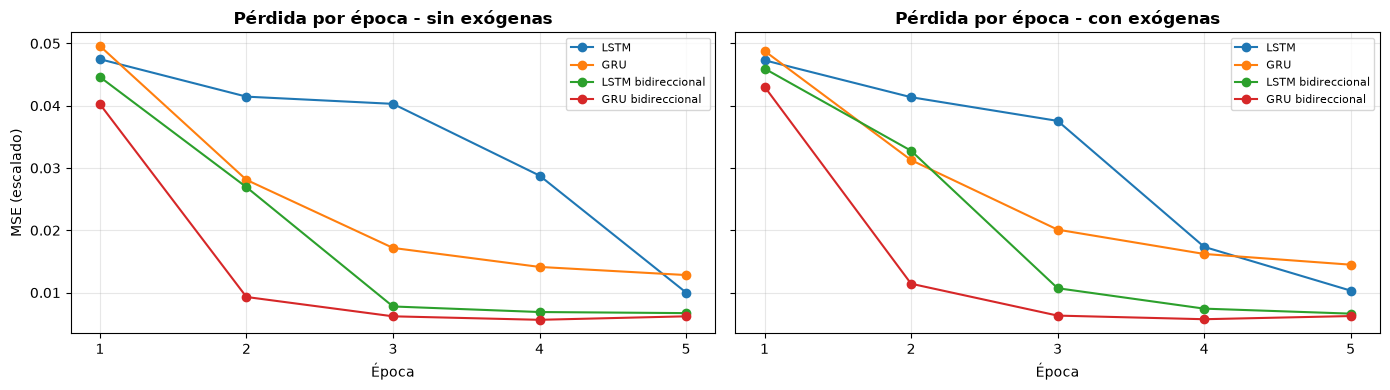

In [56]:
redes_rnn, historial_rnn, pronosticos_rnn, tiempos_rnn = {}, {}, {}, {}
for conjunto, v in ventanas_rnn.items():
    for nombre, (tipo, bid) in arquitecturas.items():
        set_random_seed(0)
        red = crear_red(tipo, bid, len(v['columnas']))
        inicio = time.time()
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')   # aviso de rendimiento de cuDNN sobre la memoria de los pesos
            h = red.fit(v['x_train'], v['y_train'], batch_size=1, epochs=EPOCAS, verbose=0)
            prediccion = v['escalador_y'].inverse_transform(red.predict(v['x_test'], verbose=0))[:, 0]
        redes_rnn[(conjunto, nombre)] = red
        historial_rnn[(conjunto, nombre)] = h.history['loss']
        tiempos_rnn[(conjunto, nombre)] = time.time() - inicio
        pronosticos_rnn[(conjunto, nombre)] = a_indice_ml(prediccion)   # índice: I(t-1) · e^(Log_Return pronosticado)
        print(f'{conjunto:<13} {nombre:<19} {tiempos_rnn[(conjunto, nombre)]:5.1f} s en {dispositivo} | pérdida época {EPOCAS}: {h.history["loss"][-1]:.5f}')

tabla_epocas = pd.DataFrame(historial_rnn, index=pd.Index(range(1, EPOCAS + 1), name='Época'))
display(tabla_epocas.style.format('{:.5f}').highlight_min(color='#c6efce')
        .set_caption('Pérdida de entrenamiento por época (MSE del Log_Return escalado)'))

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, conjunto in zip(axes, ventanas_rnn):
    for nombre in arquitecturas:
        ax.plot(tabla_epocas.index, tabla_epocas[(conjunto, nombre)], marker='o', label=nombre)
    ax.set_title(f'Pérdida por época - {conjunto.lower()}', fontweight='bold'); ax.set_xlabel('Época'); ax.set_xticks(tabla_epocas.index)
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[0].set_ylabel('MSE (escalado)')
plt.tight_layout(); plt.show()

**Interpretación del entrenamiento (5 épocas)**

- **¿Qué significa la pérdida?** La varianza del `Log_Return` escalado en train es **0,038**: una red que predice siempre el promedio tiene una pérdida de ≈ 0,04, es decir, no aprendió nada. Como referencia, repetir el crecimiento del mismo mes del año anterior (el efecto calendario) da una pérdida de **0,005**.
- **Las bidireccionales aprenden rápido.** La GRU bidireccional baja de 0,040 a 0,009 ya en la época 2 y la LSTM bidireccional de 0,045 a 0,008 en la época 3. Después casi no bajan (≈ 0,006, cerca de la referencia del efecto calendario), así que 5 épocas les alcanzan.
- **La LSTM simple es la más lenta.** Se queda en ≈ 0,04 durante tres épocas (sin aprender) y recién en las épocas 4 y 5 baja a ≈ 0,010; al final todavía está bajando, así que 5 épocas no le alcanzan para terminar de aprender. La GRU simple baja de forma gradual y termina en 0,013 (sin exógenas) y 0,014 (con exógenas).
- **Las exógenas casi no cambian la pérdida final:** en las bidireccionales es 0,0062 a 0,0067 con y sin cobre e ICEN.
- **Tiempo en GPU:** 77 a 94 s las redes simples y 139 a 169 s las bidireccionales, que tienen el doble de capas recurrentes.

### 14.7. Evaluación: tabla de métricas de LSTM, GRU y bidireccionales (5 épocas)

Igual que en el notebook 12 se calculan el MSE, RMSE, MAE y MAPE, pero sobre el **índice** reconstruido y con la función `tabla_metricas` de la sección 10, que agrega el error en la variación interanual y el IEC. Así las métricas son comparables con todos los modelos anteriores.

In [57]:
metricas_rnn = pd.concat({conjunto: tabla_metricas({nombre: pronosticos_rnn[(conjunto, nombre)] for nombre in arquitecturas})
                          for conjunto in ventanas_rnn}, names=['Variables', 'Modelo'])
display(metricas_rnn.style.format('{:.4f}').highlight_min(color='#c6efce')
        .set_caption(f'LSTM, GRU y bidireccionales con {EPOCAS} épocas - test a 1 mes, métricas sobre el índice (verde = mejor valor)'))

# Tabla al estilo del notebook 12 (MSE, RMSE, MAE y MAPE), una por conjunto de variables
for conjunto in ventanas_rnn:
    metricas_df = metricas_rnn.loc[conjunto, ['MSE', 'RMSE', 'MAE', 'MAPE (%)']].reset_index()
    print(f'\n{conjunto} ({len(conjuntos_rnn[conjunto])} variables por mes):')
    display(metricas_df.round(4))

print('\nReferencia (sección 12):')
display(comparacion_final.loc[['SARIMAX + cobre + ICEN', 'SARIMA', 'CatBoost', 'Ingenuo con último crecimiento'],
                              ['MSE', 'RMSE', 'MAE', 'MAPE (%)']].round(4))


Sin exógenas (3 variables por mes):


,Modelo,MSE,RMSE,MAE,MAPE (%)
0,LSTM,19.2574,4.3883,3.4174,1.6878
1,GRU,21.4912,4.6359,3.6119,1.7874
2,LSTM bidireccional,12.9607,3.6001,2.7860,1.3809
3,GRU bidireccional,11.1410,3.3378,2.5579,1.2696



Con exógenas (5 variables por mes):


,Modelo,MSE,RMSE,MAE,MAPE (%)
0,LSTM,17.9199,4.2332,3.5364,1.7442
1,GRU,26.9664,5.1929,3.9156,1.9507
2,LSTM bidireccional,13.3700,3.6565,3.0045,1.4929
3,GRU bidireccional,12.9726,3.6018,2.9648,1.4723



Referencia (sección 12):


,MSE,RMSE,MAE,MAPE (%)
Modelo,,,,
SARIMAX + cobre + ICEN,7.5794,2.7531,2.1350,1.0468
SARIMA,7.9847,2.8257,2.1527,1.0568
CatBoost,10.1180,3.1809,2.5738,1.2647
Ingenuo con último crecimiento,17.9053,4.2315,3.2136,1.5670


### 14.8. Visualización de las predicciones

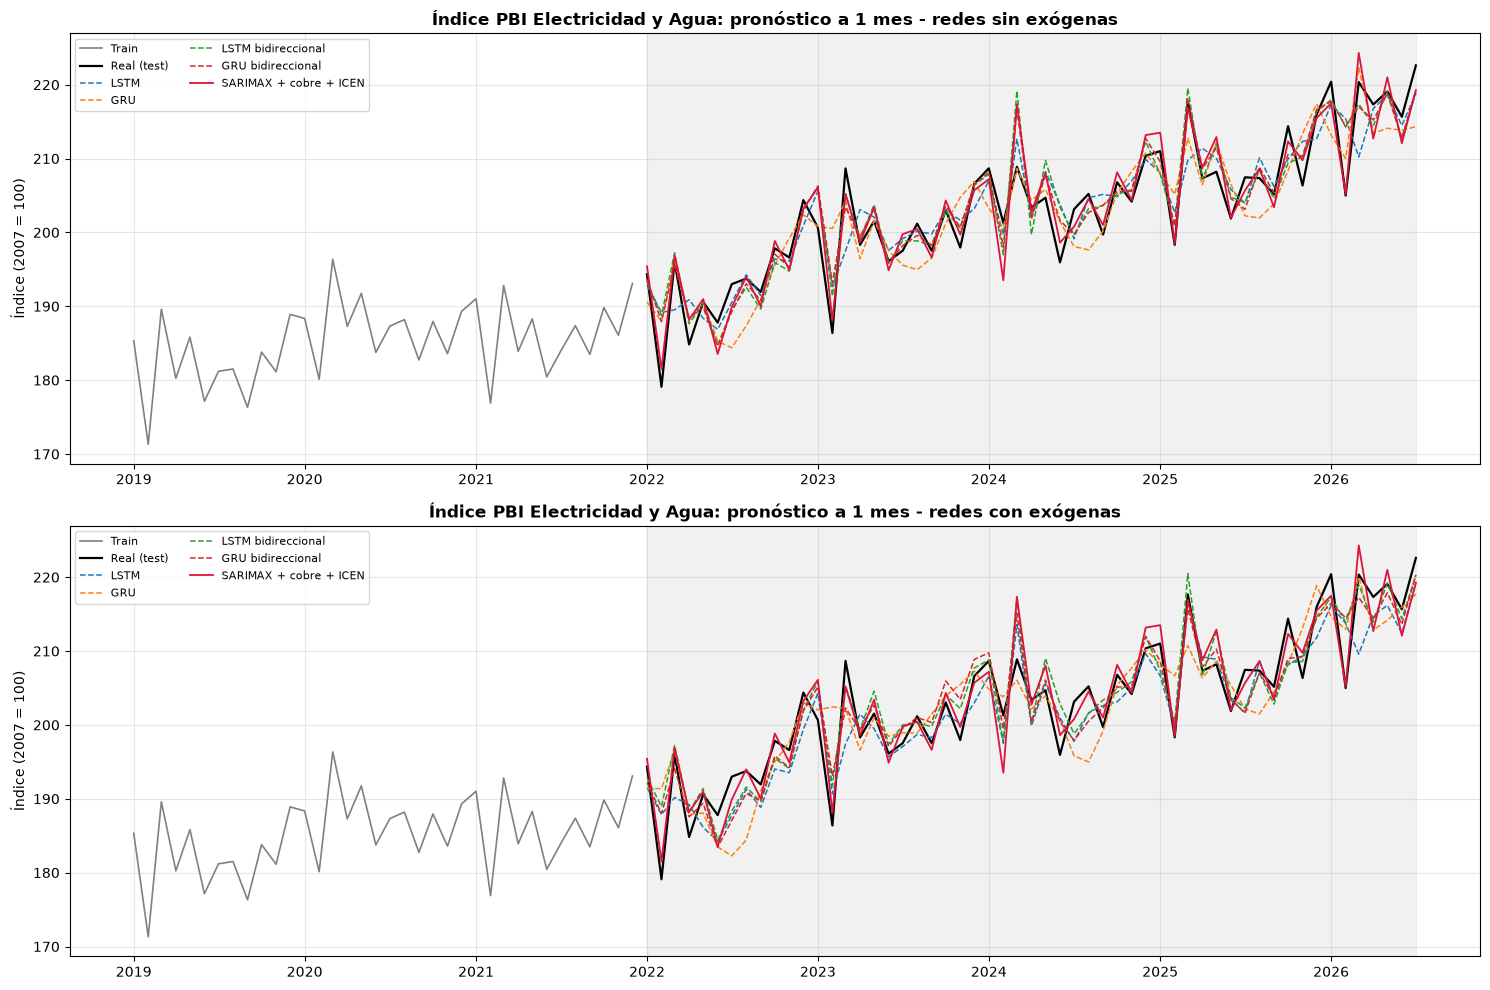

Real vs pronosticado (redes sin exógenas), últimos 12 meses del test:


,Real,LSTM,GRU,LSTM bidireccional,GRU bidireccional,SARIMAX + cobre + ICEN
2025-08,207.35,210.10,201.96,208.38,208.81,208.65
2025-09,205.16,206.21,203.87,204.59,205.35,203.39
2025-10,214.38,209.96,208.37,209.37,210.55,212.32
2025-11,206.35,212.33,213.38,210.25,210.32,209.77
2025-12,215.97,212.69,217.39,216.34,216.66,215.48
2026-01,220.41,217.28,213.19,217.96,217.73,217.50
2026-02,204.99,215.39,210.02,214.26,214.38,205.19
2026-03,220.35,210.22,222.35,217.39,217.02,224.30
2026-04,217.32,216.76,213.41,214.45,215.21,212.69
2026-05,219.09,218.63,214.11,219.08,218.78,221.00


In [58]:
fig, axes = plt.subplots(2, 1, figsize=(15, 10))
for ax, conjunto in zip(axes, ventanas_rnn):
    ax.plot(indice['2019-01-01':inicio_test - pd.DateOffset(months=1)], color='gray', linewidth=1.2, label='Train')
    ax.plot(indice_test, color='black', linewidth=1.6, label='Real (test)')
    for nombre in arquitecturas:
        ax.plot(pronosticos_rnn[(conjunto, nombre)], linestyle='--', linewidth=1.1, label=nombre)
    ax.plot(pronosticos_1m[etiqueta_final], color='crimson', linewidth=1.3, label='SARIMAX + cobre + ICEN')
    ax.axvspan(test.index[0], test.index[-1], color='lightgray', alpha=0.3)
    ax.set_title(f'Índice PBI Electricidad y Agua: pronóstico a 1 mes - redes {conjunto.lower()}', fontweight='bold')
    ax.set_ylabel('Índice (2007 = 100)'); ax.grid(alpha=0.3); ax.legend(loc='upper left', fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

# Valores reales vs pronosticados (como la tabla "valid" del notebook 12)
mejor_conjunto = metricas_rnn.groupby(level='Variables')['RMSE'].min().idxmin()
valid = pd.concat({'Real': indice_test, **{nombre: pronosticos_rnn[(mejor_conjunto, nombre)] for nombre in arquitecturas},
                   'SARIMAX + cobre + ICEN': pronosticos_1m[etiqueta_final]}, axis=1)
valid.index = valid.index.strftime('%Y-%m')
print(f'Real vs pronosticado (redes {mejor_conjunto.lower()}), últimos 12 meses del test:')
display(valid.tail(12).round(2))

**Interpretación de las métricas (5 épocas, semilla 0)**

- **La mejor red es la GRU bidireccional sin exógenas:** RMSE 3,34 puntos y MAPE 1,27 %, seguida de la LSTM bidireccional sin exógenas (3,60; 1,38 %). Las bidireccionales superan a la LSTM y a la GRU simples (RMSE 4,23 a 5,19), como anticipaba la pérdida: son las que alcanzan a aprender en 5 épocas.
- **Ninguna red supera al SARIMAX** (2,75; 1,05 %) ni al SARIMA (2,83). La mejor red tiene un RMSE 21 % mayor que el SARIMAX y queda cerca de CatBoost (3,18). En la variación interanual se equivoca en 1,73 pp, frente a 1,39 pp del SARIMAX.
- **Las exógenas no ayudan a las redes:** con cobre e ICEN el RMSE sube en 3 de las 4 arquitecturas (GRU de 4,64 a 5,19; LSTM bidireccional de 3,60 a 3,66; GRU bidireccional de 3,34 a 3,60); solo la LSTM simple mejora un poco (de 4,39 a 4,23). Coincide con la validación y con el SARIMAX, donde su aporte también fue pequeño (RMSE de 2,83 a 2,75). Además, el ICEN del test sale del rango de train (el 14,5 % de los meses supera su máximo y, escalado, llega a 1,30): la red recibe valores que nunca vio.
- **Las redes simples quedan al nivel del ingenuo con último crecimiento** (4,23): la LSTM con exógenas tiene prácticamente el mismo RMSE (4,233).
- **Dónde fallan:** en la tabla de valores reales se ve el caso de **febrero 2026**. El índice cayó a 205,0 y las redes pronosticaron entre 210 y 215, mientras el SARIMAX dio 205,2. El SARIMAX reproduce casi exacta la caída de febrero (un mes con menos días); las redes la suavizan.

### 14.9. ¿Los resultados dependen de la semilla?

Una red neuronal empieza con pesos aleatorios y, con `batch_size=1`, ve las muestras en un orden aleatorio: con otra semilla el resultado cambia. Para saber si las diferencias entre LSTM, GRU y bidireccionales son reales o fruto del azar, se repite el entrenamiento de las redes **sin exógenas** (el mejor diseño en la validación de la sección 14.5) con 3 semillas (0, 1 y 2), siempre con 5 épocas. Además, se promedian los 3 pronósticos de cada red (ensamble de semillas).

,RMSE promedio,Desv. estándar,RMSE mínimo,RMSE máximo,MAPE promedio (%),Semillas que superan al SARIMAX
Modelo,,,,,,
LSTM,6.2768,2.0826,4.3883,8.5105,2.4378,0 de 3
GRU,4.9575,0.2785,4.6359,5.1219,1.9236,0 de 3
LSTM bidireccional,3.8691,0.2363,3.6001,4.0431,1.5526,0 de 3
GRU bidireccional,3.4677,0.1167,3.3378,3.5638,1.3618,0 de 3


Semilla,Semilla 0,Semilla 1,Semilla 2
Modelo,,,
LSTM,4.3883,5.9316,8.5105
GRU,4.6359,5.1219,5.1146
LSTM bidireccional,3.6001,3.9641,4.0431
GRU bidireccional,3.3378,3.5015,3.5638


Ensamble de semillas:


,MSE,RMSE,MAE,MAPE (%),RMSE var. % (pp),IEC
Modelo,,,,,,
LSTM (promedio de 3 semillas),30.9526,5.5635,4.2647,2.1102,2.8586,0.8262
GRU (promedio de 3 semillas),21.2736,4.6123,3.5888,1.7759,2.3942,0.7997
LSTM bidireccional (promedio de 3 semillas),12.9720,3.6017,2.9432,1.4502,1.8371,0.7623
GRU bidireccional (promedio de 3 semillas),10.0203,3.1655,2.4986,1.2342,1.6233,0.7339


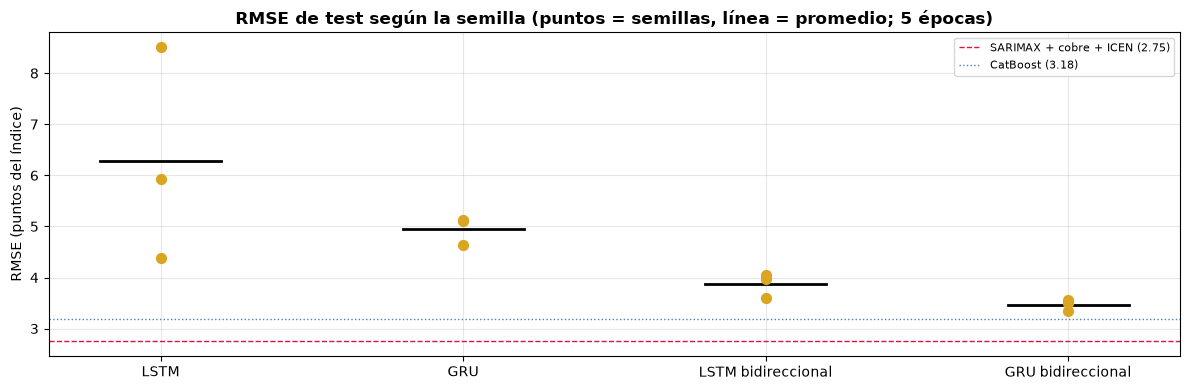

In [59]:
SEMILLAS = range(3)
conjunto_semillas = 'Sin exógenas'
v = ventanas_rnn[conjunto_semillas]
filas = []
for nombre, (tipo, bid) in arquitecturas.items():
    for semilla in SEMILLAS:
        if semilla == 0:   # la semilla 0 ya se entrenó en la sección 14.6
            pred = pronosticos_rnn[(conjunto_semillas, nombre)]
        else:
            set_random_seed(semilla)
            red = crear_red(tipo, bid, len(v['columnas']))
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                red.fit(v['x_train'], v['y_train'], batch_size=1, epochs=EPOCAS, verbose=0)
                pred = a_indice_ml(v['escalador_y'].inverse_transform(red.predict(v['x_test'], verbose=0))[:, 0])
        filas.append({'Modelo': nombre, 'Semilla': semilla, 'RMSE': np.sqrt(mean_squared_error(indice_test, pred)),
                      'MAPE (%)': metricas(indice_test, pred)['MAPE (%)'], 'pred': pred})
semillas_rnn = pd.DataFrame(filas)

rmse_sarimax = comparacion_final.loc['SARIMAX + cobre + ICEN', 'RMSE']
por_red = semillas_rnn.groupby('Modelo', sort=False)
resumen_semillas = por_red['RMSE'].agg(['mean', 'std', 'min', 'max'])
resumen_semillas.columns = ['RMSE promedio', 'Desv. estándar', 'RMSE mínimo', 'RMSE máximo']
resumen_semillas['MAPE promedio (%)'] = por_red['MAPE (%)'].mean()
resumen_semillas['Semillas que superan al SARIMAX'] = por_red['RMSE'].apply(lambda r: f'{(r < rmse_sarimax).sum()} de {len(r)}')
display(resumen_semillas.style.format('{:.4f}', subset=resumen_semillas.columns[:-1])
        .set_caption(f'RMSE de test con {len(SEMILLAS)} semillas - redes {conjunto_semillas.lower()} (SARIMAX: {rmse_sarimax:.4f})'))
display(semillas_rnn.pivot(index='Modelo', columns='Semilla', values='RMSE').loc[list(arquitecturas)]
        .rename(columns=lambda s: f'Semilla {s}').round(4))

# Ensamble de semillas: promedio de los pronósticos de cada red
ensamble_semillas = {f'{nombre} (promedio de {len(SEMILLAS)} semillas)':
                     pd.concat(list(semillas_rnn.loc[semillas_rnn['Modelo'] == nombre, 'pred']), axis=1).mean(axis=1)
                     for nombre in arquitecturas}
print('Ensamble de semillas:')
display(tabla_metricas(ensamble_semillas).round(4))

plt.figure(figsize=(12, 4))
for i, nombre in enumerate(arquitecturas, start=1):
    valores = semillas_rnn.loc[semillas_rnn['Modelo'] == nombre, 'RMSE']
    plt.scatter([i] * len(valores), valores, color='goldenrod', s=50, zorder=3)
    plt.plot([i - 0.2, i + 0.2], [valores.mean()] * 2, color='black', linewidth=2)
plt.xticks(range(1, len(arquitecturas) + 1), list(arquitecturas))
plt.axhline(rmse_sarimax, color='crimson', linestyle='--', linewidth=1, label=f'SARIMAX + cobre + ICEN ({rmse_sarimax:.2f})')
plt.axhline(comparacion_final.loc['CatBoost', 'RMSE'], color='steelblue', linestyle=':', linewidth=1,
            label=f"CatBoost ({comparacion_final.loc['CatBoost', 'RMSE']:.2f})")
plt.title(f'RMSE de test según la semilla (puntos = semillas, línea = promedio; {EPOCAS} épocas)', fontweight='bold')
plt.ylabel('RMSE (puntos del índice)'); plt.grid(alpha=0.3); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretación de la prueba de semillas**

- **La LSTM simple es muy inestable:** su RMSE va de 4,39 a 8,51 según la semilla (desviación estándar 2,08). Con 5 épocas, a veces alcanza a aprender la estacionalidad y a veces no. La semilla 0 fue su mejor resultado, así que la tabla de la sección 14.7 la favorece.
- **Las bidireccionales son estables:** la GRU bidireccional varía entre 3,34 y 3,56 (desviación 0,12) y la LSTM bidireccional entre 3,60 y 4,04 (desviación 0,24). La GRU bidireccional es la mejor red con las tres semillas, así que su ventaja no es fruto del azar.
- **Ninguna de las 12 redes supera al SARIMAX** (0 de 3 semillas en cada arquitectura).
- **Ensamble de semillas:** promediar los 3 pronósticos de la GRU bidireccional baja su RMSE a **3,17** (MAPE 1,23 %), mejor que cada una de sus semillas por separado y apenas por debajo de CatBoost (3,18). Promediar reduce la parte aleatoria del error, igual que el ensamble de *boosting* de la sección 10. En la LSTM simple el ensamble no alcanza (5,56) porque arrastra la semilla que no aprendió.

### 14.10. Comparación con todos los modelos

Se agregan las redes a la tabla consolidada de la sección 12: el mismo escenario (pronóstico a 1 mes del índice en los 55 meses del test) y las mismas métricas. Se incluyen las 8 redes entrenadas con la semilla 0 y los ensambles de semillas de la sección 14.9. El valor de AutoML corresponde a esta ejecución del notebook: como se explicó en la sección 11, varía un poco entre ejecuciones.

,Ranking,Tipo,AIC,BIC,p-Ljung-Box(24),¿Pasa Ljung–Box?,MSE,RMSE,MAE,MAPE (%),RMSE var. % (pp),IEC
Modelo,,,,,,,,,,,,
"SARIMAX(0, 1, 1)(0, 1, 1)12 + cobre + ICEN",1,Econometría,709.1056,726.2304,0.3006,Sí,7.5794,2.7531,2.1350,1.0468,1.3935,0.7024
"SARIMAX(0, 1, 1)(0, 1, 1)12 + cobre",2,Econometría,712.1295,725.8293,0.4683,Sí,7.6698,2.7694,2.1116,1.0361,1.3992,0.7017
"SARIMAX(0, 1, 1)(0, 1, 1)12 + ICEN",3,Econometría,711.2907,724.9905,0.3065,Sí,7.8385,2.7997,2.1691,1.0640,1.4177,0.7059
"SARIMA(0, 1, 1)(0, 1, 1)12",4,Econometría,714.9946,725.2694,0.4536,Sí,7.9847,2.8257,2.1527,1.0568,1.4278,0.7060
GRU bidireccional (promedio de 3 semillas),5,Deep Learning,—,—,—,—,10.0203,3.1655,2.4986,1.2342,1.6233,0.7339
CatBoost,6,Boosting,—,—,—,—,10.1180,3.1809,2.5738,1.2647,1.6204,0.7374
Ensamble,7,Boosting,—,—,—,—,10.4640,3.2348,2.6625,1.3059,1.6389,0.7425
AutoML (H2O),8,AutoML,—,—,—,—,11.1013,3.3319,2.6042,1.2815,1.7105,0.7427
GRU bidireccional (sin exógenas),9,Deep Learning,—,—,—,—,11.1410,3.3378,2.5579,1.2696,1.7287,0.7414


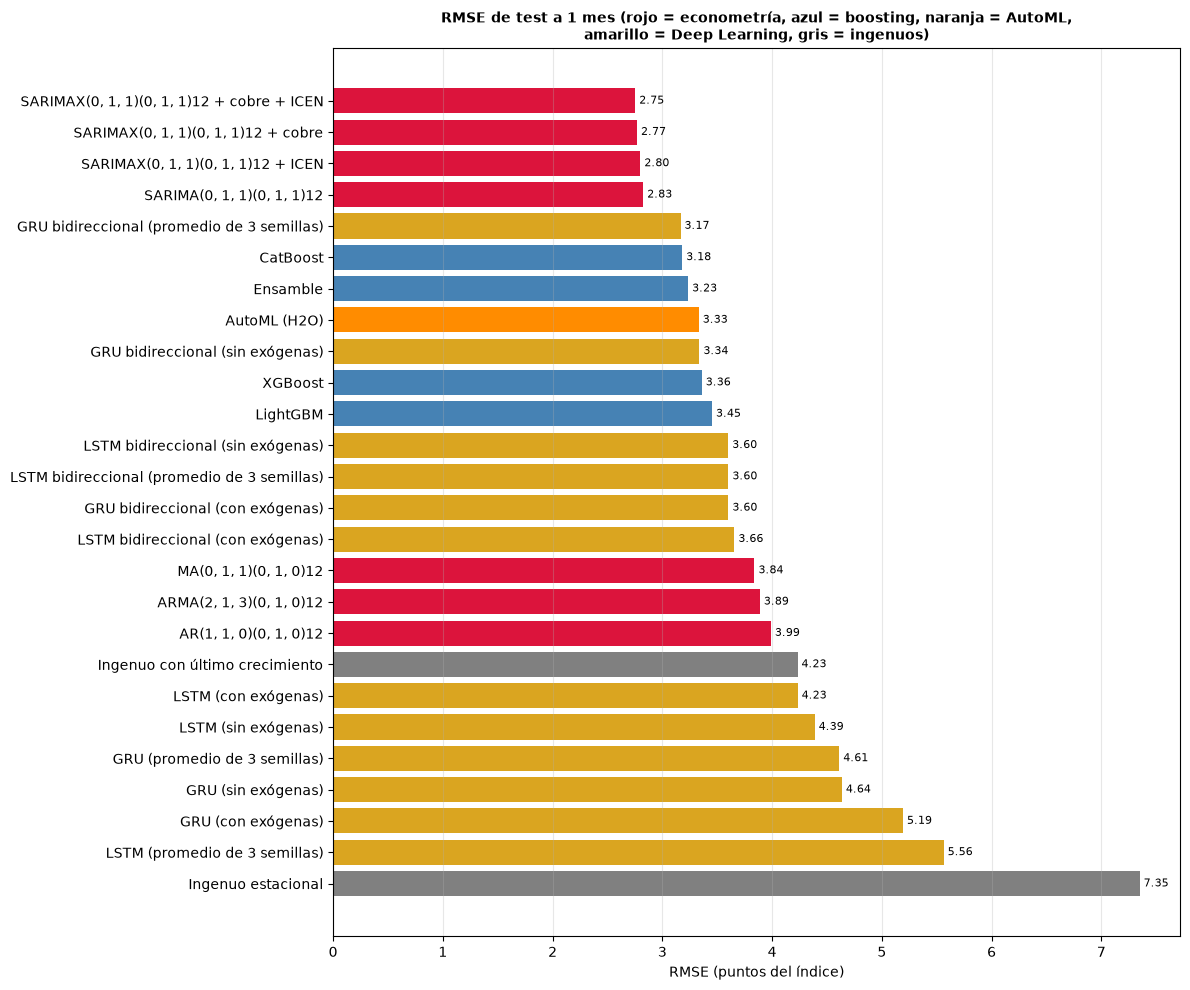

In [60]:
nombres_rnn = {(conjunto, nombre): f'{nombre} ({conjunto.lower()})' for conjunto, nombre in pronosticos_rnn}
todos_dl = {**{nombres_rnn[c]: p for c, p in pronosticos_rnn.items()}, **ensamble_semillas}
tabla_dl = tabla_metricas(todos_dl)
tabla_dl.insert(0, 'Tipo', 'Deep Learning')
consolidada_dl = pd.concat([consolidada.drop(columns='Ranking'), tabla_dl]).sort_values('RMSE')
consolidada_dl['¿Pasa Ljung–Box?'] = consolidada_dl['¿Pasa Ljung–Box?'].fillna('—')
consolidada_dl.insert(0, 'Ranking', range(1, len(consolidada_dl) + 1))
display(consolidada_dl.style
        .format('{:.4f}', subset=['AIC', 'BIC', 'p-Ljung-Box(24)'] + columnas_error, na_rep='—')
        .highlight_min(subset=columnas_error, color='#c6efce')
        .apply(lambda fila: ['background-color: #fff2cc' if fila['Tipo'] == 'Deep Learning' else '' for _ in fila], axis=1)
        .set_caption('Todos los modelos - test a 1 mes, métricas sobre el índice (amarillo = Deep Learning, verde = mejor valor)'))

colores_tipo['Deep Learning'] = 'goldenrod'
fig, ax = plt.subplots(figsize=(12, 10))
ax.barh(consolidada_dl.index, consolidada_dl['RMSE'], color=consolidada_dl['Tipo'].map(colores_tipo))
for i, valor in enumerate(consolidada_dl['RMSE']):
    ax.text(valor, i, f' {valor:.2f}', va='center', fontsize=8)
ax.invert_yaxis(); ax.grid(alpha=0.3, axis='x'); ax.set_xlabel('RMSE (puntos del índice)')
ax.set_title('RMSE de test a 1 mes (rojo = econometría, azul = boosting, naranja = AutoML,\namarillo = Deep Learning, gris = ingenuos)',
             fontweight='bold', fontsize=10)
plt.tight_layout(); plt.show()

**Diebold–Mariano** (sección 7): un estadístico negativo indica que el primer modelo tiene menor error cuadrático; la diferencia es significativa si p < 0,05. Se compara la mejor red con el SARIMAX, el SARIMA, CatBoost y el ingenuo con último crecimiento.

In [61]:
mejor_red = tabla_dl['RMSE'].idxmin()
rivales = {'SARIMAX + cobre + ICEN': pronosticos_1m[etiqueta_final], 'SARIMA': pronosticos_1m[etiqueta_sarima],
           'CatBoost': pronosticos_ml['CatBoost'], 'Ingenuo con último crecimiento': pronosticos_1m['Ingenuo con último crecimiento']}
dm_dl = []
for rival, pred_rival in rivales.items():
    dm, p = diebold_mariano(indice_test, todos_dl[mejor_red], pred_rival)
    dm_dl.append({'Comparación': f'{mejor_red} vs {rival}', 'Estadístico DM': dm, 'p-valor': p,
                  'Conclusión': 'Sin diferencia significativa' if p >= alpha else
                                'La red es significativamente mejor' if dm < 0 else f'{rival} es significativamente mejor'})
print('Mejor red (menor RMSE):', mejor_red)
display(pd.DataFrame(dm_dl).round(4))

Mejor red (menor RMSE): GRU bidireccional (promedio de 3 semillas)


,Comparación,Estadístico DM,p-valor,Conclusión
0,GRU bidireccional (promedio de 3 semillas) vs ...,1.6045,0.1086,Sin diferencia significativa
1,GRU bidireccional (promedio de 3 semillas) vs ...,1.3173,0.1877,Sin diferencia significativa
2,GRU bidireccional (promedio de 3 semillas) vs ...,-0.0551,0.9561,Sin diferencia significativa
3,GRU bidireccional (promedio de 3 semillas) vs ...,-1.6137,0.1066,Sin diferencia significativa


**Interpretación de la comparación con todos los modelos**

- **Los cuatro primeros puestos siguen siendo los modelos econométricos estacionales** (SARIMAX y SARIMA, RMSE 2,75 a 2,83). La mejor red, el **ensamble de 3 semillas de la GRU bidireccional**, queda **5.ª de 26** (RMSE 3,17), justo delante de CatBoost (3,18), el ensamble de *boosting* (3,23) y AutoML (3,33). Con una sola semilla, la GRU bidireccional queda 9.ª (3,34).
- Las bidireccionales (puestos 5, 9 y 12 a 15) superan a los AR, MA y ARMA sin parte estacional (3,84 a 3,99). Las LSTM y GRU simples (puestos 20 a 25) quedan por debajo del ingenuo con último crecimiento (4,23) y solo superan al ingenuo estacional (7,35).
- **Diebold–Mariano:** la diferencia entre la mejor red y el SARIMAX **no es significativa** (p = 0,11), aunque el estadístico positivo indica que el SARIMAX tiene menor error. Tampoco hay diferencia significativa con el SARIMA (p = 0,19), CatBoost (p = 0,96) ni el ingenuo con último crecimiento (p = 0,11). Con 55 meses de test, la prueba no alcanza a separar modelos con errores tan parecidos.
- **¿Por qué las redes no superan al SARIMAX?** Son las razones de la sección 12, pero más marcadas:
  1. **Pocos datos para muchos parámetros:** 215 muestras para redes de 32 mil (GRU) a 305 mil parámetros (LSTM bidireccional). El notebook 12 tenía 3 901 muestras.
  2. **Pocas épocas:** con 5 épocas, las redes simples no terminan de aprender y su resultado depende de la semilla.
  3. **Una estructura muy regular:** la tendencia y la estacionalidad de calendario las captura el SARIMA con dos parámetros MA; la red tiene que aprenderlas desde cero y las suaviza (febrero 2026).
- **Lo que sí aportó la sección:** la capa **bidireccional** fue la mejora más clara. Con las mismas 5 épocas, las bidireccionales dieron un RMSE de 3,3 a 4,0 con todas las semillas; las simples, de 4,4 a 8,5. Una posible explicación es que la dirección inversa termina en el mes más antiguo de la ventana, de modo que la información de hace 12 y 24 meses llega a la salida por un camino más corto.
- **Recomendación:** mantener el SARIMAX + cobre + ICEN como modelo principal. Entre las redes, la **GRU bidireccional sin exógenas con ensamble de semillas** es la única que compite con los modelos de Machine Learning. Para mejorarla se podría entrenar con más épocas y parada temprana (*early stopping*) sobre la validación, usar más historia (el índice existe desde 1994 y la red sin exógenas no necesita el cobre) o entrenarla sobre los residuos del SARIMAX (modelo híbrido).

### 14.11. Guardar y cargar el modelo para ponerlo en producción

Como en el notebook 12, se exporta la red con menor RMSE de la sección 14.6 para usarla, por ejemplo, detrás de una API. Se usa el formato nativo `.keras`: el notebook 12 guardaba en `.h5`, un formato que Keras ya considera antiguo (aparecía un aviso). Para pronosticar con la red cargada también hacen falta los **escaladores** ajustados con train, así que se guardan junto con ella.

In [62]:
clave_mejor = min(pronosticos_rnn, key=lambda c: metricas_rnn.loc[c, 'RMSE'])
v = ventanas_rnn[clave_mejor[0]]
redes_rnn[clave_mejor].save('modelo_rnn_electricidad_agua.keras')
joblib.dump({'escalador_x': v['escalador_x'], 'escalador_y': v['escalador_y'], 'columnas': v['columnas'], 'ventana': VENTANA},
            'escaladores_rnn_electricidad_agua.joblib')
print('Modelo guardado:', nombres_rnn[clave_mejor], '-> modelo_rnn_electricidad_agua.keras (+ escaladores_rnn_electricidad_agua.joblib)')

modelo_cargado = load_model('modelo_rnn_electricidad_agua.keras')
modelo_cargado.summary()
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    diferencia = np.abs(modelo_cargado.predict(v['x_test'], verbose=0) - redes_rnn[clave_mejor].predict(v['x_test'], verbose=0)).max()
print(f'Diferencia máxima entre la red original y la cargada: {diferencia:.1e}')

Modelo guardado: GRU bidireccional (sin exógenas) -> modelo_rnn_electricidad_agua.keras (+ escaladores_rnn_electricidad_agua.joblib)


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_12                │ (None, 24, 100)        │        16,500 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_13                │ (None, 128)            │        63,744 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 25)             │         3,225 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 250,487 (978.46 KB)

 Trainable params: 83,495 (326.15 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 166,992 (652.31 KB)

Diferencia máxima entre la red original y la cargada: 0.0e+00


## Conclusiones

1. **Transformación logarítmica:** se modeló el **índice** del PBI de Electricidad y Agua (2007 = 100) y no su variación %, porque el logaritmo solo existe para valores positivos. El logaritmo estabilizó la varianza: la correlación entre el nivel y la dispersión anual bajó de 0,86 a −0,33. Además permite leer las diferencias como tasas de crecimiento y garantiza pronósticos positivos.
2. **Diferenciación:** la serie en logaritmos requiere **una diferencia regular y una estacional (d = 1, D = 1)**. Con una sola diferencia, la FAC del rezago 12 seguía en 0,87 (estacionalidad no estacionaria). La decisión se tomó con tres criterios: ADF, KPSS y FAC del rezago 12.
3. **Pandemia:** se imputó interpolando el nivel desestacionalizado, para que empalme con los datos reales. Imputar con el crecimiento "normal" de cada mes habría creado un salto artificial, porque el sector nunca recuperó los dos años de crecimiento perdidos.
4. **Identificación (Box-Jenkins):** el mejor modelo univariado es el **"modelo de aerolínea" SARIMA(0,1,1)(0,1,1)₁₂**, tal como sugerían la FAC y la FACP. Los modelos AR, MA y ARMA sin términos estacionales no son válidos, porque sus residuos tienen autocorrelación.
5. **Variables exógenas:**
   - El **precio del cobre** aumenta el nivel del sector con **7 meses de rezago** (elasticidad ≈ +0,02).
   - El **ICEN** lo reduce con **10 meses de rezago** (≈ −0,4 % por cada °C).
   - Ambos signos tienen sentido económico y ninguna de las dos variables forma parte del cálculo del PBI sectorial. Su elección está respaldada por fuentes oficiales (sección 6.2): la minería llegó a representar el 34,1 % del consumo eléctrico total (BCRP) y El Niño costero de 2017 redujo la producción de agua en 8,18 % (INEI). Con toda la muestra, las dos son significativas al 5 %.
   - Los rezagos se eligieron probando 13 opciones por variable, lo que puede exagerar la significancia. Que ambos efectos se mantengan al reestimar con toda la serie respalda la relación.
6. **Modelo final:** el **SARIMAX(0,1,1)(0,1,1)₁₂ + cobre(t−7) + ICEN(t−10)** tiene el menor AIC y residuos sin autocorrelación. Por BIC el mejor sería el SARIMAX solo con ICEN, pero las diferencias de BIC entre los modelos estacionales son menores a 2 puntos; se prefiere el AIC porque el objetivo es pronosticar. Sus residuos no tienen varianza constante (ARCH) ni son normales, así que los intervalos deben leerse como aproximados.
7. **Precisión:**
   - A 1 mes tiene el menor RMSE (2,75 puntos) y el menor error en la variación interanual (**1,39 pp**), con **MAPE 1,05 %** sobre el índice. Supera de forma significativa a los modelos ingenuos; frente al SARIMA y al SARIMAX solo con cobre la diferencia es mínima (el de solo cobre tiene un MAPE apenas menor, 1,04 %).
   - A varios años sobreestima el nivel, porque el sector creció en 2022–2026 menos que en su historia, y en ese horizonte su error en la variación interanual (2,49 pp) no es el menor.
   - Transformar con logaritmo y modelar el índice redujo el error de la variación interanual a 1 mes en ≈ 34 % (de 2,11 a 1,39 pp) frente a la versión anterior de este trabajo, que modelaba directamente la variación %.
8. **Próximos 12 meses:** se espera un crecimiento de 7,9 % en agosto 2026 que baja a ≈ 2,3 % en julio 2027. La desaceleración de 2027 es mayor que la de un SARIMA sin exógenas por el **El Niño Costero fuerte de 2026**. Es una alerta temprana útil para planificar la inversión y el mantenimiento de la infraestructura eléctrica y de agua. Los intervalos son amplios, así que conviene usar el rango y actualizar el modelo cada mes con el dato real del PBI, el cobre y el pronóstico del ENFEN.

9. **Cuartiles y deciles:**
   - La variación % interanual tiene mediana 5,0 % y su 50 % central está entre 3,1 % y 6,8 %.
   - La regla 1,5·IQR detecta 12 meses atípicos, 11 de ellos en la pandemia, lo que respalda la imputación de la sección 3.1. Aplicada al índice en niveles no detecta nada: en series con tendencia los cuantiles deben usarse sobre la versión estacionaria.
   - Los cuartiles por mes muestran que la estacionalidad es sobre todo un efecto calendario: febrero y los meses de 30 días caen.
   - En julio 2026 el ICEN y el cobre están en el decil 10, en valores extremos.
10. **Machine Learning con las variables del notebook 01:**
    - El índice y sus medias móviles en nivel no sirven para árboles: en el test superan el máximo de train y los árboles no extrapolan. Por eso se modeló `Log_Return` con `Retorno`, `Cambio`, las medias móviles relativas y los rezagos.
    - CatBoost fue el mejor (RMSE 3,18; MAPE 1,26 %), seguido del ensamble, XGBoost y LightGBM. La variable clave es `lag_12`, el crecimiento del mismo mes del año anterior.
11. **AutoML frente a XGBoost, LightGBM y CatBoost:**
    - H2O AutoML (líder: Stacked Ensemble) logró un RMSE de 3,32 y un MAPE de 1,30 %, sin diferencias significativas con los tres modelos de boosting.
    - Ningún modelo de Machine Learning superó al **SARIMAX + cobre + ICEN**, que sigue siendo el mejor a 1 mes (su ventaja es significativa frente al ensamble). En una serie mensual corta y regular, el modelo econométrico es más preciso y además interpretable.
12. **Detección de anomalías con Isolation Forest (H2O):**
    - Usar el nivel del índice, como en el ejemplo de Bitcoin, no funciona: ningún mes de la pandemia entra al top 5 % y 13 de 15 meses señalados están en los extremos de la muestra por la tendencia. Con la variación interanual por día y el crecimiento mensual sin estacionalidad, 10 de los 15 meses señalados son de la pandemia y los 16 meses de la pandemia quedan en los deciles 8 a 10.
    - Fuera de la pandemia, el modelo señala febrero de 2016 (el año bisiesto explica solo parte de su +14,2 %), marzo de 2017 (mes del máximo del ICEN), diciembre de 2015, agosto de 2009 y marzo de 2024. Son meses para revisar y no para eliminar.
    - Con la serie imputada ningún mes de la pandemia queda en el top 5 %, lo que respalda la imputación de la sección 3.1.
    - El modelo es inestable entre semillas (ningún mes aparece en las 10), por lo que se usa el score promedio y los deciles en lugar de una lista exacta.

13. **Deep Learning (LSTM, GRU y bidireccionales, notebook 12):**
    - El notebook 12 se adaptó a esta serie: objetivo `Log_Return` (el índice en nivel no extrapola), escaladores ajustados solo con train, ventana de 24 meses, el mes del año como seno y coseno (elegido con una validación 2017–2019) y 5 épocas con `batch_size=1`, en GPU.
    - Con 5 épocas, solo las **bidireccionales** aprenden de forma estable la estacionalidad. La mejor red es la **GRU bidireccional sin exógenas** (RMSE 3,34; MAPE 1,27 %); con un ensamble de 3 semillas llega a 3,17, el 5.º lugar entre 26 modelos, delante de CatBoost (3,18). La LSTM y la GRU simples son inestables (la LSTM varía entre 4,4 y 8,5 según la semilla) y no superan al ingenuo con último crecimiento.
    - El cobre y el ICEN no mejoraron a las redes, en línea con su efecto pequeño en el SARIMAX.
    - **Ninguna red superó al SARIMAX + cobre + ICEN** (RMSE 2,75), aunque la diferencia con la mejor red no es significativa (Diebold–Mariano p = 0,11). Con 215 muestras de entrenamiento y una estacionalidad tan regular, el modelo econométrico sigue siendo el más preciso y además es interpretable.